# 02 — Controlled Missing Value Imputation

**HCMUS — Data Mining and Applications.** This chapter implements only the missing-value
comparison in the [official assignment](https://hcmus-cs-ta.github.io/lab-book/data-mining/projects/preprocessing/):
mean, median, mode, kNN with k=3/5/10, and MICE. These are **seven configurations in five families**.
The input is [WiDS 2024 Challenge #1](https://www.kaggle.com/competitions/widsdatathon2024-challenge1/data).

## 1. Objective and scientific scope

This is a **retrospective imputation-method benchmark**, reconstructing deliberately hidden,
originally observed numerical measurements. It is not a prospective clinical prediction model.
The completed EDA already examined all labeled rows: every split here is a **post-EDA internal
assessment**, not an untouched external test. No target, ID, ZIP, diagnosis or treatment field
enters an imputer. BMI is documented post-metastatic and remains ineligible for an earlier
baseline unless that prediction question is explicitly changed; benchmarking its reconstruction
does not approve it as a predictor. Natural MCAR/MAR/MNAR remains unidentified.

**Protocol fixed before scoring:** six named numerical variables below; ZIP-disjoint outer 20%
group reserve, inner 25% development-group validation; seeds 42/43; mask seed 2024; floor(10% of
observed validation cells) independently sampled within each feature; same positions for all
methods. All inner-training rows are used, retaining their natural NaNs.

**Primary selection criterion:** lowest macro standardized RMSE, giving each of six features
equal weight and using inner-training SDs only. For MICE, use the mean of this metric over three
posterior completed tables, seeds 101/102/103, ten rounds each. Raw pooled RMSE is reported but
does not select the winner. Exact ties follow the displayed order (simple baselines first).
No seed/subset/criterion is searched after seeing scores. The outer reserve is never scored.

**Coverage extension:** Sections 1–9 retain the original six-feature experiment at commit
`ac8f7bb`; Sections 10–15 add a separate joint numerical benchmark. The original scores and
per-feature results are preserved and checked after re-execution; runtime measurements are
refreshed by Run All (the original timings remain in the dated audit). More extensive coverage
is our scientific extension, **not an explicit requirement to use all 69 features in the rubric**.
Do not rank aggregate errors across the two different feature matrices/masks.


In [1]:
from pathlib import Path
import hashlib
import platform
import sys
from importlib.metadata import version
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML
from sklearn import config_context
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.experimental import enable_iterative_imputer  # Enables the documented experimental API.
from sklearn.impute import IterativeImputer

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "myst.yml").is_file() and (p / "src/validate_dataset.py").is_file()), None)
if ROOT is None or Path(sys.prefix) != ROOT / ".venv":
    raise RuntimeError("Start inside the repository and select its .venv kernel (hcmus-wids).")
DATA_PATH = ROOT / "data/raw/training.csv"
ID, TARGET, ZIP = "patient_id", "DiagPeriodL90D", "patient_zip3"
FEATURES = ["patient_age", "bmi", "density", "income_household_median",
            "education_college_or_above", "PM25"]
OUTER_SEED, INNER_SEED, MASK_SEED = 42, 43, 2024
MASK_RATE = 0.10
MICE_SEEDS = [101, 102, 103]
MICE_SETTINGS = dict(sample_posterior=True, max_iter=10, initial_strategy="mean",
                     imputation_order="ascending", n_nearest_features=None,
                     skip_complete=False, keep_empty_features=True)
METHOD_ORDER = ["Mean", "Median", "Mode", "kNN (k=3)", "kNN (k=5)", "kNN (k=10)", "MICE (m=3)"]
KNN_MEMORY_MIB = 128
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 140})
print(f"Python {platform.python_version()}; kernel verified: .venv/bin/python")
display(pd.Series({p: version(p) for p in ["numpy", "pandas", "scipy", "scikit-learn"]}, name="version").to_frame())

Python 3.13.3; kernel verified: .venv/bin/python


,version
numpy,2.5.4
pandas,3.1.0
scipy,1.18.1
scikit-learn,1.9.1


## 2. Loading, measurement eligibility and grouped separation

The six variables were selected for interpretation and feasibility before scoring: individual
age/BMI, skewed area density, monetary household income, a bounded education proportion, and
annual air-quality context. This covers different scales and heavy BMI missingness without
including entire redundant share blocks. The ranking is **only for these six variables**, not
all 69 numerical candidates. Shared ZIP context and unknown source periods remain limitations.

The source dictionary/timing audit is in [Stage 01](01_eda.ipynb). This chapter preserves the raw
CSV, full frame and reference measurements. Numerical storage does not authorize clinical
codes or ZIPs as continuous measurements. The other numerical columns are excluded for scope,
redundancy risk and compute, not because their imputation scores were unfavorable. These exclusions apply only to the representative experiment; Section 10 accounts for
all 69 numerical candidates. Categorical handling/encoding is outside numerical RMSE.

In [2]:
if not DATA_PATH.is_file():
    raise FileNotFoundError("Obtain the official training.csv locally; follow README/Stage 01 preparation.")
raw_sha_before = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
df = pd.read_csv(DATA_PATH, dtype={ZIP: "string"})
assert df.shape == (12906, 83)
assert df.columns.is_unique and df[ID].notna().all() and df[ID].is_unique
assert df[ZIP].notna().all() and df[TARGET].notna().all() and set(df[TARGET].unique()) == {0, 1}
frame_hash_before = hashlib.sha256(pd.util.hash_pandas_object(df, index=True).to_numpy().tobytes()).hexdigest()
dtypes_before, shape_before, columns_before = df.dtypes.copy(), df.shape, df.columns.copy()

clinical_fields = {"breast_cancer_diagnosis_code", "breast_cancer_diagnosis_desc",
                   "metastatic_cancer_diagnosis_code", "metastatic_first_novel_treatment",
                   "metastatic_first_novel_treatment_type"}
forbidden = clinical_fields | {ID, TARGET, ZIP, "patient_state", "Region", "Division",
                               "patient_race", "payer_type", "patient_gender"}
numerical_candidates = [c for c in df.select_dtypes("number") if c not in forbidden]
assert len(numerical_candidates) == 69 and len(FEATURES) == len(set(FEATURES)) == 6
assert set(FEATURES).issubset(numerical_candidates) and set(FEATURES).isdisjoint(forbidden)
assert np.isfinite(df[FEATURES].to_numpy()[df[FEATURES].notna().to_numpy()]).all()
feature_audit = pd.DataFrame({
    "Feature": FEATURES,
    "Role": ["Individual age", "Individual BMI", "Area density", "Area household income",
             "Area percentage", "Annual ZIP3 air concentration"],
    "Observed N (whole file)": df[FEATURES].count().to_numpy(),
    "Missing % (whole file)": df[FEATURES].isna().mean().mul(100).to_numpy(),
    "Timing / interpretation limit": ["Index/baseline alignment unverified", "Documented post-metastatic",
        "Area/reference period unverified", "Area, not personal income; period unverified",
        "Bounded share; period unverified", "Units/year unverified"],
})
display(feature_audit.round(4))
excluded_numeric = [c for c in numerical_candidates if c not in FEATURES]
excluded_categories = [c for c in df if c not in numerical_candidates and c not in {ID, TARGET}]
exclusions = pd.DataFrame([
    {"Group": "ID and target", "N": 2, "Columns": [ID, TARGET], "Reason": "Identification/outcome; never imputation predictors"},
    {"Group": "Categorical/code/text", "N": len(excluded_categories), "Columns": excluded_categories,
     "Reason": "No meaningful continuous RMSE; includes ZIP, diagnosis and treatment"},
    {"Group": "Other numerical candidates", "N": len(excluded_numeric), "Columns": excluded_numeric,
     "Reason": "Compact predeclared benchmark; not a score-based feature selection"},
])
display(HTML("<details><summary>Complete exclusions and reasons</summary>" + exclusions.to_html(index=False) + "</details>"))
print("Input SHA-256:", raw_sha_before)

,Feature,Role,Observed N (whole file),Missing % (whole file),Timing / interpretation limit
0,patient_age,Individual age,12906,0.0000,Index/baseline alignment unverified
1,bmi,Individual BMI,3941,69.4638,Documented post-metastatic
2,density,Area density,12905,0.0077,Area/reference period unverified
3,income_household_median,Area household income,12902,0.0310,"Area, not personal income; period unverified"
4,education_college_or_above,Area percentage,12905,0.0077,Bounded share; period unverified
5,PM25,Annual ZIP3 air concentration,12877,0.2247,Units/year unverified


Group,N,Columns,Reason
ID and target,2,"[patient_id, DiagPeriodL90D]",Identification/outcome; never imputation predictors
Categorical/code/text,12,"[patient_race, payer_type, patient_state, patient_zip3, patient_gender, breast_cancer_diagnosis_code, breast_cancer_diagnosis_desc, metastatic_cancer_diagnosis_code, metastatic_first_novel_treatment, metastatic_first_novel_treatment_type, Region, Division]","No meaningful continuous RMSE; includes ZIP, diagnosis and treatment"
Other numerical candidates,63,"[population, age_median, age_under_10, age_10_to_19, age_20s, age_30s, age_40s, age_50s, age_60s, age_70s, age_over_80, male, female, married, divorced, never_married, widowed, family_size, family_dual_income, income_household_under_5, income_household_5_to_10, income_household_10_to_15, income_household_15_to_20, income_household_20_to_25, income_household_25_to_35, income_household_35_to_50, income_household_50_to_75, income_household_75_to_100, income_household_100_to_150, income_household_150_over, income_household_six_figure, income_individual_median, home_ownership, housing_units, home_value, rent_median, rent_burden, education_less_highschool, education_highschool, education_some_college, education_bachelors, education_graduate, education_stem_degree, labor_force_participation, unemployment_rate, self_employed, farmer, race_white, race_black, race_asian, race_native, race_pacific, race_other, race_multiple, hispanic, disabled, poverty, limited_english, commute_time, health_uninsured, veteran, Ozone, N02]",Compact predeclared benchmark; not a score-based feature selection


Input SHA-256: e9947ecfe1cdacafbf9cbcdc0abd024396f617c701b056fa54e5881f1bb9bbe9


**Split protocol:** `GroupShuffleSplit(test_size=.20, random_state=42)` reserves ZIP groups for
later assessment. Within the remaining development groups, `test_size=.25, random_state=43`
defines imputation validation. Fractions refer to groups, not rows. Target distributions below
are diagnostics only; labels never enter the feature matrices, masks, scaler or imputers.
No stratification/seed search is performed. Both-class support and ID/ZIP separation are checked.

In [3]:
development_pos, reserved_pos = next(GroupShuffleSplit(n_splits=1, test_size=.20, random_state=OUTER_SEED)
                                     .split(df, groups=df[ZIP]))
development_index = df.index[development_pos]
reserved_index = df.index[reserved_pos]
development_groups = df.loc[development_index, ZIP]
train_pos, validation_pos = next(GroupShuffleSplit(n_splits=1, test_size=.25, random_state=INNER_SEED)
                               .split(development_index, groups=development_groups))
train_index, validation_index = development_index[train_pos], development_index[validation_pos]
partitions = {"Inner train": train_index, "Imputation validation": validation_index,
              "Reserved assessment": reserved_index}
split_rows = []
for name, index in partitions.items():
    part = df.loc[index]
    labels = part[TARGET].value_counts().reindex([0, 1], fill_value=0)
    assert (labels > 0).all() and part[ID].is_unique
    split_rows.append({"Partition": name, "Rows": len(index), "ZIP groups": part[ZIP].nunique(),
                       "Class0 N": int(labels.loc[0]), "Class1 N": int(labels.loc[1]),
                       "Class1 %": labels.loc[1] / len(index) * 100})
display(pd.DataFrame(split_rows).round(3))
overlaps = []
names = list(partitions)
for i, left in enumerate(names):
    for right in names[i+1:]:
        a, b = partitions[left], partitions[right]
        counts = {"Row overlap": len(set(a) & set(b)),
                  "ID overlap": len(set(df.loc[a, ID]) & set(df.loc[b, ID])),
                  "ZIP overlap": len(set(df.loc[a, ZIP]) & set(df.loc[b, ZIP]))}
        assert all(v == 0 for v in counts.values())
        overlaps.append({"Pair": f"{left} / {right}", **counts})
display(pd.DataFrame(overlaps))
assert sum(len(i) for i in partitions.values()) == len(df)
X_train = df.loc[train_index, FEATURES].copy(deep=True)
X_validation_reference = df.loc[validation_index, FEATURES].copy(deep=True)
train_hash_before = hashlib.sha256(pd.util.hash_pandas_object(X_train, index=True).to_numpy().tobytes()).hexdigest()
reference_hash_before = hashlib.sha256(pd.util.hash_pandas_object(X_validation_reference, index=True).to_numpy().tobytes()).hexdigest()
assert (X_train.count() >= 2).all() and (X_validation_reference.count() >= 10).all()
assert X_train.index.intersection(reserved_index).empty
distance_mib = len(X_train) * len(X_validation_reference) * np.dtype("float64").itemsize / 1024**2
print(f"Six-column training matrix: {X_train.shape}; validation: {X_validation_reference.shape}.")
print(f"One dense float64 validation×train distance array ≈{distance_mib:.2f} MiB.")
print(f"kNN uses sklearn working_memory={KNN_MEMORY_MIB} MiB for chunking; intermediate allocations can add overhead.")
print("All inner-training rows are used. The reserved partition is never imputed/scored for selection.")
observed_train = X_train.notna().astype(int)
joint_observed = observed_train.T @ observed_train
print(f"Training complete cases: {X_train.dropna().shape[0]}; minimum pairwise observed support: {joint_observed.to_numpy().min()}.")

,Partition,Rows,ZIP groups,Class0 N,Class1 N,Class1 %
0,Inner train,8173,443,3064,5109,62.511
1,Imputation validation,2081,148,778,1303,62.614
2,Reserved assessment,2652,148,1004,1648,62.142


,Pair,Row overlap,ID overlap,ZIP overlap
0,Inner train / Imputation validation,0,0,0
1,Inner train / Reserved assessment,0,0,0
2,Imputation validation / Reserved assessment,0,0,0


Six-column training matrix: (8173, 6); validation: (2081, 6).
One dense float64 validation×train distance array ≈129.76 MiB.
kNN uses sklearn working_memory=128 MiB for chunking; intermediate allocations can add overhead.
All inner-training rows are used. The reserved partition is never imputed/scored for selection.
Training complete cases: 2526; minimum pairwise observed support: 2526.


## 3. Controlled 10% masking and predeclared evaluation

For feature j, let $O_j$ be originally observed validation cells. Uniformly choose
$\lfloor0.10|O_j|\rfloor$ positions without replacement using seed 2024. Sampling is independent
of numerical values and target, conditional on being observed: fixed-count **MCAR by construction
over eligible cells**, not evidence of natural MCAR. Natural NaNs stay NaN. Training retains its
natural missingness; only the validation copy receives artificial gaps. All configurations and
MICE draws use the identical mask and original ground truth.

$$
\operatorname{RMSE}_j=\sqrt{\frac{1}{|M_j|}\sum_{i\in M_j}(x_{ij}-\hat x_{ij})^2},\qquad
\operatorname{RMSE}_{pooled}=\sqrt{\frac{1}{|M|}\sum_{(i,j)\in M}(x_{ij}-\hat x_{ij})^2}.
$$

Raw pooled RMSE mixes units and is income-scale sensitive. For the **primary** equal-feature score:

$$
\operatorname{macroNRMSE}=\frac1p\sum_{j=1}^p\frac{\operatorname{RMSE}_j}{s_{j,train}},\qquad
s_{j,train}=\sqrt{\frac1{n_{j,train}}\sum_{i\in O_{j,train}}(x_{ij}-\bar x_{j,train})^2}.
$$

SD uses ddof 0 and observed training values only (StandardScaler's convention). Unsupported or
zero-SD columns are errors, not silently dropped. For MICE the displayed RMSE/NRMSE is the mean
of three draw-level scores, with sample SD; it is **not** RMSE of averaged imputed values and not
Rubin-rule inferential pooling. Selection never switches to the more favorable secondary metric.
The two small functions below centralize mask/scoring invariants across all seven methods.

In [4]:
def make_mcar_mask(frame, rate=.10, random_state=2024):
    """Uniform fixed-count masking of observed cells, separately per ordered feature."""
    if not 0 < rate < 1 or not frame.index.is_unique or not frame.columns.is_unique:
        raise ValueError("Need unique axes and a masking rate strictly between 0 and 1")
    rng = np.random.default_rng(random_state)
    mask = pd.DataFrame(False, index=frame.index, columns=frame.columns)
    for column in frame:
        eligible = frame.index[frame[column].notna()].to_numpy()
        n_masked = int(np.floor(rate * len(eligible)))
        if n_masked < 1:
            raise ValueError(f"Insufficient observed support for masking: {column}")
        mask.loc[rng.choice(eligible, size=n_masked, replace=False), column] = True
    return mask


def score_masked(reference, completed, mask, train_sd):
    """Score only masked known cells; preserve labels/order and reject invalid predictions."""
    if not (completed.index.equals(reference.index) and mask.index.equals(reference.index)
            and completed.columns.equals(reference.columns) and mask.columns.equals(reference.columns)
            and train_sd.index.equals(reference.columns)):
        raise ValueError("Feature/index alignment mismatch")
    selected = mask.to_numpy(dtype=bool)
    if (selected & reference.isna().to_numpy()).any() or not selected.any():
        raise ValueError("Ground truth must be originally observed masked cells only")
    scale = train_sd.to_numpy(dtype=float)
    if not (np.isfinite(scale).all() and (scale > 0).all()):
        raise ValueError("Training SD must be positive and finite")
    truth, predicted = reference.to_numpy(float), completed.to_numpy(float)
    reconstructed_n = int(np.isfinite(predicted[selected]).sum())
    if reconstructed_n != int(selected.sum()) or not np.isfinite(truth[selected]).all():
        raise ValueError("Invalid ground truth or nonfinite scored prediction")
    residual = predicted - truth
    per_feature = []
    for j, column in enumerate(reference.columns):
        errors = residual[selected[:, j], j]
        if not len(errors):
            raise ValueError(f"No evaluation cells for {column}")
        per_feature.append(float(np.sqrt(np.mean(errors**2))))
    per_feature = pd.Series(per_feature, index=reference.columns, name="RMSE")
    return {"RMSE": float(np.sqrt(np.mean(residual[selected]**2))),
            "Normalized RMSE": float((per_feature / train_sd).mean()),
            "Masked N": int(selected.sum()), "Reconstructed N": reconstructed_n,
            "per_feature": per_feature}

print("Masking and scoring functions defined; independent synthetic checks follow in Section 9.")

Masking and scoring functions defined; independent synthetic checks follow in Section 9.


In [5]:
evaluation_mask = make_mcar_mask(X_validation_reference, MASK_RATE, MASK_SEED)
pd.testing.assert_frame_equal(evaluation_mask, make_mcar_mask(X_validation_reference, MASK_RATE, MASK_SEED))
assert not (evaluation_mask & X_validation_reference.isna()).to_numpy().any()
X_validation_masked = X_validation_reference.mask(evaluation_mask)
pd.testing.assert_frame_equal(X_validation_masked.where(~evaluation_mask),
                              X_validation_reference.where(~evaluation_mask))
assert (X_validation_masked.isna().sum() == X_validation_reference.isna().sum() + evaluation_mask.sum()).all()
mask_hash = hashlib.sha256(pd.util.hash_pandas_object(evaluation_mask, index=True).to_numpy().tobytes()).hexdigest()
mask_audit = pd.DataFrame({"Training observed N": X_train.count(),
                           "Validation observed eligible N": X_validation_reference.count(),
                           "Validation natural NaN N": X_validation_reference.isna().sum(),
                           "Artificial masked N": evaluation_mask.sum()})
mask_audit["Actual masked % of eligible"] = mask_audit["Artificial masked N"] / mask_audit["Validation observed eligible N"] * 100
assert (mask_audit["Artificial masked N"] == np.floor(MASK_RATE * mask_audit["Validation observed eligible N"])).all()
display(mask_audit.round(4))
print("Same evaluation-mask SHA-256 for all configurations:", mask_hash)

# Internal conditioning only; not the separate scaling-comparison rubric.
conditioning_start = perf_counter()
distance_scaler = StandardScaler(copy=True).fit(X_train)
training_sd = X_train.std(ddof=0)
assert (training_sd > 0).all() and np.isfinite(training_sd).all()
np.testing.assert_allclose(distance_scaler.mean_, X_train.mean().to_numpy())
np.testing.assert_allclose(distance_scaler.scale_, training_sd.to_numpy())
np.testing.assert_array_equal(np.broadcast_to(distance_scaler.n_samples_seen_, (len(FEATURES),)), X_train.count().to_numpy())
train_z = pd.DataFrame(distance_scaler.transform(X_train), index=X_train.index, columns=FEATURES)
validation_z = pd.DataFrame(distance_scaler.transform(X_validation_masked), index=X_validation_masked.index, columns=FEATURES)
np.testing.assert_allclose(distance_scaler.inverse_transform(validation_z), X_validation_masked.to_numpy(), equal_nan=True)
conditioning_seconds = perf_counter() - conditioning_start
display(pd.DataFrame({"Train mean": distance_scaler.mean_, "Train SD (ddof 0)": training_sd}, index=FEATURES))
print(f"Shared train-only conditioning: {conditioning_seconds:.4f}s (separate from each method's fit+transform time).")

,Training observed N,Validation observed eligible N,Validation natural NaN N,Artificial masked N,Actual masked % of eligible
patient_age,8173,2081,0,208,9.9952
bmi,2531,639,1442,63,9.8592
density,8173,2080,1,208,10.0000
income_household_median,8173,2077,4,207,9.9663
education_college_or_above,8173,2080,1,208,10.0000
PM25,8148,2079,2,207,9.9567


Same evaluation-mask SHA-256 for all configurations: d4e1ced320653122022edadea5bac1d443271af2fccfdd26efb7db5842c8e22e


,Train mean,Train SD (ddof 0)
patient_age,59.100575,13.258839
bmi,28.888163,5.797514
density,1336.089690,1894.117454
income_household_median,75295.676119,18697.794288
education_college_or_above,31.803267,10.909926
PM25,7.530382,1.533624


Shared train-only conditioning: 0.0046s (separate from each method's fit+transform time).


## 4. Mean, Median and Mode baselines

SimpleImputer learns one statistic from each column's **observed inner-training values**:

$$
\hat x_{ij}^{mean}=\bar x_{j,train},\qquad
\hat x_{ij}^{median}=\operatorname{median}(X_{j,train}^{obs}),\qquad
\hat x_{ij}^{mode}=\operatorname{mode}(X_{j,train}^{obs}).
$$

Mean is sensitive to tails; median is relatively robust. Mode is included as a **numerical**
baseline required by the rubric: sklearn chooses the smallest value when counts tie. For
continuous measurements it depends on precision/ties and is not a conditional predictor.
Categorical mode could be evaluated with classification-style measures separately; categorical
codes are not given numerical RMSE here. All three operate in original units with no validation fit.

In [6]:
evaluation_rows, per_feature_scores, completed_values, fitted_imputers = [], {}, {}, {}
fit_rows, mask_hashes = {}, {}
for method, strategy in [("Mean", "mean"), ("Median", "median"), ("Mode", "most_frequent")]:
    start = perf_counter()
    imputer = SimpleImputer(strategy=strategy, copy=True, keep_empty_features=True).fit(X_train)
    completed = pd.DataFrame(imputer.transform(X_validation_masked), index=validation_index, columns=FEATURES)
    elapsed = perf_counter() - start
    np.testing.assert_array_equal(imputer.feature_names_in_, FEATURES)
    if strategy == "mean":
        np.testing.assert_allclose(imputer.statistics_, X_train.mean().to_numpy())
    elif strategy == "median":
        np.testing.assert_allclose(imputer.statistics_, X_train.median().to_numpy())
    else:
        expected_modes = X_train.mode(dropna=True).iloc[0].to_numpy()
        np.testing.assert_allclose(imputer.statistics_, expected_modes)
    score = score_masked(X_validation_reference, completed, evaluation_mask, training_sd)
    evaluation_rows.append({"Method": method, "Parameters": f"strategy={strategy}; training-only",
                            **{k: score[k] for k in ["Masked N", "Reconstructed N", "RMSE", "Normalized RMSE"]},
                            "RMSE draw SD": 0., "Normalized draw SD": 0., "Draws": 1,
                            "Runtime (s)": elapsed, "Status": "PASS"})
    per_feature_scores[method] = score["per_feature"]
    completed_values[method], fitted_imputers[method] = [completed], [imputer]
    fit_rows[method], mask_hashes[method] = len(X_train), mask_hash
display(pd.DataFrame(evaluation_rows)[["Method", "RMSE", "Normalized RMSE", "Runtime (s)"]].round(5))
mode_audit = pd.DataFrame({"Training mode": fitted_imputers["Mode"][0].statistics_,
    "Tied modal values N": [int((X_train[c].value_counts() == X_train[c].value_counts().max()).sum()) for c in FEATURES]}, index=FEATURES)
display(mode_audit)

,Method,RMSE,Normalized RMSE,Runtime (s)
0,Mean,10781.65647,1.08081,0.00129
1,Median,10811.53806,1.09145,0.00357
2,Mode,11130.57141,1.65760,0.00318


,Training mode,Tied modal values N
patient_age,63.000000,1
bmi,27.000000,1
density,5294.330882,1
income_household_median,69266.693550,1
education_college_or_above,37.575385,1
PM25,11.166898,1


The numerical outputs above measure reconstruction, not downstream prediction. Each baseline
replaces a missing column entry with a single training statistic; it cannot exploit another
feature's information. Inspect modal ties rather than assuming that a numerical mode is stable.
The final comparison keeps these baselines even if a more complex method scores better.

## 5. kNN: k=3,5,10 with train-fitted distance conditioning

For jointly observed coordinates $A_{ir}$ among p standardized features, sklearn's missing-aware
Euclidean distance is

$$
d(i,r)=\sqrt{\frac{p}{|A_{ir}|}\sum_{j\in A_{ir}}(z_{ij}-z_{rj})^2}.
$$

For each missing feature, neighbors must have that value observed in the training data;
`weights="uniform"` averages available donor values. If fewer donors are available, sklearn
uses those available; if usable distances cannot be defined, its training-column-mean fallback
applies. No validation row becomes a fitted donor. Small k can be locally flexible/noisy;
larger k trades locality for smoothing. Few common coordinates can make distances less informative.

StandardScaler ignores training NaNs when learning mean/SD and preserves NaNs during transform.
We scale with **training** statistics and inverse-transform completions before raw-unit scoring.
This avoids silently measuring income in much larger units than age/air concentration; it is
internal conditioning, not completion of the separate scaler-comparison assignment.
See the [installed-API reference](https://scikit-learn.org/stable/modules/generated/sklearn.impute.KNNImputer.html).

In [7]:
for k in [3, 5, 10]:
    method = f"kNN (k={k})"
    start = perf_counter()
    imputer = KNNImputer(n_neighbors=k, weights="uniform", metric="nan_euclidean",
                         copy=True, keep_empty_features=True).fit(train_z)
    with config_context(working_memory=KNN_MEMORY_MIB):
        filled_z = imputer.transform(validation_z)
    completed = pd.DataFrame(distance_scaler.inverse_transform(filled_z), index=validation_index, columns=FEATURES)
    elapsed = perf_counter() - start
    np.testing.assert_array_equal(imputer.feature_names_in_, FEATURES)
    np.testing.assert_allclose(completed.to_numpy()[~X_validation_masked.isna().to_numpy()],
                               X_validation_masked.to_numpy()[~X_validation_masked.isna().to_numpy()])
    score = score_masked(X_validation_reference, completed, evaluation_mask, training_sd)
    evaluation_rows.append({"Method": method, "Parameters": f"k={k}; uniform; nan_euclidean; train-SD conditioning",
                            **{key: score[key] for key in ["Masked N", "Reconstructed N", "RMSE", "Normalized RMSE"]},
                            "RMSE draw SD": 0., "Normalized draw SD": 0., "Draws": 1,
                            "Runtime (s)": elapsed, "Status": "PASS"})
    per_feature_scores[method] = score["per_feature"]
    completed_values[method], fitted_imputers[method] = [completed], [imputer]
    fit_rows[method], mask_hashes[method] = len(X_train), mask_hash
display(pd.DataFrame(evaluation_rows).set_index("Method").loc[METHOD_ORDER[3:6], ["RMSE", "Normalized RMSE", "Runtime (s)"]].round(5))

,RMSE,Normalized RMSE,Runtime (s)
Method,,,
kNN (k=3),7380.06385,1.00923,0.32358
kNN (k=5),7175.30820,0.96711,0.36243
kNN (k=10),7297.48306,0.95477,0.33582


Compare the three k values on the same masked cells, not different samples. The benchmark uses
all inner-training donors and six fixed features. There is no unscaled-kNN arm, so a numerical
benefit from scaling cannot be estimated by this experiment; the train SDs explain why unit
conditioning was specified. ZIP-disjoint evaluation limits direct shared-ZIP donor leakage,
while repeated validation context still makes the patient-weighted errors dependent.

## 6. MICE: three posterior chained-equation completions

IterativeImputer initializes missing entries, then models each feature from the other features
in repeated rounds. We use its default BayesianRidge conditional estimator and
`sample_posterior=True`, drawing from its Gaussian predictive posterior rather than returning
one deterministic conditional mean:

$$
x_{ij}^{(t,\ell)}\sim p(x_{ij}\mid x_{i,-j}^{(t,\ell)},\,X_{train}^{obs},\,\theta_j^{(t,\ell)}).
$$

Use m=3 distinct fixed seeds and ten rounds, all six predictors (`n_nearest_features=None`).
`skip_complete=False` matters: even a feature complete during fitting must have a conditional
model when validation masking creates new gaps. In posterior mode sklearn does **not** apply
its deterministic early-stopping criterion; ten rounds is a budget, not proof of convergence.
Each draw is fitted on training only and transformed once for scoring. Repeated calls to a
posterior imputer's transform advance its RNG; stored completions are reused for all metrics.

Multiple completed tables are retained in memory. Primary scores are averaged **across draw
metrics**, with sample SD, not averaged imputations. No Rubin-rule inferential pooling is claimed.
Linear/Gaussian conditional models and unbounded draws may be unsuitable for bounded/skewed
features; natural MAR is not established. Read the installed sklearn 1.9.1 docstring and
[IterativeImputer documentation](https://scikit-learn.org/stable/modules/generated/sklearn.impute.IterativeImputer.html).

In [8]:
mice_completions, mice_models, mice_draw_rows = [], [], []
# pandas 3 may expose read-only arrays; sklearn iterative initialization needs writable copies.
assert train_z.columns.equals(pd.Index(FEATURES)) and validation_z.columns.equals(train_z.columns)
for seed in MICE_SEEDS:
    start = perf_counter()
    imputer = IterativeImputer(**MICE_SETTINGS, random_state=seed).fit(train_z.to_numpy(copy=True))
    filled_z = imputer.transform(validation_z.to_numpy(copy=True))
    completed = pd.DataFrame(distance_scaler.inverse_transform(filled_z), index=validation_index, columns=FEATURES)
    elapsed = perf_counter() - start
    assert imputer.n_features_in_ == len(FEATURES)
    np.testing.assert_allclose(imputer.initial_imputer_.statistics_, train_z.mean().to_numpy(), atol=1e-12)
    assert imputer.n_iter_ == MICE_SETTINGS["max_iter"]
    score = score_masked(X_validation_reference, completed, evaluation_mask, training_sd)
    mice_draw_rows.append({"Seed": seed, "Rounds": imputer.n_iter_, "RMSE": score["RMSE"],
                           "Normalized RMSE": score["Normalized RMSE"], "Masked N": score["Masked N"],
                           "Reconstructed N": score["Reconstructed N"], "Runtime (s)": elapsed})
    mice_completions.append(completed)
    mice_models.append(imputer)
mice_draw_results = pd.DataFrame(mice_draw_rows).set_index("Seed")
assert mice_draw_results["Masked N"].nunique() == mice_draw_results["Reconstructed N"].nunique() == 1
assert not np.array_equal(mice_completions[0].to_numpy()[evaluation_mask.to_numpy()],
                          mice_completions[1].to_numpy()[evaluation_mask.to_numpy()])
method = METHOD_ORDER[-1]
evaluation_rows.append({"Method": method,
    "Parameters": f"BayesianRidge; posterior=True; m=3; rounds=10; seeds={MICE_SEEDS}; skip_complete=False",
    "Masked N": int(evaluation_mask.to_numpy().sum()),
    "Reconstructed N": int(mice_draw_results["Reconstructed N"].iloc[0]),
    "RMSE": mice_draw_results.RMSE.mean(), "Normalized RMSE": mice_draw_results["Normalized RMSE"].mean(),
    "RMSE draw SD": mice_draw_results.RMSE.std(ddof=1),
    "Normalized draw SD": mice_draw_results["Normalized RMSE"].std(ddof=1),
    "Draws": len(MICE_SEEDS), "Runtime (s)": mice_draw_results["Runtime (s)"].sum(), "Status": "PASS"})
per_feature_scores[method] = pd.concat([
    score_masked(X_validation_reference, completed, evaluation_mask, training_sd)["per_feature"]
    for completed in mice_completions], axis=1).mean(axis=1)
completed_values[method], fitted_imputers[method] = mice_completions, mice_models
fit_rows[method], mask_hashes[method] = len(X_train), mask_hash
display(mice_draw_results.round(5))

,Rounds,RMSE,Normalized RMSE,Masked N,Reconstructed N,Runtime (s)
Seed,,,,,,
101,10,8459.84534,1.19215,1101,1101,0.12960
102,10,8703.75867,1.20578,1101,1101,0.11762
103,10,8739.82490,1.22881,1101,1101,0.11803


Variation above is between posterior completions of the same split/mask; it is neither a
confidence interval nor split/mask/geographic sampling variability. The single MICE comparison
row below uses the predeclared mean scores, with all three completions successfully reconstructed
at identical positions. A low artificial-mask score would not validate imputations of natural
NaNs, model assumptions, clinical plausibility or future feature eligibility.

## 7. Fair comparison and declared selection

All seven rows use the same six features and unique masked positions. Masked/Reconstructed N
are **per completed table**; MICE has three tables, not three times as many evaluation cells.
Raw pooled RMSE remains required evidence, but sums squared quantities with different units.
Normalized RMSE is the equal-feature mean of per-feature RMSE divided by training SD. For MICE,
both the aggregate and per-feature cells are means of draw-level RMSEs; they are not errors of
an averaged point estimate. Runtime is fit+transform (all three draws for MICE), excluding the
separately reported shared conditioning and correctness verification. Hardware/timing noise is
not a method-quality metric. The fixed criterion and displayed-order tie break determine the winner.

,Parameters,Masked N,Reconstructed N,RMSE,Normalized RMSE,Runtime (s),Status
Method,,,,,,,
Mean,train mean,1101,1101,10781.6565,1.08081,0.0013,PASS
Median,train median,1101,1101,10811.5381,1.09145,0.0036,PASS
Mode,train mode,1101,1101,11130.5714,1.65760,0.0032,PASS
kNN (k=3),k=3; uniform; z,1101,1101,7380.0639,1.00923,0.3236,PASS
kNN (k=5),k=5; uniform; z,1101,1101,7175.3082,0.96711,0.3624,PASS
kNN (k=10),k=10; uniform; z,1101,1101,7297.4831,0.95477,0.3358,PASS
MICE (m=3),m=3; posterior; 10 rounds,1101,1101,8634.4763,1.20891,0.3653,PASS


,Mean,Median,Mode,kNN 3,kNN 5,kNN 10,MICE 3
Feature (original units),,,,,,,
Age,13.484,13.467,14.678,18.074,16.465,15.766,18.988
BMI,4.918,5.048,5.369,5.901,5.449,5.236,7.522
Density,1569.799,1600.028,4460.508,1509.941,1480.763,1509.985,2123.440
Median household income,24815.466,24882.584,25277.587,16952.909,16481.419,16761.688,19799.130
College-or-above share,14.348,14.384,15.527,8.250,8.052,7.910,10.040
PM25,1.761,1.792,4.267,1.862,1.870,1.868,2.183


,Lowest per-feature RMSE configuration
Feature (original units),
patient_age,Median
bmi,Mean
density,kNN (k=5)
income_household_median,kNN (k=5)
education_college_or_above,kNN (k=10)
PM25,Mean


,Mean,Median,Mode,kNN (k=3),kNN (k=5),kNN (k=10),MICE (m=3)
Feature (original units),,,,,,,
patient_age,1.01699,1.01569,1.10701,1.36319,1.24183,1.18910,1.43209
bmi,0.84833,0.87071,0.92608,1.01783,0.93994,0.90306,1.29752
density,0.82878,0.84474,2.35493,0.79717,0.78177,0.79720,1.12107
income_household_median,1.32719,1.33078,1.35190,0.90668,0.88146,0.89645,1.05890
education_college_or_above,1.31512,1.31845,1.42316,0.75618,0.73803,0.72504,0.92026
PM25,1.14848,1.16835,2.78255,1.21435,1.21963,1.21778,1.42363


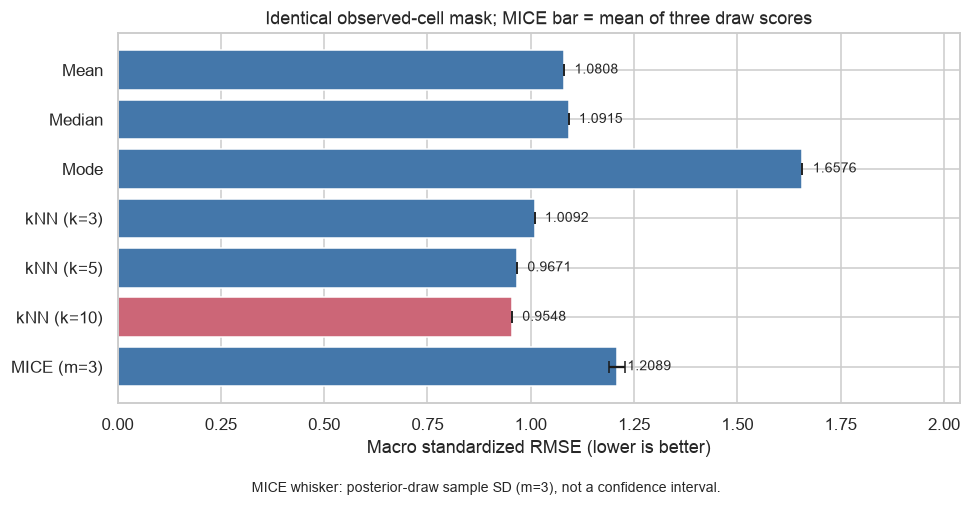

In [9]:
comparison = pd.DataFrame(evaluation_rows).set_index("Method").loc[METHOD_ORDER]
assert len(comparison) == 7 and comparison.Status.eq("PASS").all()
assert comparison["Masked N"].eq(evaluation_mask.to_numpy().sum()).all()
assert comparison["Reconstructed N"].equals(comparison["Masked N"])
assert np.isfinite(comparison[["RMSE", "Normalized RMSE", "Runtime (s)"]]).all().all()
winner = comparison["Normalized RMSE"].sort_values(kind="stable").index[0]
# Short labels keep the book table readable; full settings are defined above and retained in comparison.
comparison_display = comparison[["Parameters", "Masked N", "Reconstructed N", "RMSE", "Normalized RMSE", "Runtime (s)", "Status"]].copy()
comparison_display["Parameters"] = ["train mean", "train median", "train mode", "k=3; uniform; z", "k=5; uniform; z", "k=10; uniform; z", "m=3; posterior; 10 rounds"]
display(HTML('<div style="overflow-x:auto;max-width:100%">' + comparison_display.to_html(
    formatters={"RMSE": "{:.4f}".format, "Normalized RMSE": "{:.5f}".format, "Runtime (s)": "{:.4f}".format}) + '</div>'))
per_feature_rmse = pd.DataFrame(per_feature_scores).loc[FEATURES, METHOD_ORDER]
per_feature_rmse.index.name = "Feature (original units)"
# Only display labels are shortened; per_feature_rmse retains the original schema and full precision.
per_feature_display = per_feature_rmse.rename(index={
    "patient_age": "Age", "bmi": "BMI", "density": "Density",
    "income_household_median": "Median household income",
    "education_college_or_above": "College-or-above share"},
    columns={"kNN (k=3)": "kNN 3", "kNN (k=5)": "kNN 5", "kNN (k=10)": "kNN 10", "MICE (m=3)": "MICE 3"})
per_feature_display.index.name = "Feature (original units)"
display(HTML('<div style="overflow-x:auto;max-width:100%">' + per_feature_display.to_html(float_format="{:.3f}".format) + '</div>'))
feature_winners = per_feature_rmse.idxmin(axis=1)
display(feature_winners.rename("Lowest per-feature RMSE configuration").to_frame())
per_feature_normalized = per_feature_rmse.div(training_sd, axis="index")
display(HTML("<details><summary>Per-feature RMSE / training SD (dimensionless)</summary>"
             + per_feature_normalized.round(5).to_html() + "</details>"))

fig, ax = plt.subplots(figsize=(9, 4.6))
colors = ["#CC6677" if method == winner else "#4477AA" for method in METHOD_ORDER]
ax.barh(METHOD_ORDER, comparison["Normalized RMSE"],
        xerr=comparison["Normalized draw SD"], color=colors, capsize=4)
ax.invert_yaxis()
ax.set(xlabel="Macro standardized RMSE (lower is better)",
       title="Identical observed-cell mask; MICE bar = mean of three draw scores")
for y, value in enumerate(comparison["Normalized RMSE"]):
    ax.text(value + comparison["Normalized RMSE"].max()*.015, y, f"{value:.4f}", va="center", fontsize=9)
ax.set_xlim(0, (comparison["Normalized RMSE"] + comparison["Normalized draw SD"]).max()*1.23)
fig.text(.5, .01, "MICE whisker: posterior-draw sample SD (m=3), not a confidence interval.", ha="center", fontsize=9)
plt.tight_layout(rect=(0, .04, 1, 1)); plt.show()

## 8. Selection, interpretation and handoff

The following interpretation is calculated from the results, not filled with anticipated numbers.
The overall winner, per-feature winners and a later predictive-pipeline decision are distinct.
Selection here does not authorize deployment, target-dependent imputation or use of the reserve.

In [10]:
simple_best = comparison.loc[METHOD_ORDER[:3], "Normalized RMSE"].idxmin()
knn_best = comparison.loc[METHOD_ORDER[3:6], "Normalized RMSE"].idxmin()
raw_winner = comparison.RMSE.sort_values(kind="stable").index[0]
mice_score = comparison.loc["MICE (m=3)", "Normalized RMSE"]
relative_to_simple = (comparison.loc[simple_best, "Normalized RMSE"] - mice_score) / comparison.loc[simple_best, "Normalized RMSE"] * 100
scale_ratio = training_sd.max() / training_sd.min()
display(HTML(
    f"<p><strong>Observed benchmark result:</strong> all {len(comparison)} configurations completed. "
    f"The predeclared primary winner is <strong>{winner}</strong>, macro standardized RMSE="
    f"{comparison.loc[winner, 'Normalized RMSE']:.5f}; its raw pooled RMSE="
    f"{comparison.loc[winner, 'RMSE']:.4f}. All use {int(evaluation_mask.to_numpy().sum())} identical known-cell positions.</p>"
    f"<p>The best simple baseline is {simple_best} ({comparison.loc[simple_best, 'Normalized RMSE']:.5f}); "
    f"the best kNN setting is {knn_best} ({comparison.loc[knn_best, 'Normalized RMSE']:.5f}). "
    f"MICE has mean={mice_score:.5f}, draw SD={comparison.loc['MICE (m=3)', 'Normalized draw SD']:.5f}, "
    f"total fit+transform={comparison.loc['MICE (m=3)', 'Runtime (s)']:.3f}s; its relative primary-score "
    f"reduction versus the best simple baseline is {relative_to_simple:+.2f}% (negative means worse). "
    "This numerical comparison, model assumptions and computational cost determine whether its complexity is worthwhile here.</p>"
    f"<p>Raw pooled RMSE ranks {raw_winner} first. "
    + ("This agrees with the primary winner." if raw_winner == winner else "This conflicts with the primary winner; the declared normalized criterion is retained.")
    + f" Training SDs span a ratio of {scale_ratio:.1f}, explaining the unit-conditioning design; "
    "without an unscaled arm, its effect on kNN error is not identified. Per-feature winners are reported separately, not substituted after selection.</p>"
))
primary_gain = (1 - comparison.loc[winner, "Normalized RMSE"] / comparison.loc[simple_best, "Normalized RMSE"]) * 100
mice_assessment = (
    "Its lower primary score supports considering the added modeling effort in this benchmark."
    if mice_score < comparison.loc[simple_best, "Normalized RMSE"]
    else "It does not improve the primary score over the best simple baseline, so its added modeling effort is not justified for this point-reconstruction choice."
)
display(HTML(
    f"<p>The selected {winner} reduces the primary score by {primary_gain:.2f}% versus {simple_best}. "
    f"Feature-level minima are age: {feature_winners['patient_age']}; BMI: {feature_winners['bmi']}; "
    f"density/income: {feature_winners['density']} / {feature_winners['income_household_median']}; "
    f"education: {feature_winners['education_college_or_above']}; PM25: {feature_winners['PM25']}. "
    "The context-variable gains and competitive individual-variable baselines show why one aggregate ranking cannot dictate every feature's treatment.</p>"
    f"<p><strong>MICE decision:</strong> {mice_assessment} "
    "Posterior draws retain uncertainty and can increase squared reconstruction error relative to a conditional mean; "
    "this loss does not assess the inferential value of multiple imputation. Conditional-model mismatch and weak predictive "
    "information are possible explanations, not separately tested causes. Mean is a cheap, competitive fallback; "
    "numerical Mode cannot be assumed useful merely because it is common for categories.</p>"
))


**Limits and next-stage decisions.** This single ZIP-disjoint split and one artificial mask do
not establish a universal ranking or uncertainty across populations/masks. The observed subset
used as ground truth may differ systematically from natural missing cases, especially BMI;
natural missingness is not classified by these RMSEs. Validation remains patient-weighted with
shared area values, and geographically disjoint groups can still be spatially dependent.
The Gaussian chained-equation models/posterior variance and three-draw budget constrain MICE;
unbounded imputations need domain review before future use, and no clipping/treatment is applied.

The benchmark's internal StandardScaler does not complete the later scaling-comparison rubric.
Carry the selected configuration forward as a **candidate**, freeze its role and compare it only
within development folds in later experiments. Keep BMI and treatment out of any earlier-baseline
predictor set unless availability is justified; do not silently treat the six benchmark columns
as a clinically eligible feature list. The outer assessment is still reserved against further
fitting/tuning, with its prior EDA exposure disclosed. No classifier, resampling, encoding,
outlier treatment or feature-selection experiment is implemented here.

## 9. Focused correctness checks and data integrity

Small fixtures below test masking/scoring independently of the real-data ranking. A separate
real first-seed MICE refit verifies reproducibility without changing the three scored draws.
Validation/refit time is not part of the method runtime table. No patient rows are exported.

In [11]:
checks = {}
fixture = pd.DataFrame({"a": np.arange(30, dtype=float), "b": 3*np.arange(30, dtype=float)+1})
fixture.loc[::11, "a"] = np.nan
fixture.loc[::13, "b"] = np.nan
fixture_before = fixture.copy(deep=True)
fixture_mask = make_mcar_mask(fixture, .10, 71)
pd.testing.assert_frame_equal(fixture_mask, make_mcar_mask(fixture, .10, 71))
pd.testing.assert_frame_equal(fixture_mask, make_mcar_mask(fixture+1000, .10, 71))
assert not (fixture_mask & fixture.isna()).to_numpy().any()
np.testing.assert_array_equal(fixture_mask.sum(), np.floor(fixture.count()*.10))
pd.testing.assert_frame_equal(fixture, fixture_before)
checks["Mask reproducibility / exact floor count / no natural-NaN ground truth / no mutation"] = True

# Unmasked errors and natural NaNs must not contribute to the score.
probe = fixture + 10000
probe = probe.mask(fixture_mask, fixture)
unit_sd = pd.Series(1., index=fixture.columns)
assert score_masked(fixture, probe, fixture_mask, unit_sd)["RMSE"] == 0
probe = probe.mask(fixture_mask, fixture+2)
assert score_masked(fixture, probe, fixture_mask, unit_sd)["RMSE"] == 2
checks["RMSE uses masked known cells only; analytic RMSE matches"] = True
bad = probe.copy(); i,j = np.argwhere(fixture_mask.to_numpy())[0]; bad.iloc[i,j] = np.nan
try:
    score_masked(fixture, bad, fixture_mask, unit_sd)
except ValueError:
    checks["Nonfinite scored prediction rejected"] = True
else:
    raise AssertionError("Invalid prediction was accepted")
bad_mask = fixture_mask.copy(); i,j = np.argwhere(fixture.isna().to_numpy())[0]; bad_mask.iloc[i,j] = True
try:
    score_masked(fixture, probe, bad_mask, unit_sd)
except ValueError:
    checks["Natural-NaN ground truth rejected"] = True
else:
    raise AssertionError("Natural missing value was scored")

small_train = pd.DataFrame({"a": [0., 2., 4., np.nan], "b": [10., 10., 20., 30.]})
small_validation = pd.DataFrame({"a": [1000., np.nan], "b": [np.nan, 999.]})
small_mean = SimpleImputer(strategy="mean").fit(small_train)
np.testing.assert_allclose(small_mean.statistics_, [2., 17.5])
small_completed = small_mean.transform(small_validation)
np.testing.assert_allclose(small_completed, [[1000., 17.5], [2., 999.]])
small_scaler = StandardScaler().fit(small_train)
np.testing.assert_allclose(small_scaler.mean_, [2., 17.5])
np.testing.assert_allclose(small_scaler.inverse_transform(small_scaler.transform(small_validation)), small_validation, equal_nan=True)
assert SimpleImputer(strategy="most_frequent").fit(pd.DataFrame({"a": [1., 1., 2., 2.]})).statistics_[0] == 1
checks["Train-only statistics / validation separation / inverse units / smallest-mode tie"] = True

rng = np.random.default_rng(19)
small_chain_train = pd.DataFrame(rng.normal(size=(40, 3)), columns=["a", "b", "c"])
small_chain_train.loc[::4, "b"] = np.nan
small_chain_validation = pd.DataFrame(rng.normal(size=(20, 3)), columns=small_chain_train.columns)
small_chain_validation.loc[::3, "a"] = np.nan
small_draws = []
for _ in range(2):
    small_model = IterativeImputer(sample_posterior=True, max_iter=3, skip_complete=False, random_state=101).fit(small_chain_train.to_numpy(copy=True))
    small_draws.append(small_model.transform(small_chain_validation.to_numpy(copy=True)))
np.testing.assert_array_equal(small_draws[0], small_draws[1])
assert np.isfinite(small_draws[0]).all()
checks["Posterior MICE fixed-seed reproducibility on synthetic data"] = True
display(pd.Series(checks, name="PASS").to_frame())
assert all(checks.values())

,PASS
Mask reproducibility / exact floor count / no natural-NaN ground truth / no mutation,True
RMSE uses masked known cells only; analytic RMSE matches,True
Nonfinite scored prediction rejected,True
Natural-NaN ground truth rejected,True
Train-only statistics / validation separation / inverse units / smallest-mode tie,True
Posterior MICE fixed-seed reproducibility on synthetic data,True


In [12]:
repeat_model = IterativeImputer(**MICE_SETTINGS, random_state=MICE_SEEDS[0]).fit(train_z.to_numpy(copy=True))
repeat_completed = distance_scaler.inverse_transform(repeat_model.transform(validation_z.to_numpy(copy=True)))
np.testing.assert_array_equal(repeat_completed, mice_completions[0].to_numpy())
checks["Real-data first-seed MICE reproduction"] = True
assert len(set(mask_hashes.values())) == 1 and set(mask_hashes) == set(METHOD_ORDER)
assert set(fit_rows.values()) == {len(train_index)} and set(fit_rows) == set(METHOD_ORDER)
for method, completions in completed_values.items():
    for completed in completions:
        assert completed.shape == X_validation_reference.shape
        assert completed.columns.equals(X_validation_reference.columns) and completed.index.equals(validation_index)
        assert np.isfinite(completed.to_numpy()).all()
        observed = ~X_validation_masked.isna().to_numpy()
        np.testing.assert_allclose(completed.to_numpy()[observed], X_validation_masked.to_numpy()[observed])
        assert score_masked(X_validation_reference, completed, evaluation_mask, training_sd)["Masked N"] == evaluation_mask.to_numpy().sum()
assert hashlib.sha256(pd.util.hash_pandas_object(evaluation_mask, index=True).to_numpy().tobytes()).hexdigest() == mask_hash
assert hashlib.sha256(pd.util.hash_pandas_object(X_train, index=True).to_numpy().tobytes()).hexdigest() == train_hash_before
assert hashlib.sha256(pd.util.hash_pandas_object(X_validation_reference, index=True).to_numpy().tobytes()).hexdigest() == reference_hash_before
assert hashlib.sha256(pd.util.hash_pandas_object(df, index=True).to_numpy().tobytes()).hexdigest() == frame_hash_before
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == raw_sha_before
assert df.dtypes.equals(dtypes_before) and df.shape == shape_before and df.columns.equals(columns_before)
assert X_train.columns.equals(pd.Index(FEATURES)) and set(FEATURES).isdisjoint(forbidden)
checks["All methods: same mask / same training rows / alignment / finite predictions / no protected predictors"] = True
checks["Raw CSV, source frame, train and reference unchanged"] = True
display(pd.Series(checks, name="PASS").to_frame())
print(f"PASS: {len(comparison)} configurations; {len(MICE_SEEDS)} scored MICE draws; {int(evaluation_mask.to_numpy().sum())} identical masked positions per completion.")
print("PASS: raw CSV SHA-256 unchanged:", raw_sha_before)
print("Controlled imputation benchmark complete; no patient-row export or assessment-set scoring.")

,PASS
Mask reproducibility / exact floor count / no natural-NaN ground truth / no mutation,True
RMSE uses masked known cells only; analytic RMSE matches,True
Nonfinite scored prediction rejected,True
Natural-NaN ground truth rejected,True
Train-only statistics / validation separation / inverse units / smallest-mode tie,True
Posterior MICE fixed-seed reproducibility on synthetic data,True
Real-data first-seed MICE reproduction,True
All methods: same mask / same training rows / alignment / finite predictions / no protected predictors,True
"Raw CSV, source frame, train and reference unchanged",True


PASS: 7 configurations; 3 scored MICE draws; 1101 identical masked positions per completion.
PASS: raw CSV SHA-256 unchanged: e9947ecfe1cdacafbf9cbcdc0abd024396f617c701b056fa54e5881f1bb9bbe9
Controlled imputation benchmark complete; no patient-row export or assessment-set scoring.


### Reproduce and publish

Use the project's `hcmus-wids` .venv kernel, **Restart Kernel → Run All**, with the official
local training CSV. The notebook contains all preparation checks, methods, metrics and tests;
Stage 01 remains unchanged. Numeric results/figures are saved as aggregate outputs. The existing
Jupyter Book build omits `--execute`, so CI can render them without the private CSV or Kaggle
credentials. Keep outputs, or rerun locally after clearing them. No completed patient dataset
is saved. The audit records the measured result and the exact scope; local rendering does not
prove a public Pages deployment. Later rubric stages remain unimplemented.

## 10. Complete numerical eligibility audit — expanded scope

**Question:** can all 69 candidates participate in one shared retrospective reconstruction
experiment? The original six-feature scope above is retained, not enlarged in place.
The [official dictionary](https://www.kaggle.com/competitions/widsdatathon2024-challenge1/data)
was rechecked via indexed text; Stage 01 contains the clinical/timing audit. Descriptions below
use broad measurement roles, not invented clinical definitions. Area columns are contextual,
not measurements of the individual patient's income, race or education.

**Inclusion rule fixed before expanded scoring:** numerical measurement candidates only;
finite observed values; at least two observed and two distinct training values; positive,
finite observed training SD; at least ten observed validation values so floor(10%) masks at
least one cell. These are mechanical feasibility minima, not guarantees of statistical power.
ID, target, nominal codes, diagnosis and treatment remain prohibited. Correlation, skewness,
boundedness and an unfavorable future RMSE are **not exclusion criteria**. No feature is dropped
to make a covariance matrix invertible. All included features must use the same train/validation
rows, full predictor matrix and within-scope mask for every method.

BMI remains post-metastatic. Age's index/baseline alignment and contextual reference periods
remain unresolved. `poverty` is retained only as a literal continuous numerical column: the
dictionary conflicts with its name, so no poverty interpretation or [0,100] bound is imposed.
The `widowed` description also has inconsistent wording; its exact label interpretation remains
unverified. Such reconstruction eligibility does not authorize prospective prediction.
The table is derived from the CSV and the declared rules above; saved EDA outputs are not required.


In [13]:
import os
import re
import subprocess
from threadpoolctl import threadpool_limits  # Existing sklearn dependency; no installation.

expanded_train_all = df.loc[train_index, numerical_candidates].copy(deep=True)
expanded_reference_all = df.loc[validation_index, numerical_candidates].copy(deep=True)
assert set(numerical_candidates).isdisjoint(forbidden)

# Dictionary-confirmed population/household shares; rent_burden is a ratio, not a <=100 share.
other_context = {"population", "density", "age_median", "family_size",
                 "income_household_median", "income_individual_median", "housing_units",
                 "home_value", "rent_median", "commute_time", "rent_burden", "poverty"}
air_features = {"Ozone", "PM25", "N02"}
bounded_share_features = set(numerical_candidates) - other_context - air_features - {"patient_age", "bmi"}
eligibility_rows = []
for column in numerical_candidates:
    train_column = expanded_train_all[column]
    observed_values = df[column].dropna().to_numpy()
    support = (train_column.count() >= 2 and train_column.nunique() >= 2
               and np.isfinite(train_column.std(ddof=0)) and train_column.std(ddof=0) > 0
               and expanded_reference_all[column].count() >= 10
               and np.isfinite(observed_values).all())
    if column == "patient_age":
        role, reason = "Individual age", "Index/baseline alignment unverified"
    elif column == "bmi":
        role, reason = "Individual BMI", "Post-metastatic; retrospective only"
    elif column == "poverty":
        role, reason = "Area numerical; meaning UNVERIFIED", "Conflicting dictionary; no poverty-rate/bound assumption"
    elif column in air_features:
        role, reason = "Annual ZIP3 air context", "Units/exposure year and baseline availability unverified"
    elif column in bounded_share_features:
        role, reason = "Area share [0,100]", "Context/reference period unresolved; unbounded MICE may violate support"
    else:
        role, reason = "Area numerical summary", "Context/reference period unresolved; units vary"
    if column == "rent_burden":
        reason += "; rent/income percentage can exceed 100; no upper bound imposed"
    if column == "widowed":
        reason += "; exact dictionary wording inconsistent"
    eligibility_rows.append({"Feature": column, "Semantic role": role,
        "Missing %": df[column].isna().mean()*100, "Observed N": int(df[column].count()),
        "Unique N": int(df[column].nunique()),
        "Train availability": f"{train_column.count()} observed; {train_column.nunique()} unique",
        "Eligibility": "Included: retrospective" if support else "Excluded: support/finite/SD rule",
        "Reason": reason})
numerical_eligibility = pd.DataFrame(eligibility_rows).set_index("Feature")
EXPANDED_FEATURES = numerical_eligibility.index[numerical_eligibility.Eligibility.eq("Included: retrospective")].tolist()
assert len(numerical_eligibility) == 69 and len(EXPANDED_FEATURES) == 69  # Actual dataset: no exclusions needed.
display(numerical_eligibility.groupby(["Semantic role", "Eligibility"]).size().rename("Features N").to_frame())
display(HTML('<details><summary>All 69 numerical candidates: eligibility and reasons</summary>'
    '<div style="overflow:auto;max-height:32rem">' + numerical_eligibility.to_html(float_format="{:.4f}".format) + '</div></details>'))
print(f"Coverage decision before scoring: {len(EXPANDED_FEATURES)}/69 included; 0 excluded; {len(bounded_share_features)} bounded shares.")


,,Features N
Semantic role,Eligibility,
Annual ZIP3 air context,Included: retrospective,3
Area numerical summary,Included: retrospective,11
Area numerical; meaning UNVERIFIED,Included: retrospective,1
"Area share [0,100]",Included: retrospective,52
Individual BMI,Included: retrospective,1
Individual age,Included: retrospective,1


,Semantic role,Missing %,Observed N,Unique N,Train availability,Eligibility,Reason
Feature,,,,,,,
patient_age,Individual age,0.0000,12906,67,8173 observed; 67 unique,Included: retrospective,Index/baseline alignment unverified
bmi,Individual BMI,69.4638,3941,1342,2531 observed; 1037 unique,Included: retrospective,Post-metastatic; retrospective only
population,Area numerical summary,0.0077,12905,738,8173 observed; 443 unique,Included: retrospective,Context/reference period unresolved; units vary
density,Area numerical summary,0.0077,12905,738,8173 observed; 443 unique,Included: retrospective,Context/reference period unresolved; units vary
age_median,Area numerical summary,0.0077,12905,728,8173 observed; 439 unique,Included: retrospective,Context/reference period unresolved; units vary
age_under_10,"Area share [0,100]",0.0077,12905,718,8173 observed; 435 unique,Included: retrospective,Context/reference period unresolved; unbounded MICE may violate support
age_10_to_19,"Area share [0,100]",0.0077,12905,725,8173 observed; 440 unique,Included: retrospective,Context/reference period unresolved; unbounded MICE may violate support
age_20s,"Area share [0,100]",0.0077,12905,724,8173 observed; 435 unique,Included: retrospective,Context/reference period unresolved; unbounded MICE may violate support
age_30s,"Area share [0,100]",0.0077,12905,725,8173 observed; 438 unique,Included: retrospective,Context/reference period unresolved; unbounded MICE may violate support


Coverage decision before scoring: 69/69 included; 0 excluded; 52 bounded shares.


## 11. Expanded mask, conditioning and computational feasibility

The ZIP-disjoint partitions, seeds 42/43, training-only fit, mask seed 2024 and
floor(10% of observed values) rule are unchanged. The new ordered 69-column matrix has its own
mask; no aggregate score is directly compared with the original six-column experiment.
Natural gaps remain and no outer-reserve measurements enter fitting/scoring.

Conditioning uses only observed inner-training values, with the same ddof 0 normalization.
The training complete-case correlation matrix below is a **dimensionless conditioning screen**,
not a new Little/normality test or an assertion that complete cases are representative.
Its numerical rank depends on tolerance. Redundant contextual shares may make it singular;
the default BayesianRidge conditional estimator already uses its specified Bayesian shrinkage,
so singular empirical correlations do not automatically forbid fitting. We neither change
regularization nor remove columns to obtain a successful result.

Use a full-population one-round MICE pilot **without scoring RMSE** to check feasibility first.
An extrapolation to 30 rounds across three fits is a budget estimate, not a measured runtime.
Three scored ten-round posterior fits and an independent first-seed repeat must still complete.
The expanded experiment limits detected thread pools to one and kNN working memory to 128 MiB; no row
subsampling or extra dependency is used. Free/inactive memory is an OS estimate, not a guarantee.


In [14]:
expanded_train = expanded_train_all[EXPANDED_FEATURES].copy(deep=True)
expanded_reference = expanded_reference_all[EXPANDED_FEATURES].copy(deep=True)
expanded_train_hash = hashlib.sha256(pd.util.hash_pandas_object(expanded_train, index=True).to_numpy().tobytes()).hexdigest()
expanded_reference_hash = hashlib.sha256(pd.util.hash_pandas_object(expanded_reference, index=True).to_numpy().tobytes()).hexdigest()
expanded_mask = make_mcar_mask(expanded_reference, MASK_RATE, MASK_SEED)
pd.testing.assert_frame_equal(expanded_mask, make_mcar_mask(expanded_reference, MASK_RATE, MASK_SEED))
assert not (expanded_mask & expanded_reference.isna()).to_numpy().any()
expanded_mask_hash = hashlib.sha256(pd.util.hash_pandas_object(expanded_mask, index=True).to_numpy().tobytes()).hexdigest()
expanded_masked = expanded_reference.mask(expanded_mask)
expanded_mask_audit = pd.DataFrame({"Train observed N": expanded_train.count(),
    "Eligible validation N": expanded_reference.count(), "Natural validation NaN N": expanded_reference.isna().sum(),
    "Artificial masked N": expanded_mask.sum()})
expanded_mask_audit["Actual mask %"] = expanded_mask_audit["Artificial masked N"] / expanded_mask_audit["Eligible validation N"] * 100
assert expanded_mask_audit["Artificial masked N"].eq(np.floor(.10*expanded_reference.count())).all()
display(HTML('<details><summary>Eligible N, natural NaNs, masked N and actual rate: all 69 columns</summary>'
             '<div style="overflow:auto;max-height:32rem">'+expanded_mask_audit.to_html(float_format="{:.4f}".format)+'</div></details>'))
print("Expanded mask SHA-256:", expanded_mask_hash)
print(f"{int(expanded_mask.to_numpy().sum())} artificial gaps / {int(expanded_reference.count().sum())} eligible observed cells.")

start = perf_counter()
expanded_scaler = StandardScaler().fit(expanded_train)
expanded_sd = expanded_train.std(ddof=0)
np.testing.assert_allclose(expanded_scaler.mean_, expanded_train.mean().to_numpy())
np.testing.assert_allclose(expanded_scaler.scale_, expanded_sd.to_numpy())
np.testing.assert_array_equal(np.broadcast_to(expanded_scaler.n_samples_seen_, (len(EXPANDED_FEATURES),)), expanded_train.count().to_numpy())
expanded_train_z = expanded_scaler.transform(expanded_train)
expanded_validation_z = expanded_scaler.transform(expanded_masked)
# Floating-point inversion can move an exact zero by ~2e-16; use numerical tolerance, not equality.
np.testing.assert_allclose(expanded_scaler.inverse_transform(expanded_validation_z), expanded_masked.to_numpy(),
                           rtol=1e-12, atol=1e-12, equal_nan=True)
expanded_conditioning_seconds = perf_counter()-start
expanded_observed = expanded_train.notna().astype(int)
expanded_joint_n = expanded_observed.T @ expanded_observed
expanded_corr = expanded_train.dropna().corr().to_numpy()
expanded_singular_values = np.linalg.svd(expanded_corr, compute_uv=False)
memory_total = memory_reclaimable = np.nan
if sys.platform == "darwin":
    memory_total = int(subprocess.check_output(["sysctl", "-n", "hw.memsize"], text=True))/1024**3
    vm = subprocess.check_output(["vm_stat"], text=True)
    page_size = int(re.search(r"page size of (\d+) bytes", vm).group(1))
    counts = [int(re.search(rf"Pages {name}:\s+(\d+)", vm).group(1)) for name in ["free", "inactive", "speculative"]]
    memory_reclaimable = sum(counts)*page_size/1024**3
elif hasattr(os, "sysconf"):
    memory_total = os.sysconf("SC_PHYS_PAGES")*os.sysconf("SC_PAGE_SIZE")/1024**3
    memory_reclaimable = os.sysconf("SC_AVPHYS_PAGES")*os.sysconf("SC_PAGE_SIZE")/1024**3
expanded_feasibility = pd.Series({
    "Training rows": len(expanded_train), "Validation rows": len(expanded_reference), "Columns": len(EXPANDED_FEATURES),
    "Complete training rows": len(expanded_train.dropna()),
    "Minimum pairwise observed training N": expanded_joint_n.to_numpy().min(),
    "Maximum pairwise observed training N": expanded_joint_n.to_numpy().max(),
    "Complete-case correlation rank": np.linalg.matrix_rank(expanded_corr),
    "Complete-case correlation condition": expanded_singular_values[0]/expanded_singular_values[-1],
    "Training array MiB": expanded_train.size*8/1024**2,
    "Dense validation x train distance MiB": len(expanded_train)*len(expanded_reference)*8/1024**2,
    "kNN chunk budget MiB (not total RAM cap)": KNN_MEMORY_MIB,
    "MICE conditional fits per scored draw": len(EXPANDED_FEATURES)*MICE_SETTINGS["max_iter"],
    "MICE conditional fits in three scored draws": len(EXPANDED_FEATURES)*MICE_SETTINGS["max_iter"]*len(MICE_SEEDS),
    "Three draws coefficient-covariance storage estimate MiB": len(EXPANDED_FEATURES)*MICE_SETTINGS["max_iter"]*len(MICE_SEEDS)*(len(EXPANDED_FEATURES)-1)**2*8/1024**2,
    "Physical RAM GiB": memory_total, "Free + inactive + speculative GiB (Linux: available pages)": memory_reclaimable,
    "Shared conditioning seconds": expanded_conditioning_seconds})
display(expanded_feasibility.to_frame("Value"))


,Train observed N,Eligible validation N,Natural validation NaN N,Artificial masked N,Actual mask %
patient_age,8173,2081,0,208,9.9952
bmi,2531,639,1442,63,9.8592
population,8173,2080,1,208,10.0000
density,8173,2080,1,208,10.0000
age_median,8173,2080,1,208,10.0000
age_under_10,8173,2080,1,208,10.0000
age_10_to_19,8173,2080,1,208,10.0000
age_20s,8173,2080,1,208,10.0000
age_30s,8173,2080,1,208,10.0000
age_40s,8173,2080,1,208,10.0000


Expanded mask SHA-256: c9f042a41bed1b8ca6bc6223dd0eeb773886e0e3c2457643d7c8574fde438664
14181 artificial gaps / 142008 eligible observed cells.


,Value
Training rows,8.173000e+03
Validation rows,2.081000e+03
Columns,6.900000e+01
Complete training rows,2.526000e+03
Minimum pairwise observed training N,2.526000e+03
Maximum pairwise observed training N,8.173000e+03
Complete-case correlation rank,6.700000e+01
Complete-case correlation condition,6.290808e+16
Training array MiB,4.302498e+00
Dense validation x train distance MiB,1.297608e+02


The pilot below uses the same full training and masked validation matrices as the final
experiment. It checks finite completions/covariances and records model count and measured time;
it is not one of the scored MICE draws. No outcome is used to choose predictors or seeds.


In [15]:
with threadpool_limits(limits=1):
    start = perf_counter()
    pilot_settings = {**MICE_SETTINGS, "max_iter": 1}
    expanded_pilot = IterativeImputer(**pilot_settings, random_state=MICE_SEEDS[0]).fit(expanded_train_z.copy())
    expanded_pilot_values = expanded_scaler.inverse_transform(expanded_pilot.transform(expanded_validation_z.copy()))
    expanded_pilot_seconds = perf_counter()-start
assert np.isfinite(expanded_pilot_values).all()
assert all(np.isfinite(step.estimator.sigma_).all() for step in expanded_pilot.imputation_sequence_)
assert len(expanded_pilot.imputation_sequence_) == len(EXPANDED_FEATURES)
display(pd.Series({"Full-population one-round pilot seconds": expanded_pilot_seconds,
    "Conditional models fitted": len(expanded_pilot.imputation_sequence_), "Finite completions and covariances": True,
    "Linear estimate: three ten-round draws seconds (not measured)": expanded_pilot_seconds*30}).to_frame("Pilot"))
del expanded_pilot_values, expanded_pilot


,Pilot
Full-population one-round pilot seconds,1.424466
Conditional models fitted,69
Finite completions and covariances,True
Linear estimate: three ten-round draws seconds (not measured),42.733975


## 12. Joint expanded benchmark — seven configurations

All methods use the **same complete 69-feature predictor scope**, training donors and validation
mask. Reuse the masking/scoring functions and the original formulas above. Baselines fit raw
training values; kNN and MICE fit train-standardized values and return to original units.
No validation row becomes a kNN donor. Undefined missing-aware distances use sklearn's
training-feature-mean fallback; neither ZIP nor target is a numerical predictor.

MICE retains three posterior seeds, ten rounds, `skip_complete=False` and the default estimator.
No clipping, transformations, feature removal or regularization changes are applied to improve
its scores. Bounded shares and skewed measurements can violate its Gaussian/linear working
models; explicitly count out-of-support predictions below. Such counts concern plausibility,
not an inferred missingness mechanism. The seven-row MICE score is the mean of draw-level
metrics, with sample SD. It is not a pooled inferential estimate or an averaged completion.
Support flags report both strict violations and violations beyond 32×machine-epsilon×100;
this only separates roundoff at zero from material support errors and never alters values.
Runtime covers fit/transform/inverse units; shared conditioning, pilot and correctness repeat
are reported separately. A common loop avoids duplicating the original method implementations.


In [16]:
expanded_configurations = [
    (name, SimpleImputer(strategy=strategy, keep_empty_features=True), False, None, f"strategy={strategy}")
    for name, strategy in [("Mean", "mean"), ("Median", "median"), ("Mode", "most_frequent")]]
expanded_configurations += [(f"kNN (k={k})", KNNImputer(n_neighbors=k, weights="uniform", metric="nan_euclidean", keep_empty_features=True),
    True, None, f"k={k}; uniform; nan_euclidean; train z") for k in [3, 5, 10]]
expanded_configurations += [("MICE (m=3)", IterativeImputer(**MICE_SETTINGS, random_state=seed), True, seed,
    "BayesianRidge; posterior; m=3; 10 rounds; seeds101/102/103; skip_complete=False") for seed in MICE_SEEDS]
expanded_run_rows, expanded_feature_runs, expanded_completions, expanded_models, expanded_support_rows = [], {}, {}, {}, []
expanded_known = ~expanded_masked.isna().to_numpy()
bounded_columns = [c for c in EXPANDED_FEATURES if c in bounded_share_features]
bounded_mask = expanded_mask[bounded_columns].to_numpy()
share_roundoff_tolerance = 32*np.finfo(float).eps*100  # Diagnostic only; never clip predictions.
for name, imputer, conditioned, seed, parameters in expanded_configurations:
    with threadpool_limits(limits=1), config_context(working_memory=KNN_MEMORY_MIB):
        start = perf_counter()
        fit_values = expanded_train_z.copy() if conditioned else expanded_train.to_numpy(copy=True)
        validation_values = expanded_validation_z.copy() if conditioned else expanded_masked.to_numpy(copy=True)
        imputer.fit(fit_values)
        filled = imputer.transform(validation_values)
        if conditioned:
            filled = expanded_scaler.inverse_transform(filled)
        completed = pd.DataFrame(filled, index=validation_index, columns=EXPANDED_FEATURES)
        elapsed = perf_counter()-start
    assert imputer.n_features_in_ == len(EXPANDED_FEATURES) and np.isfinite(filled).all()
    np.testing.assert_allclose(filled[expanded_known], expanded_masked.to_numpy()[expanded_known], rtol=1e-12, atol=1e-12)
    if isinstance(imputer, SimpleImputer):
        expected = {"Mean": expanded_train.mean(), "Median": expanded_train.median(), "Mode": expanded_train.mode().iloc[0]}[name]
        np.testing.assert_allclose(imputer.statistics_, expected.to_numpy())
    if isinstance(imputer, IterativeImputer):
        assert imputer.n_iter_ == MICE_SETTINGS["max_iter"]
        assert len(imputer.imputation_sequence_) == len(EXPANDED_FEATURES)*MICE_SETTINGS["max_iter"]
        np.testing.assert_allclose(imputer.initial_imputer_.statistics_, np.nanmean(expanded_train_z, axis=0), atol=1e-12)
        assert all(np.isfinite(step.estimator.sigma_).all() for step in imputer.imputation_sequence_)
    score = score_masked(expanded_reference, completed, expanded_mask, expanded_sd)
    expanded_run_rows.append({"Method": name, "Seed": seed, "Parameters": parameters,
        "Rounds": imputer.n_iter_ if isinstance(imputer, IterativeImputer) else 0,
        **{key: score[key] for key in ["RMSE", "Normalized RMSE", "Masked N", "Reconstructed N"]},
        "Runtime (s)": elapsed, "Status": "PASS"})
    expanded_feature_runs.setdefault(name, []).append(score["per_feature"])
    expanded_completions.setdefault(name, []).append(completed)
    expanded_models.setdefault(name, []).append(imputer)
    bounded_predictions = completed[bounded_columns].to_numpy()[bounded_mask]
    expanded_support_rows.append({"Method": name, "Seed": seed, "Bounded masked N": len(bounded_predictions),
        "Out-of-[0,100] N": int(((bounded_predictions < 0) | (bounded_predictions > 100)).sum()),
        "Beyond roundoff N": int(((bounded_predictions < -share_roundoff_tolerance) | (bounded_predictions > 100+share_roundoff_tolerance)).sum())})
    print(f"Completed {name}, seed={seed}, {elapsed:.3f}s; scored={score['Reconstructed N']}/{score['Masked N']}.")
expanded_runs = pd.DataFrame(expanded_run_rows)
expanded_mice_draws = expanded_runs[expanded_runs.Method.eq("MICE (m=3)")].drop(columns=["Parameters", "Method"])
display(expanded_mice_draws.set_index("Seed").round(5))


Completed Mean, seed=None, 0.003s; scored=14181/14181.
Completed Median, seed=None, 0.036s; scored=14181/14181.
Completed Mode, seed=None, 0.028s; scored=14181/14181.


Completed kNN (k=3), seed=None, 1.679s; scored=14181/14181.


Completed kNN (k=5), seed=None, 2.092s; scored=14181/14181.


Completed kNN (k=10), seed=None, 2.091s; scored=14181/14181.


Completed MICE (m=3), seed=101, 13.293s; scored=14181/14181.


Completed MICE (m=3), seed=102, 12.865s; scored=14181/14181.


Completed MICE (m=3), seed=103, 12.975s; scored=14181/14181.


,Rounds,RMSE,Normalized RMSE,Masked N,Reconstructed N,Runtime (s),Status
Seed,,,,,,,
101.0,10,12394.94924,0.86829,14181,14181,13.29263,PASS
102.0,10,12838.51453,0.86215,14181,14181,12.86542,PASS
103.0,10,12156.79619,0.85899,14181,14181,12.97472,PASS


## 13. Expanded results — primary selection stays Macro NRMSE

Scores below apply only to the joint expanded scope. Every count is per completion; three
posterior draws do not multiply the number of distinct validation cells. MICE per-feature and
aggregate values are means of draw-level RMSEs. Sample draw SD does not quantify ZIP/split/mask
sampling uncertainty. Full 69-row raw/normalized tables are expandable with capped scroll areas; the compact seven-row
table and one chart summarize this scope without combining it with the earlier benchmark.
Raw pooled RMSE still mixes units and can be dominated by home values/income. The equal-feature
training-SD-normalized criterion remains fixed, even if a secondary ranking disagrees.


,Parameters,Masked N,Reconstructed N,RMSE,Normalized RMSE,Runtime (s),Status
Method,,,,,,,
Mean,train mean,14181,14181,36213.2867,1.06377,0.003,PASS
Median,train median,14181,14181,38163.5466,1.08172,0.036,PASS
Mode,train mode,14181,14181,73213.8081,1.55649,0.028,PASS
kNN (k=3),k=3; uniform; z,14181,14181,17657.8528,0.70408,1.679,PASS
kNN (k=5),k=5; uniform; z,14181,14181,16829.0707,0.69521,2.092,PASS
kNN (k=10),k=10; uniform; z,14181,14181,16203.8687,0.67633,2.091,PASS
MICE (m=3),m=3; posterior; 10 rounds,14181,14181,12463.4200,0.86314,39.133,PASS


,Mean,Median,Mode,kNN (k=3),kNN (k=5),kNN (k=10),MICE (m=3)
patient_age,13.48408,13.46684,14.67763,16.72921,15.63292,15.10391,18.38778
bmi,4.91823,5.04795,5.36895,5.96096,5.64776,5.50606,7.68989
population,11585.22281,11483.15135,20674.54179,6625.43193,6532.88223,6623.23957,3565.80332
density,1873.06098,1945.05078,4446.05714,1220.86334,1207.86825,1184.70486,1225.88064
age_median,3.72705,3.73154,5.20048,2.17850,2.17486,2.18588,0.99523
age_under_10,1.39081,1.40367,1.97074,1.15757,1.12598,1.06632,2.03967
age_10_to_19,1.90247,1.89671,2.78706,1.81135,1.81751,1.76918,1.79988
age_20s,3.11048,3.17915,5.03484,2.60962,2.57638,2.51389,2.02536
age_30s,2.20294,2.08686,5.60716,1.56887,1.53400,1.48646,1.63808
age_40s,1.21609,1.22434,1.58890,1.11324,1.09736,1.08351,1.31825


,Mean,Median,Mode,kNN (k=3),kNN (k=5),kNN (k=10),MICE (m=3)
patient_age,1.01699,1.01569,1.10701,1.26174,1.17906,1.13916,1.38683
bmi,0.84833,0.87071,0.92608,1.02819,0.97417,0.94973,1.32641
population,0.94089,0.93260,1.67908,0.53808,0.53057,0.53791,0.28960
density,0.98888,1.02689,2.34730,0.64456,0.63769,0.62547,0.64720
age_median,0.95846,0.95962,1.33738,0.56023,0.55930,0.56213,0.25594
age_under_10,0.94755,0.95631,1.34264,0.78864,0.76712,0.72647,1.38960
age_10_to_19,0.98940,0.98640,1.44944,0.94202,0.94522,0.92008,0.93605
age_20s,0.94867,0.96961,1.53558,0.79591,0.78577,0.76671,0.61772
age_30s,0.95069,0.90059,2.41979,0.67705,0.66200,0.64149,0.70692
age_40s,1.03689,1.04393,1.35476,0.94919,0.93566,0.92385,1.12400


Bounded masked N  Out-of-[0,100] N  Beyond roundoff N
Method     Seed                                                        
Mean       NaN               10799                 0                  0
Median     NaN               10799                 0                  0
Mode       NaN               10799                 0                  0
kNN (k=3)  NaN               10799                 0                  0
kNN (k=5)  NaN               10799                 1                  0
kNN (k=10) NaN               10799                 0                  0
MICE (m=3) 101.0             10799               301                301
           102.0             10799               304                304
           103.0             10799               307                307

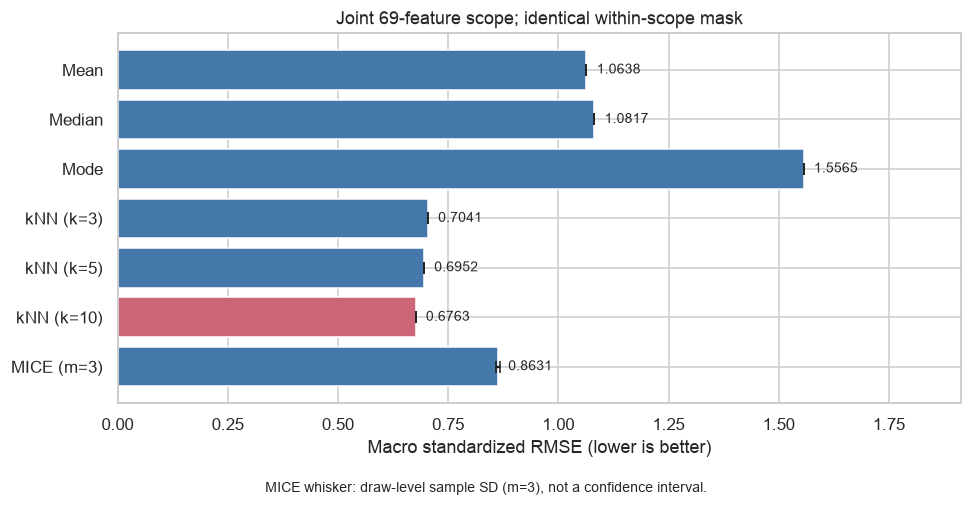

In [17]:
expanded_comparison_rows = []
for name in METHOD_ORDER:
    rows = expanded_runs[expanded_runs.Method.eq(name)]
    expanded_comparison_rows.append({"Method": name, "Parameters": rows.Parameters.iloc[0],
        "Masked N": int(rows["Masked N"].iloc[0]), "Reconstructed N": int(rows["Reconstructed N"].iloc[0]),
        "RMSE": rows.RMSE.mean(), "Normalized RMSE": rows["Normalized RMSE"].mean(),
        "RMSE draw SD": rows.RMSE.std(ddof=1) if len(rows)>1 else 0.,
        "Normalized draw SD": rows["Normalized RMSE"].std(ddof=1) if len(rows)>1 else 0.,
        "Draws": len(rows), "Runtime (s)": rows["Runtime (s)"].sum(), "Status": "PASS"})
expanded_comparison = pd.DataFrame(expanded_comparison_rows).set_index("Method").loc[METHOD_ORDER]
expanded_per_feature = pd.DataFrame({name: pd.concat(draws, axis=1).mean(axis=1)
    for name, draws in expanded_feature_runs.items()}).loc[EXPANDED_FEATURES, METHOD_ORDER]
expanded_per_feature_normalized = expanded_per_feature.div(expanded_sd, axis="index")
expanded_winner = expanded_comparison["Normalized RMSE"].sort_values(kind="stable").index[0]
expanded_raw_winner = expanded_comparison.RMSE.sort_values(kind="stable").index[0]
expanded_display = expanded_comparison[["Parameters", "Masked N", "Reconstructed N", "RMSE", "Normalized RMSE", "Runtime (s)", "Status"]].copy()
expanded_display.Parameters = ["train mean", "train median", "train mode", "k=3; uniform; z", "k=5; uniform; z", "k=10; uniform; z", "m=3; posterior; 10 rounds"]
display(HTML('<div style="overflow-x:auto;max-width:100%">'+expanded_display.to_html(formatters={
    "RMSE":"{:.4f}".format,"Normalized RMSE":"{:.5f}".format,"Runtime (s)":"{:.3f}".format})+'</div>'))
for label, table in [("Raw-unit RMSE — all 69 features", expanded_per_feature),
                     ("RMSE / observed training SD — all 69 features", expanded_per_feature_normalized)]:
    display(HTML('<details><summary>'+label+'</summary><div style="overflow:auto;max-height:32rem">'
                 +table.to_html(float_format="{:.5f}".format)+'</div></details>'))
expanded_support = pd.DataFrame(expanded_support_rows)
display(expanded_support.set_index(["Method", "Seed"]))
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(METHOD_ORDER, expanded_comparison["Normalized RMSE"], xerr=expanded_comparison["Normalized draw SD"],
        color=["#CC6677" if name==expanded_winner else "#4477AA" for name in METHOD_ORDER], capsize=4)
ax.invert_yaxis()
ax.set(title=f"Joint {len(EXPANDED_FEATURES)}-feature scope; identical within-scope mask",
       xlabel="Macro standardized RMSE (lower is better)")
for i, value in enumerate(expanded_comparison["Normalized RMSE"]):
    ax.text(value+expanded_comparison["Normalized RMSE"].max()*.015, i, f"{value:.4f}", va="center", fontsize=9)
ax.set_xlim(0,(expanded_comparison["Normalized RMSE"]+expanded_comparison["Normalized draw SD"]).max()*1.23)
fig.text(.5,.01,"MICE whisker: draw-level sample SD (m=3), not a confidence interval.",ha="center",fontsize=9)
plt.tight_layout(rect=(0,.04,1,1)); plt.show()


## 14. Expanded verification and preservation checks

The earlier synthetic fixtures test the same scoring/masking functions used here. Add a
deliberate column-order mismatch check, real full-scope finite/alignment/training-statistic
guards and a separate first-seed posterior refit. This refit is excluded from scored runtimes.
Original variables (`FEATURES`, `comparison`, `per_feature_rmse`, `evaluation_mask`, `winner`)
remain separate; the execution audit also compares original scores against commit `ac8f7bb`.


In [18]:
expanded_checks = {}
# Different units: residuals 2/4 with train SD 1/2 imply raw sqrt(10), Macro NRMSE 2.
normalized_probe = fixture + 10000
for column, error in [("a", 2.), ("b", 4.)]:
    rows = fixture_mask[column]
    normalized_probe.loc[rows, column] = fixture.loc[rows, column] + error
normalized_score = score_masked(fixture, normalized_probe, fixture_mask, pd.Series({"a": 1., "b": 2.}))
np.testing.assert_allclose(normalized_score["RMSE"], np.sqrt(10))
np.testing.assert_allclose(normalized_score["Normalized RMSE"], 2.)
expanded_checks["Independent raw/normalized RMSE fixture with unequal units"] = True
np.testing.assert_allclose(expanded_per_feature_normalized.mean(), expanded_comparison["Normalized RMSE"])
try:
    score_masked(fixture, probe[fixture.columns[::-1]], fixture_mask, unit_sd)
except ValueError:
    expanded_checks["Column misalignment rejected independently"] = True
else:
    raise AssertionError("Misaligned columns were scored")
with threadpool_limits(limits=1):
    repeat_start = perf_counter()
    expanded_repeat_model = IterativeImputer(**MICE_SETTINGS, random_state=MICE_SEEDS[0]).fit(expanded_train_z.copy())
    expanded_repeat = expanded_scaler.inverse_transform(expanded_repeat_model.transform(expanded_validation_z.copy()))
    expanded_repeat_seconds = perf_counter()-repeat_start
np.testing.assert_array_equal(expanded_repeat, expanded_completions["MICE (m=3)"][0].to_numpy())
expanded_checks["Full-scope fixed-seed MICE exactly reproduced"] = True
assert len(expanded_comparison)==7 and expanded_comparison.Status.eq("PASS").all()
assert expanded_comparison["Masked N"].eq(expanded_mask.to_numpy().sum()).all()
assert expanded_comparison["Masked N"].equals(expanded_comparison["Reconstructed N"])
assert np.isfinite(expanded_per_feature.to_numpy()).all() and np.isfinite(expanded_per_feature_normalized.to_numpy()).all()
assert list(expanded_per_feature.columns)==METHOD_ORDER and list(expanded_per_feature.index)==EXPANDED_FEATURES
for name, completions in expanded_completions.items():
    for completed in completions:
        assert completed.index.equals(validation_index) and completed.columns.equals(expanded_train.columns)
        assert completed.shape==expanded_reference.shape and np.isfinite(completed.to_numpy()).all()
        assert score_masked(expanded_reference, completed, expanded_mask, expanded_sd)["Masked N"]==expanded_mask.to_numpy().sum()
        np.testing.assert_allclose(completed.to_numpy()[expanded_known], expanded_masked.to_numpy()[expanded_known], rtol=1e-12, atol=1e-12)
assert len(expanded_completions["MICE (m=3)"])==3
assert not np.array_equal(expanded_completions["MICE (m=3)"][0].to_numpy()[expanded_mask.to_numpy()],
                          expanded_completions["MICE (m=3)"][1].to_numpy()[expanded_mask.to_numpy()])
expanded_checks["Seven configurations, common mask/coverage, aligned finite scores and preserved known values"] = True
pd.testing.assert_frame_equal(expanded_mask,make_mcar_mask(expanded_reference,MASK_RATE,MASK_SEED))
np.testing.assert_array_equal(expanded_masked.isna(), expanded_reference.isna() | expanded_mask)
assert set(EXPANDED_FEATURES).isdisjoint(forbidden)
assert expanded_train.index.equals(train_index) and expanded_train.index.intersection(reserved_index).empty
assert expanded_reference.index.equals(validation_index) and validation_index.intersection(reserved_index).empty
assert hashlib.sha256(pd.util.hash_pandas_object(expanded_train,index=True).to_numpy().tobytes()).hexdigest()==expanded_train_hash
assert hashlib.sha256(pd.util.hash_pandas_object(expanded_reference,index=True).to_numpy().tobytes()).hexdigest()==expanded_reference_hash
assert hashlib.sha256(pd.util.hash_pandas_object(expanded_mask,index=True).to_numpy().tobytes()).hexdigest()==expanded_mask_hash
assert hashlib.sha256(pd.util.hash_pandas_object(df,index=True).to_numpy().tobytes()).hexdigest()==frame_hash_before
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()==raw_sha_before
assert df.dtypes.equals(dtypes_before) and df.shape==shape_before and df.columns.equals(columns_before)
assert len(FEATURES)==6 and per_feature_rmse.shape==(6,7) and winner==comparison["Normalized RMSE"].idxmin()
expanded_checks["Train/reference/raw integrity, mask determinism, no protected predictors or reserve fitting"] = True
display(pd.Series(expanded_checks,name="PASS").to_frame())
print(f"Expanded first-seed verification refit: {expanded_repeat_seconds:.3f}s (not in comparison runtime).")
del expanded_repeat, expanded_repeat_model


,PASS
Independent raw/normalized RMSE fixture with unequal units,True
Column misalignment rejected independently,True
Full-scope fixed-seed MICE exactly reproduced,True
"Seven configurations, common mask/coverage, aligned finite scores and preserved known values",True
"Train/reference/raw integrity, mask determinism, no protected predictors or reserve fitting",True


Expanded first-seed verification refit: 12.901s (not in comparison runtime).


## 15. Coverage, categorical handoff and scoped conclusion

Numerical reconstruction does not complete categorical missing-data handling or the whole
dataset's preprocessing. Inventory the twelve nominal/code/text variables separately below.
Mode or explicit unknown levels may be candidates for eligible race/payer/geographic fields;
fit rules inside development folds. Treatment fields need applicability/timing review before
any filling; an unrecorded treatment is not evidence of no treatment. Never assign numerical
RMSE to category codes. Encoding and classifier experiments remain outside this chapter.


In [19]:
coverage_summary = pd.DataFrame([
    {"Scope": "Original representative", "Candidates": 69, "Included": len(FEATURES), "Outside scope": 69-len(FEATURES),
     "Mean/Median/Mode features each": len(FEATURES), "Each kNN features": len(FEATURES), "MICE features": len(FEATURES),
     "Included but not evaluated by all seven": 0},
    {"Scope": "Joint expanded", "Candidates": 69, "Included": len(EXPANDED_FEATURES), "Outside scope": 69-len(EXPANDED_FEATURES),
     "Mean/Median/Mode features each": len(EXPANDED_FEATURES), "Each kNN features": len(EXPANDED_FEATURES), "MICE features": len(EXPANDED_FEATURES),
     "Included but not evaluated by all seven": 0}]).set_index("Scope")
display(HTML('<div style="overflow:auto;max-height:32rem">'+coverage_summary.to_html()+'</div>'))
categorical_inventory = pd.DataFrame({"Feature": excluded_categories,
    "Natural missing N": df[excluded_categories].isna().sum().to_numpy(),
    "Natural missing %": df[excluded_categories].isna().mean().mul(100).to_numpy()})
categorical_inventory["Downstream action candidate"] = [
    "Clinical timing/applicability review; do not infer no treatment" if c in clinical_fields else
    "Eligible category: consider train-fitted mode or explicit unknown; preserve codes" for c in excluded_categories]
display(HTML('<details><summary>All 12 categorical/code/text fields: missingness and downstream scope</summary>'
             +categorical_inventory.to_html(index=False,float_format="{:.4f}".format)+'</details>'))
display(categorical_inventory.loc[categorical_inventory["Natural missing N"].gt(0), ["Feature","Natural missing N","Natural missing %"]].round(4))
expanded_feature_winners = expanded_per_feature.idxmin(axis=1)
display(expanded_feature_winners.value_counts().rename("Per-feature minima N (diagnostic, not a fitted hybrid)").to_frame())
expanded_simple_best = expanded_comparison.loc[METHOD_ORDER[:3],"Normalized RMSE"].idxmin()
expanded_gain = (1-expanded_comparison.loc[expanded_winner,"Normalized RMSE"]/expanded_comparison.loc[expanded_simple_best,"Normalized RMSE"])*100
expanded_bounded_mice_n = int(expanded_support.loc[expanded_support.Method.eq("MICE (m=3)"),"Beyond roundoff N"].sum())
display(HTML(
    f"<p><strong>Coverage:</strong> all {len(EXPANDED_FEATURES)}/69 numerical candidates completed all seven configurations "
    "in one joint scope; no semantic-group fallback or row subsampling was required. "
    f"The expanded mask has {int(expanded_mask.to_numpy().sum())} distinct scored cells per completion.</p>"
    f"<p><strong>Scoped selection:</strong> original six-feature winner={winner}; joint expanded winner={expanded_winner}, "
    f"Macro NRMSE={expanded_comparison.loc[expanded_winner,'Normalized RMSE']:.5f}, "
    f"{expanded_gain:.2f}% below its best simple baseline ({expanded_simple_best}). "
    + ("The winner labels agree." if winner==expanded_winner else "The winner labels differ.")
    + " Aggregate scores belong to different feature matrices/masks and are not a controlled effect of adding predictors. "
    f"Within the expanded scope raw RMSE favors {expanded_raw_winner}; the declared normalized criterion is retained.</p>"
    f"<p>MICE draw SD for Macro NRMSE={expanded_comparison.loc['MICE (m=3)','Normalized draw SD']:.5f}; "
    f"total scored fit/transform time={expanded_comparison.loc['MICE (m=3)','Runtime (s)']:.3f}s. "
    f"Across its three completions, {expanded_bounded_mice_n} masked share predictions fall outside [0,100] beyond floating-point roundoff "
    "(draw-cell count, not unique patients/cells). This explicitly limits domain adoption; no values were clipped. "
    "Marginal reconstruction scores do not establish preservation of cross-feature sum constraints.</p>"
))


,Candidates,Included,Outside scope,Mean/Median/Mode features each,Each kNN features,MICE features,Included but not evaluated by all seven
Scope,,,,,,,
Original representative,69,6,63,6,6,6,0
Joint expanded,69,69,0,69,69,69,0


Feature,Natural missing N,Natural missing %,Downstream action candidate
patient_race,6385,49.4731,Eligible category: consider train-fitted mode or explicit unknown; preserve codes
payer_type,1803,13.9702,Eligible category: consider train-fitted mode or explicit unknown; preserve codes
patient_state,51,0.3952,Eligible category: consider train-fitted mode or explicit unknown; preserve codes
patient_zip3,0,0.0000,Eligible category: consider train-fitted mode or explicit unknown; preserve codes
patient_gender,0,0.0000,Eligible category: consider train-fitted mode or explicit unknown; preserve codes
breast_cancer_diagnosis_code,0,0.0000,Clinical timing/applicability review; do not infer no treatment
breast_cancer_diagnosis_desc,0,0.0000,Clinical timing/applicability review; do not infer no treatment
metastatic_cancer_diagnosis_code,0,0.0000,Clinical timing/applicability review; do not infer no treatment
metastatic_first_novel_treatment,12882,99.8140,Clinical timing/applicability review; do not infer no treatment
metastatic_first_novel_treatment_type,12882,99.8140,Clinical timing/applicability review; do not infer no treatment


,Feature,Natural missing N,Natural missing %
0,patient_race,6385,49.4731
1,payer_type,1803,13.9702
2,patient_state,51,0.3952
8,metastatic_first_novel_treatment,12882,99.8140
9,metastatic_first_novel_treatment_type,12882,99.8140
10,Region,52,0.4029
11,Division,52,0.4029


,"Per-feature minima N (diagnostic, not a fitted hybrid)"
kNN (k=10),33
MICE (m=3),27
kNN (k=5),3
kNN (k=3),3
Mean,2
Median,1


**Decision and limits.** Numerical Missing Value Imputation is sufficiently covered to proceed
to the rubric's Outlier Detection stage once the executed checks above pass. This extension
does not require or perform another EDA hypothesis-test study. Carry an imputer forward only as
a scoped candidate; do not pool the two experiments' scores or infer predictive performance.

This remains one post-EDA ZIP-disjoint split and one fixed-count artificial mask. Contextual
values and masks repeat within ZIP, so training/error weighting is by patient records, not
independent areas; held-out ZIPs may still be spatially dependent. Artificially hidden observed
values need not represent natural gaps, particularly BMI. Reconstructing an area feature from
overlapping shares can exploit algebraic information that is genuinely available in this table;
it is not target leakage, but it neither establishes independent information nor a benefit to
later classification. Marginal errors do not verify joint/compositional validity. Macro NRMSE gives each correlated
feature a separate vote, so large share blocks carry more weight than age/BMI; the declared
criterion is preserved rather than reweighted after seeing results.

Linear/Gaussian MICE, unbounded posterior draws and three draws/ten rounds remain modeling
limitations, even if numerical covariances and predictions are finite. More columns do not
establish MAR or posterior convergence. Source-period gaps, the conflicting `poverty` definition,
the `widowed` wording and prediction-time eligibility remain unresolved. BMI/treatment are not
approved for earlier-baseline use. Categorical treatment and later rubric stages are still pending.

Use Restart Kernel → Run All in `.venv` with the local CSV. Saved aggregate outputs publish
without CSV or execution in CI using the existing book command. No completed patient table is
exported; raw-file integrity is checked after both experiments. Local rendering does not
verify a remote deployment. The rubric audit records actual coverage, execution and preservation.


## 16. Outlier Analysis: Scope and Data Preparation

**Stage 03, Part 1 of 3.** This appendix adds training-only univariate IQR and Z-score
diagnostics to the completed imputation experiments above. Earlier sections retain their
Stage 02 scope/results. No final removal policy or complete Stage 03 result is claimed.
The [official rubric](https://hcmus-cs-ta.github.io/lab-book/data-mining/projects/preprocessing/)
also requires later multivariate detectors, overlap and distribution-impact comparisons;
those are deferred to Parts 2/3.

**Protocol declared before detection:** reuse `train_index`, `validation_index` and
`reserved_index`; estimate every fence/mean/SD only from originally observed inner-training
values, separately per feature. Target, ID, ZIP and nominal clinical codes are excluded.
Neither holdout is used to fit thresholds, select a detector or prepare a new matrix.
No rows are removed. Flags indicate potential anomalies, not verified errors or clinical diagnoses.

Audit all 69 candidates: storage dtype, semantic role, observed/missing support, unique values,
constant/zero-IQR/zero-SD conditions and observed-training skewness. Descriptive `|skew|>1`
is only a distribution tag, never an exclusion or detector rule. IQR needs at least four
observations and positive finite IQR; Z-score needs at least two and positive finite population
SD. These support minima are disclosed implementation conventions, not rubric/power thresholds.
Zero-IQR features are **not evaluated** by IQR rather than marking every non-modal value;
zero/invalid-SD features are not evaluated by Z-score. Their Boolean masks stay false and their
feature detection rates are reported as unavailable, not evidence of no anomalies.

The dictionary/timing audit in Sections 2/10 and Stage 01 still applies: BMI is post-metastatic;
`poverty` meaning and some contextual units/periods remain unverified. Numerical eligibility
for this retrospective diagnostic does not establish earlier-baseline prediction eligibility.
Bounded percentages can be statistically unusual yet valid. Known overlapping summaries
(male/female, education components, high-income shares) are retained; they may trigger multiple
flags for similar information. Context is repeated within ZIP, so patient-record rates weight
frequent ZIP groups more heavily; they are not independent area-level prevalence estimates.

**Separate preparation for Part 2:** reuse the already train-fitted 69-feature kNN10 and
StandardScaler from Stage 02 to complete only natural training gaps. This is a reconstruction
candidate, not an established optimal anomaly-detection imputer. Preserve a missingness mask
and original observed cells exactly, keep complete raw-unit and conditioned matrices in memory,
and reuse that same preparation later. No detector-specific re-imputation, new scaler comparison,
patient-level export or multivariate detector is performed. IQR/Z-score below use the original
observed frame, **not these completed matrices**. The original frame is immutable by convention;
checksums and equality assertions enforce non-mutation throughout this appendix.


In [20]:
outlier_features = list(numerical_candidates)
assert outlier_features == EXPANDED_FEATURES and len(outlier_features) == 69
assert set(outlier_features).isdisjoint(forbidden)
outlier_train_original = df.loc[train_index, outlier_features].copy(deep=True)
outlier_original_missing = outlier_train_original.isna()
outlier_train_hash = hashlib.sha256(pd.util.hash_pandas_object(outlier_train_original, index=True).to_numpy().tobytes()).hexdigest()
outlier_holdout_hashes = {name: hashlib.sha256(pd.util.hash_pandas_object(df.loc[index], index=True).to_numpy().tobytes()).hexdigest()
    for name, index in {"Validation": validation_index, "Reserved": reserved_index}.items()}
assert np.isfinite(outlier_train_original.to_numpy()[~outlier_original_missing.to_numpy()]).all()
assert train_index.intersection(validation_index).empty and train_index.intersection(reserved_index).empty

outlier_quartiles = outlier_train_original.quantile([.25, .75], interpolation="linear").T
outlier_audit_iqr = outlier_quartiles[.75] - outlier_quartiles[.25]
outlier_audit_sd = outlier_train_original.std(ddof=0)
outlier_feature_audit = pd.DataFrame({
    "Storage dtype": outlier_train_original.dtypes.astype(str),
    "Semantic role": numerical_eligibility["Semantic role"],
    "Observed training N": outlier_train_original.count(),
    "Natural missing N": outlier_original_missing.sum(),
    "Natural missing % (train)": outlier_original_missing.mean()*100,
    "Distinct observed N": outlier_train_original.nunique(),
    "Constant observed": outlier_train_original.nunique().eq(1),
    "Zero IQR": outlier_audit_iqr.eq(0), "Zero SD": outlier_audit_sd.eq(0),
    "Skewness (observed train)": outlier_train_original.skew(),
    "Semantic / timing note": numerical_eligibility["Reason"]})
outlier_feature_audit["High |skew| > 1 (descriptive)"] = outlier_feature_audit["Skewness (observed train)"].abs().gt(1)
outlier_feature_audit["IQR eligible"] = outlier_train_original.count().ge(4) & outlier_audit_iqr.gt(0) & np.isfinite(outlier_audit_iqr)
outlier_feature_audit["Z-score eligible"] = outlier_train_original.count().ge(2) & outlier_audit_sd.gt(0) & np.isfinite(outlier_audit_sd)
outlier_feature_audit["Redundancy review"] = "Retained; no correlation-based exclusion"
for columns, note in [
    (["male", "female"], "Complementary area shares; potentially repeated triggers"),
    (["education_bachelors", "education_graduate", "education_college_or_above"], "Overlapping education summaries retained"),
    (["income_household_100_to_150", "income_household_150_over", "income_household_six_figure"], "Overlapping income shares retained")]:
    outlier_feature_audit.loc[columns, "Redundancy review"] = note
outlier_feature_audit.index = outlier_feature_audit.index.copy().rename("Feature")
display(HTML('<details><summary>Outlier eligibility audit — all 69 numerical candidates</summary>'
    '<div style="overflow:auto;max-height:32rem">'+outlier_feature_audit.to_html(float_format="{:.4f}".format)+'</div></details>'))

# One shared preparation, using existing fitted training-only objects; no new .fit call.
outlier_preparation_start = perf_counter()
outlier_shared_imputer = expanded_models["kNN (k=10)"][0]
assert outlier_shared_imputer.n_features_in_ == len(outlier_features)
np.testing.assert_array_equal(np.broadcast_to(expanded_scaler.n_samples_seen_, (len(outlier_features),)), outlier_train_original.count())
with threadpool_limits(limits=1), config_context(working_memory=KNN_MEMORY_MIB):
    outlier_train_estimates = pd.DataFrame(expanded_scaler.inverse_transform(
        outlier_shared_imputer.transform(expanded_train_z.copy())), index=train_index, columns=outlier_features)
outlier_common_train_raw = outlier_train_original.where(~outlier_original_missing, outlier_train_estimates)
outlier_common_train_z = pd.DataFrame(expanded_scaler.transform(outlier_common_train_raw), index=train_index, columns=outlier_features)
outlier_common_imputed_mask = outlier_original_missing.copy(deep=True)
assert np.isfinite(outlier_common_train_raw.to_numpy()).all() and np.isfinite(outlier_common_train_z.to_numpy()).all()
pd.testing.assert_frame_equal(outlier_common_train_raw.where(~outlier_original_missing), outlier_train_original)
outlier_preparation_seconds = perf_counter()-outlier_preparation_start
del outlier_train_estimates
display(pd.Series({"Training records": len(outlier_train_original), "Numerical candidates": len(outlier_features),
    "IQR eligible": int(outlier_feature_audit["IQR eligible"].sum()),
    "Z-score eligible": int(outlier_feature_audit["Z-score eligible"].sum()),
    "Natural cells imputed only in Part 2 preparation": int(outlier_common_imputed_mask.to_numpy().sum()),
    "Shared training preparation seconds": outlier_preparation_seconds,
    "Dense train x train distance upper bound MiB": len(train_index)**2*8/1024**2,
    "Chunk budget MiB (not a total RAM cap)": KNN_MEMORY_MIB}).to_frame("Preparation"))


,Storage dtype,Semantic role,Observed training N,Natural missing N,Natural missing % (train),Distinct observed N,Constant observed,Zero IQR,Zero SD,Skewness (observed train),Semantic / timing note,High |skew| > 1 (descriptive),IQR eligible,Z-score eligible,Redundancy review
Feature,,,,,,,,,,,,,,,
patient_age,int64,Individual age,8173,0,0.0000,67,False,False,False,0.1204,Index/baseline alignment unverified,False,True,True,Retained; no correlation-based exclusion
bmi,float64,Individual BMI,2531,5642,69.0322,1037,False,False,False,0.9304,Post-metastatic; retrospective only,False,True,True,Retained; no correlation-based exclusion
population,float64,Area numerical summary,8173,0,0.0000,443,False,False,False,0.4145,Context/reference period unresolved; units vary,False,True,True,Retained; no correlation-based exclusion
density,float64,Area numerical summary,8173,0,0.0000,443,False,False,False,3.7989,Context/reference period unresolved; units vary,True,True,True,Retained; no correlation-based exclusion
age_median,float64,Area numerical summary,8173,0,0.0000,439,False,False,False,0.2867,Context/reference period unresolved; units vary,False,True,True,Retained; no correlation-based exclusion
age_under_10,float64,"Area share [0,100]",8173,0,0.0000,435,False,False,False,0.0294,Context/reference period unresolved; unbounded MICE may violate support,False,True,True,Retained; no correlation-based exclusion
age_10_to_19,float64,"Area share [0,100]",8173,0,0.0000,440,False,False,False,0.9516,Context/reference period unresolved; unbounded MICE may violate support,False,True,True,Retained; no correlation-based exclusion
age_20s,float64,"Area share [0,100]",8173,0,0.0000,435,False,False,False,1.7244,Context/reference period unresolved; unbounded MICE may violate support,True,True,True,Retained; no correlation-based exclusion
age_30s,float64,"Area share [0,100]",8173,0,0.0000,438,False,False,False,1.1267,Context/reference period unresolved; unbounded MICE may violate support,True,True,True,Retained; no correlation-based exclusion


,Preparation
Training records,8173.000000
Numerical candidates,69.000000
IQR eligible,69.000000
Z-score eligible,69.000000
Natural cells imputed only in Part 2 preparation,5717.000000
Shared training preparation seconds,2.123000
Dense train x train distance upper bound MiB,509.627754
Chunk budget MiB (not a total RAM cap),128.000000


## 17. IQR Outlier Detection

Fit the quartiles on observed training values with pandas' explicitly specified **linear**
quantile interpolation. The predeclared multiplier is 1.5; values exactly on a fence are not flagged.

$$
IQR_j=Q_{3,j}-Q_{1,j},\qquad
L_j=Q_{1,j}-1.5IQR_j,\qquad U_j=Q_{3,j}+1.5IQR_j.
$$

$$
F^{IQR}_{ij}=\mathbf{1}\{x_{ij}\text{ observed and }(x_{ij}<L_j\text{ or }x_{ij}>U_j)\},\qquad
R^{IQR}_i=\mathbf{1}\{\sum_j F^{IQR}_{ij}\geq1\}.
$$

The function returns fitted parameters and an aligned Boolean mask. Nonfinite-input columns,
insufficient support and nonpositive/invalid IQR are explicitly skipped, including zero IQR.
Missing values are never classified. Feature percentages use **observed feature N**;
observation percentages use **all training records**. Full fences/counts are consolidated in
Section 19. IQR avoids mean/SD sensitivity but its symmetric fences can still flag legitimate
tails of skewed, bounded or multimodal contextual distributions. No fence is clipped to a
physical range and no observation is removed.


In [21]:
def detect_iqr(frame):
    """Fit linear-quartile fences on observed input values; skip unsupported columns."""
    finite = (frame.isna() | np.isfinite(frame)).all()
    quantiles = frame.loc[:, finite].quantile([.25, .75], interpolation="linear").T.reindex(frame.columns)
    parameters = pd.DataFrame({"Observed N": frame.count(), "Q1": quantiles[.25], "Q3": quantiles[.75]})
    parameters["IQR"] = parameters.Q3 - parameters.Q1
    parameters["Eligible"] = finite & parameters["Observed N"].ge(4) & parameters.IQR.gt(0) & np.isfinite(parameters.IQR)
    parameters["Note"] = np.select([~finite, parameters["Observed N"].lt(4), ~np.isfinite(parameters.IQR), parameters.IQR.le(0)],
        ["NOT EVALUATED: nonfinite observed input", "NOT EVALUATED: fewer than 4 observations",
         "NOT EVALUATED: invalid IQR", "NOT EVALUATED: zero/nonpositive IQR"], default="Eligible")
    parameters["Lower fence"] = (parameters.Q1 - 1.5*parameters.IQR).where(parameters.Eligible)
    parameters["Upper fence"] = (parameters.Q3 + 1.5*parameters.IQR).where(parameters.Eligible)
    flags = (frame.lt(parameters["Lower fence"], axis="columns") | frame.gt(parameters["Upper fence"], axis="columns")) & frame.notna()
    return parameters, flags

iqr_thresholds, iqr_feature_flags = detect_iqr(outlier_train_original)
pd.testing.assert_series_equal(iqr_thresholds.Eligible, outlier_feature_audit["IQR eligible"], check_names=False)
np.testing.assert_allclose(iqr_thresholds.IQR, outlier_audit_iqr)
iqr_flagged_features_per_row = iqr_feature_flags.sum(axis=1).rename("IQR triggered features N")
iqr_observation_flags = iqr_flagged_features_per_row.ge(1).rename("IQR")
iqr_feature_counts = iqr_feature_flags.sum().where(iqr_thresholds.Eligible).rename("IQR flagged N")
iqr_feature_rates = (100*iqr_feature_counts/iqr_thresholds["Observed N"]).rename("IQR flagged % of observed")
iqr_top_feature = iqr_feature_rates.idxmax()
display(HTML(f"<p><strong>IQR result:</strong> {int(iqr_thresholds.Eligible.sum())}/{len(outlier_features)} features evaluated; "
    f"{int(iqr_observation_flags.sum()):,}/{len(train_index):,} training records flagged by ANY feature "
    f"({iqr_observation_flags.mean()*100:.2f}%). Highest feature rate: {iqr_top_feature}, "
    f"{int(iqr_feature_counts[iqr_top_feature])}/{int(iqr_thresholds.loc[iqr_top_feature,'Observed N'])} "
    f"({iqr_feature_rates[iqr_top_feature]:.2f}%). These are diagnostic flags, not confirmed errors.</p>"))


## 18. Z-score Outlier Detection

Estimate mean and **population SD (ddof=0)** from originally observed training values, consistent
with Stage 02. The fixed rule is strict absolute Z-score greater than 3; equality is retained.

$$
z_{ij}=\frac{x_{ij}-\mu_{j,train}}{\sigma_{j,train}},\qquad
F^{Z}_{ij}=\mathbf{1}\{x_{ij}\text{ observed and }|z_{ij}|>3\},\qquad
R^{Z}_i=\mathbf{1}\{\sum_jF^{Z}_{ij}\geq1\}.
$$

Retain standardized scores for audit; missing/unsupported scores remain NaN and produce false
Boolean flags. Columns with nonfinite input, fewer than two observations, or zero/invalid SD
are explicitly not evaluated. Mean and SD are sensitive to extreme values; inflated SD can
mask a tail that IQR flags. Different marginal rules can therefore flag different records.
Stage 01 reports non-normal marginals under its reference tests; no new normality test is run.
Using Z-scores does not prove Gaussianity, justify a Gaussian false-alarm probability here,
or distinguish valid clinical/geographic extremes from errors.


In [22]:
def detect_zscore(frame):
    """Fit observed-value mean/population SD and apply strict |z|>3 without filling NaNs."""
    finite = (frame.isna() | np.isfinite(frame)).all()
    supported = frame.loc[:, finite]
    parameters = pd.DataFrame({"Observed N": frame.count(), "Mean": supported.mean(), "SD (ddof 0)": supported.std(ddof=0)}).reindex(frame.columns)
    parameters["Eligible"] = finite & parameters["Observed N"].ge(2) & parameters["SD (ddof 0)"].gt(0) & np.isfinite(parameters["SD (ddof 0)"])
    parameters["Note"] = np.select([~finite, parameters["Observed N"].lt(2), ~np.isfinite(parameters["SD (ddof 0)"]) | parameters["SD (ddof 0)"].le(0)],
        ["NOT EVALUATED: nonfinite observed input", "NOT EVALUATED: fewer than 2 observations", "NOT EVALUATED: zero/invalid SD"], default="Eligible")
    scores = frame.sub(parameters.Mean, axis="columns").div(parameters["SD (ddof 0)"].where(parameters.Eligible), axis="columns")
    flags = scores.abs().gt(3) & frame.notna()
    return parameters, scores, flags

zscore_parameters, outlier_z_scores, zscore_feature_flags = detect_zscore(outlier_train_original)
pd.testing.assert_series_equal(zscore_parameters.Eligible, outlier_feature_audit["Z-score eligible"], check_names=False)
np.testing.assert_allclose(zscore_parameters["SD (ddof 0)"], outlier_audit_sd)
zscore_flagged_features_per_row = zscore_feature_flags.sum(axis=1).rename("Z-score triggered features N")
zscore_observation_flags = zscore_flagged_features_per_row.ge(1).rename("Z-score")
zscore_feature_counts = zscore_feature_flags.sum().where(zscore_parameters.Eligible).rename("Z-score flagged N")
zscore_feature_rates = (100*zscore_feature_counts/zscore_parameters["Observed N"]).rename("Z-score flagged % of observed")
zscore_top_feature = zscore_feature_rates.idxmax()
display(HTML(f"<p><strong>Z-score result:</strong> {int(zscore_parameters.Eligible.sum())}/{len(outlier_features)} features evaluated; "
    f"{int(zscore_observation_flags.sum()):,}/{len(train_index):,} training records flagged by ANY feature "
    f"({zscore_observation_flags.mean()*100:.2f}%). Highest feature rate: {zscore_top_feature}, "
    f"{int(zscore_feature_counts[zscore_top_feature])}/{int(zscore_parameters.loc[zscore_top_feature,'Observed N'])} "
    f"({zscore_feature_rates[zscore_top_feature]:.2f}%). A smaller flagged set is not evidence of greater accuracy.</p>"))


## 19. Preliminary Comparison and Part 2 Handoff

Use the same **ANY eligible observed feature** rule for both methods. Each record has many
opportunities to cross a marginal threshold: even modest feature rates can yield a large union
in 69 dimensions. Correlated/compositional variables can repeat triggers; distinct patients may
share the same contextual extreme. Feature-flag totals are not counts of independent anomalies.
Rows with fewer observed measurements also have fewer opportunities to trigger a flag.

The table reports candidate-policy **retained counts only**, computed as N minus flagged N;
no subset is deleted or exported. Full per-feature statistics and exception notes remain
accessible below. The first figure locates the largest marginal rates; the second shows how
many features trigger within a record. Only aggregate summaries are published, without patient
identifiers or row-level examples. No outlier ground truth is available: these rates do not
measure precision, recall or predictive utility, and neither detector is declared superior.


,Storage dtype,Semantic role,Observed training N,Natural missing N,Natural missing % (train),Distinct observed N,Constant observed,Zero IQR,Zero SD,Skewness (observed train),Semantic / timing note,High |skew| > 1 (descriptive),IQR eligible,Z-score eligible,Redundancy review,Q1,Q3,IQR,Lower fence,Upper fence,Mean,SD (ddof 0),IQR flagged N,IQR flagged % of observed,Z-score flagged N,Z-score flagged % of observed,IQR exception note,Z-score exception note
Feature,,,,,,,,,,,,,,,,,,,,,,,,,,,,
patient_age,int64,Individual age,8173,0,0.00000,67,False,False,False,0.12041,Index/baseline alignment unverified,False,True,True,Retained; no correlation-based exclusion,50.00000,67.00000,17.00000,24.50000,92.50000,59.10058,13.25884,34,0.41600,10,0.12235,Eligible,Eligible
bmi,float64,Individual BMI,2531,5642,69.03218,1037,False,False,False,0.93041,Post-metastatic; retrospective only,False,True,True,Retained; no correlation-based exclusion,24.41000,32.69500,8.28500,11.98250,45.12250,28.88816,5.79751,2,0.07902,2,0.07902,Eligible,Eligible
population,float64,Area numerical summary,8173,0,0.00000,443,False,False,False,0.41454,Context/reference period unresolved; units vary,False,True,True,Retained; no correlation-based exclusion,10110.90769,30610.87500,20499.96731,-20639.04327,61360.82596,20607.55712,12312.99593,0,0.00000,0,0.00000,Eligible,Eligible
density,float64,Area numerical summary,8173,0,0.00000,443,False,False,False,3.79886,Context/reference period unresolved; units vary,True,True,True,Retained; no correlation-based exclusion,216.75139,1716.92745,1500.17606,-2033.51270,3967.19154,1336.08969,1894.11745,576,7.04760,142,1.73743,Eligible,Eligible
age_median,float64,Area numerical summary,8173,0,0.00000,439,False,False,False,0.28673,Context/reference period unresolved; units vary,False,True,True,Retained; no correlation-based exclusion,37.49375,42.87143,5.37768,29.42723,50.93795,40.47639,3.88857,70,0.85648,7,0.08565,Eligible,Eligible
age_under_10,float64,"Area share [0,100]",8173,0,0.00000,435,False,False,False,0.02937,Context/reference period unresolved; unbounded MICE may violate support,False,True,True,Retained; no correlation-based exclusion,10.16000,12.02222,1.86222,7.36667,14.81556,11.05503,1.46780,145,1.77413,89,1.08895,Eligible,Eligible
age_10_to_19,float64,"Area share [0,100]",8173,0,0.00000,440,False,False,False,0.95162,Context/reference period unresolved; unbounded MICE may violate support,False,True,True,Retained; no correlation-based exclusion,11.81304,14.05789,2.24485,8.44577,17.42517,12.97777,1.92285,156,1.90872,85,1.04001,Eligible,Eligible
age_20s,float64,"Area share [0,100]",8173,0,0.00000,435,False,False,False,1.72440,Context/reference period unresolved; unbounded MICE may violate support,True,True,True,Retained; no correlation-based exclusion,11.14615,14.86364,3.71748,5.56993,20.43986,13.32255,3.27878,218,2.66732,113,1.38260,Eligible,Eligible
age_30s,float64,"Area share [0,100]",8173,0,0.00000,438,False,False,False,1.12673,Context/reference period unresolved; unbounded MICE may violate support,True,True,True,Retained; no correlation-based exclusion,11.38936,14.14583,2.75647,7.25465,18.28054,12.96914,2.31721,323,3.95204,14,0.17130,Eligible,Eligible


,Rule,Eligible features,Training N,Flagged observations N,Flagged observations %,Would retain N,Flagged feature-values N
Method,,,,,,,
IQR,Outside Q1/Q3 ± 1.5 IQR,69,8173,4953,60.6020,3220,15378
Z-score,Strict |z| > 3; ddof=0,69,8173,1915,23.4308,6258,4404


,Features N,Observed feature-values N,IQR flagged feature-values N,Z-score flagged feature-values N
Feature group,,,,
Annual ZIP3 air context,3,24444,1190,44
Bounded area shares,52,424996,11765,3655
Individual measurements,2,10704,36,12
Other area context (meaning/period caveats retained),12,98076,2387,693


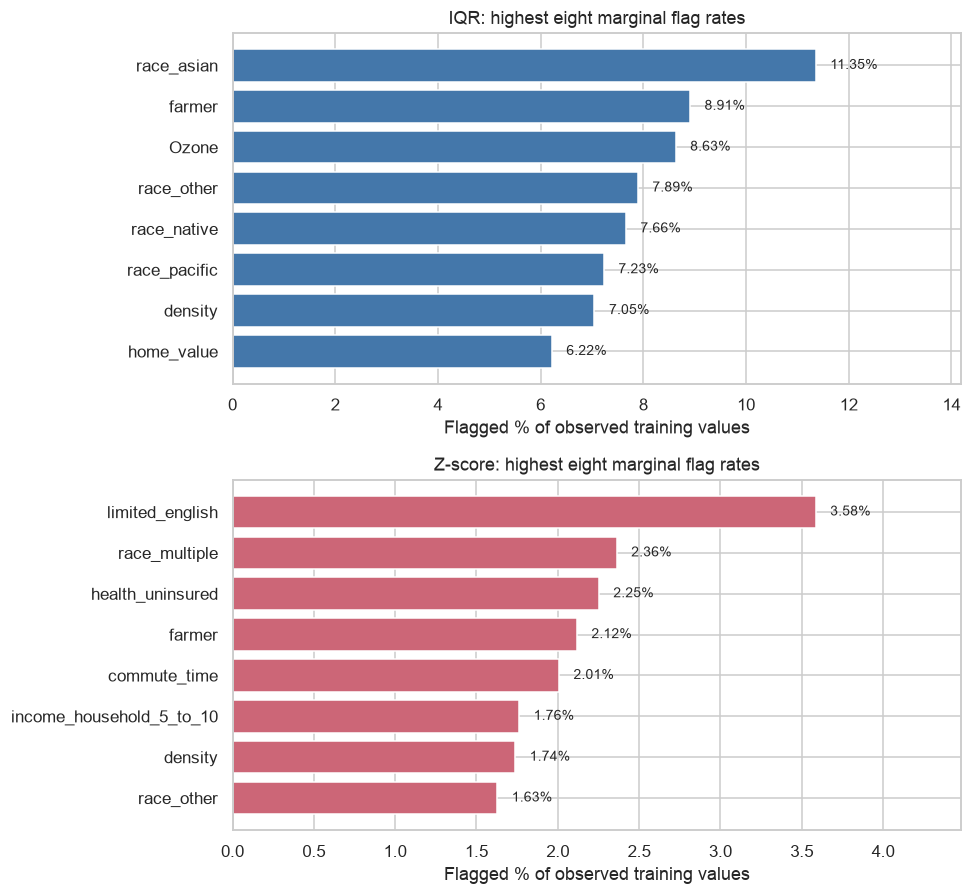

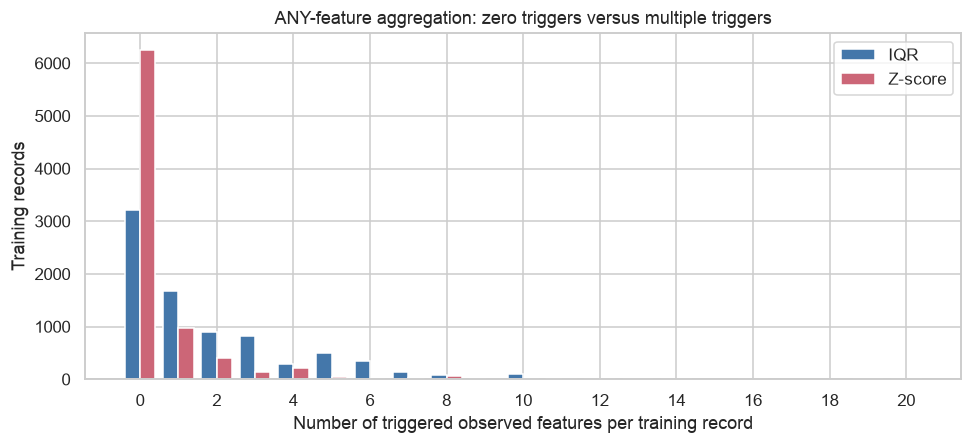

In [23]:
outlier_feature_summary = outlier_feature_audit.join(
    iqr_thresholds[["Q1", "Q3", "IQR", "Lower fence", "Upper fence"]]).join(
    zscore_parameters[["Mean", "SD (ddof 0)"]])
outlier_feature_summary = outlier_feature_summary.join([iqr_feature_counts, iqr_feature_rates, zscore_feature_counts, zscore_feature_rates])
outlier_feature_summary["IQR exception note"] = iqr_thresholds.Note
outlier_feature_summary["Z-score exception note"] = zscore_parameters.Note
display(HTML('<details><summary>All 69 features: support, fitted thresholds, counts, rates and exception notes</summary>'
    '<div style="overflow:auto;max-height:32rem">'+outlier_feature_summary.to_html(float_format="{:.5f}".format)+'</div></details>'))
outlier_comparison = pd.DataFrame([
    {"Method": name, "Rule": rule, "Eligible features": int(eligible.sum()), "Training N": len(train_index),
     "Flagged observations N": int(rows.sum()), "Flagged observations %": rows.mean()*100,
     "Would retain N": int(len(train_index)-rows.sum()), "Flagged feature-values N": int(flags.to_numpy().sum())}
    for name, rule, eligible, rows, flags in [
        ("IQR", "Outside Q1/Q3 ± 1.5 IQR", iqr_thresholds.Eligible, iqr_observation_flags, iqr_feature_flags),
        ("Z-score", "Strict |z| > 3; ddof=0", zscore_parameters.Eligible, zscore_observation_flags, zscore_feature_flags)]
]).set_index("Method")
display(HTML('<div style="overflow-x:auto">'+outlier_comparison.to_html(float_format="{:.4f}".format)+'</div>'))

outlier_groups = pd.Series("Other area context (meaning/period caveats retained)", index=outlier_features)
outlier_groups.loc[["patient_age", "bmi"]] = "Individual measurements"
outlier_groups.loc[list(air_features)] = "Annual ZIP3 air context"
outlier_groups.loc[list(bounded_share_features)] = "Bounded area shares"
outlier_group_summary = pd.DataFrame([
    {"Feature group": group, "Features N": len(columns), "Observed feature-values N": int(outlier_train_original[columns].count().sum()),
     "IQR flagged feature-values N": int(iqr_feature_flags[columns].to_numpy().sum()),
     "Z-score flagged feature-values N": int(zscore_feature_flags[columns].to_numpy().sum())}
    for group, columns in outlier_groups.groupby(outlier_groups, sort=True).groups.items()]).set_index("Feature group")
display(HTML('<div style="overflow-x:auto">'+outlier_group_summary.to_html()+'</div>'))

fig, axes = plt.subplots(2, 1, figsize=(9, 8.3))
for ax, label, rates in [(axes[0], "IQR", iqr_feature_rates), (axes[1], "Z-score", zscore_feature_rates)]:
    selected = rates.nlargest(8).sort_values()
    ax.barh(selected.index, selected.values, color="#4477AA" if label=="IQR" else "#CC6677")
    for y, value in enumerate(selected.values): ax.text(value+selected.max()*.025, y, f"{value:.2f}%", va="center", fontsize=9)
    ax.set(title=f"{label}: highest eight marginal flag rates", xlabel="Flagged % of observed training values")
    ax.set_xlim(0,selected.max()*1.25)
plt.tight_layout();plt.show()

outlier_trigger_distribution = pd.DataFrame({"IQR": iqr_flagged_features_per_row.value_counts(),
    "Z-score": zscore_flagged_features_per_row.value_counts()}).fillna(0).astype(int).sort_index()
fig, ax = plt.subplots(figsize=(9,4.2))
positions = outlier_trigger_distribution.index.to_numpy()
ax.bar(positions-.2,outlier_trigger_distribution.IQR,width=.4,label="IQR",color="#4477AA")
ax.bar(positions+.2,outlier_trigger_distribution["Z-score"],width=.4,label="Z-score",color="#CC6677")
ax.set(xlabel="Number of triggered observed features per training record",ylabel="Training records",
       title="ANY-feature aggregation: zero triggers versus multiple triggers")
ax.set_xticks(np.arange(0,positions.max()+1,max(1,int(positions.max()//10))))
ax.legend();plt.tight_layout();plt.show()

iqr_largest_group = outlier_group_summary["IQR flagged feature-values N"].idxmax()
zscore_largest_group = outlier_group_summary["Z-score flagged feature-values N"].idxmax()
display(HTML(
    f"<p><strong>Preliminary interpretation:</strong> IQR flags {int(iqr_observation_flags.sum()):,} records "
    f"({iqr_observation_flags.mean()*100:.2f}%); Z-score flags {int(zscore_observation_flags.sum()):,} "
    f"({zscore_observation_flags.mean()*100:.2f}%). Largest feature-value contribution: IQR={iqr_largest_group}; "
    f"Z-score={zscore_largest_group}. Group totals also reflect how many columns a group contains.</p>"
    f"<p>For race_pacific, observed-training skewness={outlier_feature_summary.loc['race_pacific','Skewness (observed train)']:.2f}; "
    f"IQR flags {iqr_feature_rates['race_pacific']:.2f}% versus Z-score {zscore_feature_rates['race_pacific']:.2f}%. "
    "This discrepancy is consistent with the different tail sensitivity of quartiles versus mean/SD, "
    "not a separate test identifying its cause. Extreme values can be legitimate; repeated ZIP context and overlapping shares "
    "can multiply flags without providing independent evidence of error. No clinical validity or removal benefit is established.</p>"))


### Part 1 correctness and integrity checks

The IQR fixture has known linear quartiles Q1=1, Q3=3, fences −2 and 6; values exactly on
the fences must remain unflagged. The Z-score fixture has mean 0 and population SD 1:
values ±3 are retained, ±4 are flagged. Separate columns exercise zero IQR, constant/zero SD,
insufficient support, all missing and invalid input. These fixtures validate the two functions
independently of WiDS results. Final checks enforce common row/column alignment, missing-value
exclusion, independent Boolean-count agreement and preservation of train/holdout/raw data.


In [24]:
outlier_checks = {}
iqr_fixture = pd.DataFrame({"x": [-2.1,-2.,0.,1.,1.,1.5,2.,2.5,3.,3.,4.,6.,6.1,np.nan]},
                           index=[f"synthetic_{i}" for i in range(14)])
iqr_fixture_before = iqr_fixture.copy(deep=True)
p_iqr,f_iqr = detect_iqr(iqr_fixture)
np.testing.assert_allclose(p_iqr.loc["x",["Q1","Q3","IQR","Lower fence","Upper fence"]].to_numpy(float),[1.,3.,2.,-2.,6.])
expected_iqr = np.zeros(14,dtype=bool);expected_iqr[[0,12]]=True
np.testing.assert_array_equal(f_iqr.x.to_numpy(),expected_iqr)
pd.testing.assert_frame_equal(iqr_fixture,iqr_fixture_before)
outlier_checks["IQR known quartiles/fences; strict boundaries; NaN false; no mutation"] = True
z_fixture = pd.DataFrame({"x": [-4.,-3.,3.,4.]+[0.]*46+[np.nan]},index=np.arange(51)*3+100)
p_z,s_z,f_z = detect_zscore(z_fixture)
np.testing.assert_allclose(p_z.loc["x",["Mean","SD (ddof 0)"]].to_numpy(float),[0.,1.])
np.testing.assert_allclose(s_z.x.to_numpy(),z_fixture.x.to_numpy(),equal_nan=True)
expected_z = np.zeros(51,dtype=bool);expected_z[[0,3]]=True
np.testing.assert_array_equal(f_z.x.to_numpy(),expected_z)
assert f_z.index.equals(z_fixture.index)
outlier_checks["Known population mean/SD; strict |z|=3 retained; |z|=4 flagged; aligned scores"] = True
edge_fixture = pd.DataFrame({"constant":[2.,2.,2.,2.,2.,np.nan], "zero_iqr":[0.,0.,0.,0.,0.,1.],
    "all_missing":[np.nan]*6, "insufficient":[1.,2.,np.nan,np.nan,np.nan,np.nan],
    "single":[1.,np.nan,np.nan,np.nan,np.nan,np.nan], "invalid":[1.,2.,np.inf,3.,4.,5.]})
edge_before = edge_fixture.copy(deep=True)
ep_i,ef_i = detect_iqr(edge_fixture);ep_z,es_z,ef_z = detect_zscore(edge_fixture)
assert not ep_i.Eligible.any() and not ef_i.to_numpy().any()
assert not ep_z.loc[["constant","all_missing","single","invalid"],"Eligible"].any()
assert ep_z.loc["insufficient","Eligible"] and np.isnan(es_z.loc[0,"constant"])
assert not ef_z[["constant","all_missing","single","invalid"]].to_numpy().any()
pd.testing.assert_frame_equal(edge_fixture,edge_before)
outlier_checks["Zero IQR skipped; zero/invalid SD, insufficient/all-missing/nonfinite columns handled"] = True
for flags,counts,rows in [(iqr_feature_flags,iqr_flagged_features_per_row,iqr_observation_flags),
                          (zscore_feature_flags,zscore_flagged_features_per_row,zscore_observation_flags)]:
    assert flags.index.equals(train_index) and flags.columns.equals(outlier_train_original.columns)
    assert flags.dtypes.eq(bool).all() and rows.index.equals(train_index)
    assert not (flags & outlier_original_missing).to_numpy().any()
    np.testing.assert_array_equal(counts.to_numpy(),np.count_nonzero(flags.to_numpy(),axis=1))
    np.testing.assert_array_equal(rows.to_numpy(),np.any(flags.to_numpy(),axis=1))
    assert int(rows.sum())==int(np.count_nonzero(np.any(flags.to_numpy(),axis=1)))
    assert counts.sum()==flags.to_numpy().sum()
assert outlier_trigger_distribution.sum().eq(len(train_index)).all()
outlier_checks["Real masks: Boolean alignment, no NaN flags, independent per-row counts and ANY totals"] = True
assert outlier_train_original.index.equals(train_index) and set(outlier_features).isdisjoint(forbidden)
for matrix in [outlier_common_train_raw,outlier_common_train_z]:
    assert matrix.index.equals(train_index) and matrix.columns.equals(outlier_train_original.columns)
    assert matrix.shape==outlier_train_original.shape and np.isfinite(matrix.to_numpy()).all()
pd.testing.assert_frame_equal(outlier_common_train_raw.where(~outlier_original_missing),outlier_train_original)
pd.testing.assert_frame_equal(outlier_common_imputed_mask,outlier_original_missing)
np.testing.assert_allclose(expanded_scaler.mean_,outlier_train_original.mean())
np.testing.assert_allclose(expanded_scaler.scale_,outlier_train_original.std(ddof=0))
outlier_checks["One shared training-only preparation; natural-gap provenance; exact known cells; no protected features"] = True
assert hashlib.sha256(pd.util.hash_pandas_object(outlier_train_original,index=True).to_numpy().tobytes()).hexdigest()==outlier_train_hash
pd.testing.assert_frame_equal(outlier_train_original,df.loc[train_index,outlier_features])
for name,index in {"Validation":validation_index,"Reserved":reserved_index}.items():
    assert hashlib.sha256(pd.util.hash_pandas_object(df.loc[index],index=True).to_numpy().tobytes()).hexdigest()==outlier_holdout_hashes[name]
assert hashlib.sha256(pd.util.hash_pandas_object(df,index=True).to_numpy().tobytes()).hexdigest()==frame_hash_before
assert df.dtypes.equals(dtypes_before) and df.shape==shape_before and df.columns.equals(columns_before)
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()==raw_sha_before
outlier_checks["Original training frame, both holdouts, source frame/schema and CSV unchanged"] = True
display(pd.Series(outlier_checks,name="PASS").to_frame())
print("Part 1 checks passed; no removal policy chosen or rows/data exported.")


,PASS
IQR known quartiles/fences; strict boundaries; NaN false; no mutation,True
Known population mean/SD; strict |z|=3 retained; |z|=4 flagged; aligned scores,True
"Zero IQR skipped; zero/invalid SD, insufficient/all-missing/nonfinite columns handled",True
"Real masks: Boolean alignment, no NaN flags, independent per-row counts and ANY totals",True
One shared training-only preparation; natural-gap provenance; exact known cells; no protected features,True
"Original training frame, both holdouts, source frame/schema and CSV unchanged",True


Part 1 checks passed; no removal policy chosen or rows/data exported.


### Reusable handoff and incomplete Stage 03 requirements

| Variable | Purpose |
|---|---|
| `outlier_train_original` | Preserved original 69-feature numerical training frame |
| `outlier_feature_audit`, `outlier_feature_summary` | Eligibility, semantics, observed support and complete per-feature results |
| `outlier_original_missing`, `outlier_common_imputed_mask` | Natural-gap/imputed-estimate provenance |
| `outlier_common_train_raw`, `outlier_common_train_z` | One complete training matrix in original and existing train-conditioned units |
| `iqr_thresholds`, `zscore_parameters`, `outlier_z_scores` | Fitted training parameters and standardized-score audit |
| `iqr_feature_flags`, `zscore_feature_flags` | Aligned Boolean feature-level flags |
| `iqr_observation_flags`, `zscore_observation_flags` | Same-index ANY-feature flags for later comparisons |
| `iqr_flagged_features_per_row`, `zscore_flagged_features_per_row` | Trigger multiplicity per training record |
| `outlier_comparison`, `outlier_group_summary` | Preliminary aggregate comparison and contextual contributions |

With the checks passed, **Part 1 is technically complete**: observed-value thresholds, common
matrix preparation and reusable flags support Part 2. Isolation Forest, LOF and DBSCAN are
**NOT IMPLEMENTED** here. Jaccard and KS distribution-impact analysis, final treatment selection
and any removal are also **NOT IMPLEMENTED**. Stage 03 as a whole is incomplete.

Before later fitting, retain the same feature scope/rows and declared preparation; do not
re-impute separately for detector subsets or use holdouts to select a detector. kNN10's
reconstruction ranking does not establish optimal anomaly geometry, and estimated BMI/context
may influence multivariate distances. Review this limitation alongside temporal eligibility,
ZIP dependence, natural missingness and the absence of verified outlier labels. The later
multivariate and distribution-impact comparisons must inform a treatment decision; Part 1
does not justify automatic deletion. Saved aggregate outputs can build without private CSV
access; local re-execution still requires the project `.venv` and training file.


## 20. Isolation Forest — contamination comparison

**Complete Stage 03 extension.** Sections 16–19 retain the Part 1 handoff as originally executed;
their pending-work statements are superseded by Sections 20–27. Reviewing the observed-value
quartiles, ddof 0, strict comparisons, NaN/degeneracy handling and aligned flags found no
blocking Part 1 bug. Its original source and aggregation rule are unchanged.

All new detectors use the same finite `outlier_common_train_z`, all 69 columns and all inner-training
rows. No new imputer/scaler is fitted and no feature is dropped. IQR/Z-score retain their original
observed-value inputs; the comparison makes this missing-data distinction explicit. Fitting,
distance diagnostics and calibration use training only, not target/ID/ZIP or either holdout.
The shared geometry has 52 area-share coordinates plus other correlated ZIP context; these
coordinates receive separate Euclidean terms/tree-feature opportunities. Common scope aids
comparison but does not establish ideal geometry or independent information. Imputation can
smooth individual differences. Duplicate-row counts and the neighborhood-distance diagnostic
below assess concrete consequences without a feature-removal or alternative-scaling experiment.

**Prespecified settings:** Isolation Forest contamination .01/.05/.10, 100 trees, max_samples=auto
(at most 256), max_features=1, no bootstrap, seed 42; LOF neighbors 10/20/50 with contamination=auto;
DBSCAN min_samples=20 and the deterministic training-only k-distance rule in Section 22. Detected
thread pools and estimator jobs are limited to one. No observation subsampling is used to reduce
the comparison population. Isolation Forest's standard 256-record tree subsamples are an explicit
algorithm setting, not a reduced evaluation dataset. For later ECDF illustrations, BMI and density
and the IQR/IF .05/LOF 20/DBSCAN policies are fixed now to contrast missing-rich individual and skewed
area measurements; all nine policies/all numerical features are still evaluated by KS.

Isolation trees recursively split a random feature at a random cut. Shorter expected isolation
paths indicate unusual points. The paper's score uses

$$
s(x)=2^{-E[h(x)]/c(\psi)},\qquad
c(\psi)=2H_{\psi-1}-2(\psi-1)/\psi.
$$

Here c is the reference path-length normalization. sklearn `score_samples` uses the opposite
orientation (lower is more anomalous); `decision_function = score_samples - offset_` and
`predict == -1` marks negative decisions. Contamination sets a training-score threshold; ties
can affect the exact flagged count. It does not discover the prevalence of data errors.
With identical seeds/settings, different contaminations can threshold the same ranking.
Scores are not probabilities. See the installed [IsolationForest API](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html).


In [25]:
import warnings
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor, NearestNeighbors
from sklearn.cluster import DBSCAN
from scipy.stats import ks_2samp

STAGE03_SEED = 42
STAGE03_ORDER = ["IQR", "Z-score", "IF .01", "IF .05", "IF .10", "LOF 10", "LOF 20", "LOF 50", "DBSCAN"]
KS_ECDF_FEATURES = ["bmi", "density"]
KS_ECDF_POLICIES = ["IQR", "IF .05", "LOF 20", "DBSCAN"]
assert outlier_common_train_z.index.equals(train_index) and list(outlier_common_train_z.columns)==outlier_features
assert set(outlier_features).isdisjoint(forbidden) and np.isfinite(outlier_common_train_z.to_numpy()).all()
stage03_X = outlier_common_train_z.to_numpy(copy=True)
stage03_input_hash = hashlib.sha256(stage03_X.tobytes()).hexdigest()
stage03_models, stage03_labels, stage03_flags = {}, {}, {}
stage03_parameters, stage03_runtimes, stage03_warnings = {}, {}, []
stage03_if_scores, stage03_if_decisions = {}, {}
stage03_duplicate_rows = int(outlier_common_train_z.duplicated().sum())
stage03_max_duplicate_multiplicity = int(outlier_common_train_z.value_counts().max())
display(pd.Series({"Training rows":len(train_index),"Shared features":len(outlier_features),
    "Additional identical rows in complete representation":stage03_duplicate_rows,
    "Maximum identical-row multiplicity":stage03_max_duplicate_multiplicity}).to_frame("Geometry audit"))
for contamination in [.01,.05,.10]:
    name=f"IF {contamination:.2f}".replace("0.",".")
    model=IsolationForest(n_estimators=100,max_samples="auto",contamination=contamination,
                          max_features=1.,bootstrap=False,random_state=STAGE03_SEED,n_jobs=1)
    with threadpool_limits(limits=1):
        start=perf_counter();model.fit(stage03_X)
        labels=model.predict(stage03_X)
        scores=model.score_samples(stage03_X);decisions=model.decision_function(stage03_X)
        elapsed=perf_counter()-start
    assert np.isin(labels,[-1,1]).all() and np.isfinite(scores).all()
    np.testing.assert_allclose(decisions,scores-model.offset_,rtol=0,atol=1e-15)
    np.testing.assert_array_equal(labels==-1,decisions<0)
    stage03_models[name],stage03_labels[name]=model,pd.Series(labels,index=train_index)
    stage03_flags[name]=pd.Series(labels==-1,index=train_index,dtype=bool)
    stage03_if_scores[name]=pd.Series(scores,index=train_index)
    stage03_if_decisions[name]=pd.Series(decisions,index=train_index)
    stage03_parameters[name]=f"contamination={contamination:.2f}; trees=100; samples={model.max_samples_}; seed=42"
    stage03_runtimes[name]=elapsed
display(pd.DataFrame([{"Method":name,"Offset":stage03_models[name].offset_,
    "Flagged N":int(stage03_flags[name].sum()),"Flagged %":stage03_flags[name].mean()*100,
    "Runtime (s)":stage03_runtimes[name]} for name in STAGE03_ORDER[2:5]]).set_index("Method").round(6))
stage03_if_identical_ranking = all(np.array_equal(stage03_if_scores["IF .01"],stage03_if_scores[name]) for name in ["IF .05","IF .10"])
print("Identical raw Isolation Forest scores across contamination settings:",stage03_if_identical_ranking)


,Geometry audit
Training rows,8173
Shared features,69
Additional identical rows in complete representation,1592
Maximum identical-row multiplicity,11


,Offset,Flagged N,Flagged %,Runtime (s)
Method,,,,
IF .01,-0.557097,81,0.991068,0.176168
IF .05,-0.509531,406,4.967576,0.172516
IF .10,-0.489674,817,9.996329,0.237624


Identical raw Isolation Forest scores across contamination settings: True


## 21. Local Outlier Factor — neighborhood sensitivity

LOF compares a point's local reachability density with those of its neighbors:

$$
\operatorname{reach}_k(p,o)=\max\{d_k(o),d(p,o)\},\quad
\operatorname{lrd}_k(p)=\left[\frac1{|N_k(p)|}\sum_{o\in N_k(p)}\operatorname{reach}_k(p,o)\right]^{-1},\quad
\operatorname{LOF}_k(p)=\frac1{|N_k(p)|}\sum_{o\in N_k(p)}\frac{\operatorname{lrd}_k(o)}{\operatorname{lrd}_k(p)}.
$$

Use training `fit_predict`, novelty=False, Euclidean brute-force neighbors and k=10/20/50.
The common policy is contamination=auto; sklearn uses an offset of −1.5 on
`negative_outlier_factor_` (approximately −1 for ordinary local density). Lower values are
more anomalous; labels and thresholded scores are distinct from calibrated probabilities.
No extra contamination search is added. Local definitions need not agree with global isolation.
Neighborhood size, correlated coordinates, distance concentration and repeated/identical area
patterns can materially affect the result. Any sklearn duplicate-distance warnings are recorded,
not repaired by silently changing k. See the [LOF API](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.LocalOutlierFactor.html).


In [26]:
stage03_lof_scores = {}
for k in [10,20,50]:
    name=f"LOF {k}"
    model=LocalOutlierFactor(n_neighbors=k,contamination="auto",novelty=False,
                            algorithm="brute",metric="euclidean",n_jobs=1)
    with threadpool_limits(limits=1),config_context(working_memory=KNN_MEMORY_MIB),warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        start=perf_counter();labels=model.fit_predict(stage03_X);elapsed=perf_counter()-start
    for warning in caught:stage03_warnings.append({"Method":name,"Warning":str(warning.message)})
    scores=model.negative_outlier_factor_.copy()
    assert model.n_neighbors_==k and np.isfinite(scores).all() and np.isin(labels,[-1,1]).all()
    np.testing.assert_array_equal(labels==-1,scores<model.offset_)
    stage03_models[name],stage03_labels[name]=model,pd.Series(labels,index=train_index)
    stage03_flags[name]=pd.Series(labels==-1,index=train_index,dtype=bool)
    stage03_lof_scores[name]=pd.Series(scores,index=train_index)
    stage03_parameters[name]=f"neighbors={model.n_neighbors_}; contamination=auto; Euclidean; novelty=False"
    stage03_runtimes[name]=elapsed
display(pd.DataFrame([{"Method":name,"Actual neighbors":stage03_models[name].n_neighbors_,
    "Offset":stage03_models[name].offset_,"Flagged N":int(stage03_flags[name].sum()),
    "Flagged %":stage03_flags[name].mean()*100,"Runtime (s)":stage03_runtimes[name]} for name in STAGE03_ORDER[5:8]]).set_index("Method").round(6))
if stage03_warnings:display(pd.DataFrame(stage03_warnings))
else:print("No LOF fit warnings recorded; this does not validate neighborhood geometry.")


,Actual neighbors,Offset,Flagged N,Flagged %,Runtime (s)
Method,,,,,
LOF 10,10,-1.5,1691,20.690077,0.186977
LOF 20,20,-1.5,1536,18.793589,0.187895
LOF 50,50,-1.5,1220,14.927199,0.242515


No LOF fit warnings recorded; this does not validate neighborhood geometry.


## 22. DBSCAN — density-based noise detection

DBSCAN connects core points having at least min_samples observations within eps (including
the point itself), adds reachable border points and labels remaining records −1 as noise.
It has no contamination parameter; cluster IDs are arbitrary labels, not anomaly severity.

**Primary calibration fixed in advance:** min_samples=20 is one moderate exploratory local-density
reference, not a proven optimum in 69 dimensions. Query all training points explicitly with
NearestNeighbors.kneighbors(X, n_neighbors=20): the first distance includes the query/self,
so the final distance is to the nineteenth *other* neighbor, consistent with DBSCAN's count.
Calling kneighbors with X=None would exclude self and is not used here.

Sort these distances, normalize rank and distance to [0,1], and choose the first maximum of
rank_norm − distance_norm: the point furthest below the endpoint chord of an increasing convex
curve. This is a deterministic **algorithmic elbow heuristic**, not an objectively unique knee.
Endpoints/extreme tails and changing density can make it ambiguous. A flat curve has no
identifiable elbow; retain its common distance. A zero selected distance uses the smallest
positive k-distance, or machine epsilon if every distance is zero. These fallbacks are declared
before noise counts. Fit one primary DBSCAN; never tune eps to a desired anomaly percentage.

No dense all-pairs matrix is retained. Query radius-neighborhood sizes in batches before fitting;
report edge counts and a conservative allocation estimate. A memory guard must pass before the
bulk sklearn fit. Its worst case is quadratic: chunking neighbor diagnostics does not eliminate
DBSCAN's stored-neighborhood cost. See [DBSCAN](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html)
and [NearestNeighbors](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.NearestNeighbors.html).


,Training k-distance
0.00,0.081496
0.05,0.329822
0.25,0.677823
0.50,1.312577
0.75,3.865238
0.95,6.753287
0.99,10.567842
1.00,22.636713


,DBSCAN calibration / feasibility
min_samples (includes self),2.000000e+01
Selected eps,6.892189e+00
Algorithmic knee rank (zero-based),7.821000e+03
Maximum normalized chord gap,6.550920e-01
Radius edges including self,6.127787e+06
Mean neighbors within eps,7.497598e+02
Maximum neighbors within eps,2.579000e+03
Estimated peak allocation MiB (not measured RSS),3.365564e+02
Conservative available-memory budget MiB,9.774609e+02
Full-data neighbor diagnostic seconds,3.985069e-01


Selection rule: first maximum below endpoint chord


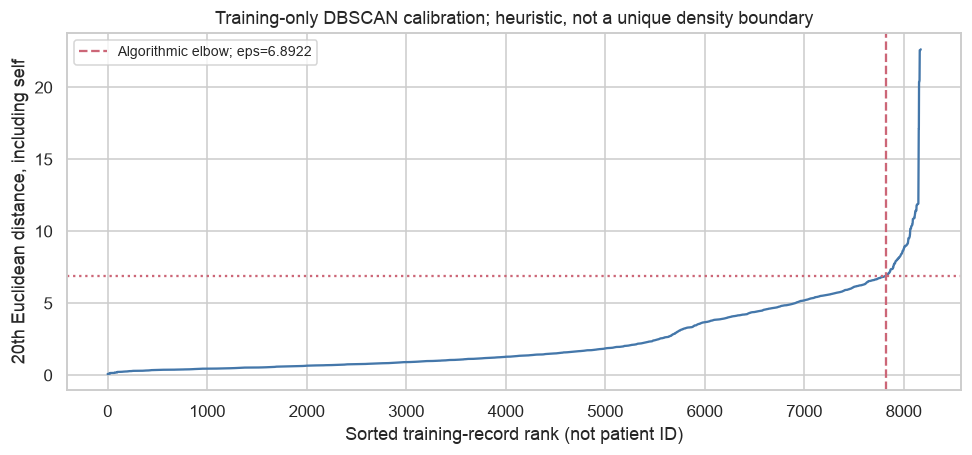

In [27]:
DBSCAN_MIN_SAMPLES=20

def select_dbscan_eps(k_distances):
    """First maximum below the normalized endpoint chord; no outlier counts enter selection."""
    ordered=np.sort(np.asarray(k_distances,dtype=float))
    if len(ordered)<3 or not np.isfinite(ordered).all() or (ordered<0).any():
        raise ValueError("Need at least three finite nonnegative k-distances")
    rank=np.linspace(0.,1.,len(ordered));span=ordered[-1]-ordered[0]
    gap=rank-(ordered-ordered[0])/span if span>0 else np.zeros_like(rank)
    knee=int(np.argmax(gap));eps=float(ordered[knee]);rule="first maximum below endpoint chord"
    if span==0:rule="flat curve: common distance; no identifiable elbow"
    if eps<=0:
        positive=ordered[ordered>0];eps=float(positive[0]) if len(positive) else float(np.finfo(float).eps)
        rule+="; zero-distance fallback as declared"
    return eps,knee,float(gap[knee]),rule

stage03_neighbors=NearestNeighbors(n_neighbors=DBSCAN_MIN_SAMPLES,algorithm="brute",metric="euclidean",n_jobs=1)
with threadpool_limits(limits=1),config_context(working_memory=KNN_MEMORY_MIB):
    start=perf_counter();stage03_neighbors.fit(stage03_X)
    stage03_distances,stage03_neighbor_indices=stage03_neighbors.kneighbors(stage03_X,return_distance=True)
    np.testing.assert_allclose(stage03_distances[:,0],0.,atol=1e-6)
    stage03_k_distances=pd.Series(stage03_distances[:,-1],index=train_index,name="20th distance including self")
    DBSCAN_EPS,stage03_knee_rank,stage03_knee_gap,stage03_eps_rule=select_dbscan_eps(stage03_k_distances)
    stage03_radius_counts=np.empty(len(train_index),dtype=np.int64)
    for start_row in range(0,len(train_index),256):
        stop_row=min(start_row+256,len(train_index))
        neighbors=stage03_neighbors.radius_neighbors(stage03_X[start_row:stop_row],radius=DBSCAN_EPS,return_distance=False)
        stage03_radius_counts[start_row:stop_row]=[len(row) for row in neighbors]
    stage03_neighbor_seconds=perf_counter()-start
del stage03_distances,stage03_neighbor_indices,neighbors
stage03_radius_edges=int(stage03_radius_counts.sum())
stage03_dbscan_peak_estimate_mib=3*stage03_radius_edges*8/1024**2+stage03_X.nbytes/1024**2+KNN_MEMORY_MIB+64
stage03_available_gib=memory_reclaimable
if sys.platform=="darwin":
    vm=subprocess.check_output(["vm_stat"],text=True)
    page_size=int(re.search(r"page size of (\d+) bytes",vm).group(1))
    stage03_available_gib=sum(int(re.search(rf"Pages {key}:\s+(\d+)",vm).group(1)) for key in ["free","inactive","speculative"])*page_size/1024**3
stage03_dbscan_budget_mib=min(memory_total*1024*.25,stage03_available_gib*1024*.75)
stage03_dbscan_feasibility=pd.Series({"min_samples (includes self)":DBSCAN_MIN_SAMPLES,
    "Selected eps":DBSCAN_EPS,"Algorithmic knee rank (zero-based)":stage03_knee_rank,
    "Maximum normalized chord gap":stage03_knee_gap,"Radius edges including self":stage03_radius_edges,
    "Mean neighbors within eps":stage03_radius_counts.mean(),"Maximum neighbors within eps":stage03_radius_counts.max(),
    "Estimated peak allocation MiB (not measured RSS)":stage03_dbscan_peak_estimate_mib,
    "Conservative available-memory budget MiB":stage03_dbscan_budget_mib,"Full-data neighbor diagnostic seconds":stage03_neighbor_seconds})
display(stage03_k_distances.quantile([0,.05,.25,.5,.75,.95,.99,1.]).rename("Training k-distance").to_frame())
display(stage03_dbscan_feasibility.to_frame("DBSCAN calibration / feasibility"))
print("Selection rule:",stage03_eps_rule)
fig,ax=plt.subplots(figsize=(9,4.3))
ax.plot(np.sort(stage03_k_distances),color="#4477AA")
ax.axvline(stage03_knee_rank,color="#CC6677",linestyle="--",label=f"Algorithmic elbow; eps={DBSCAN_EPS:.4f}")
ax.axhline(DBSCAN_EPS,color="#CC6677",linestyle=":")
ax.set(xlabel="Sorted training-record rank (not patient ID)",ylabel="20th Euclidean distance, including self",
       title="Training-only DBSCAN calibration; heuristic, not a unique density boundary")
ax.legend(fontsize=9);plt.tight_layout();plt.show()


The next fit is the single primary DBSCAN configuration. A memory-guard failure is an execution
block requiring a documented measured fallback, not permission to change eps until it looks
convenient. No-noise, all-noise or a single cluster would be reported as observed degeneracy,
not silently replaced. Noise means outside the fitted density structure, not necessarily error.
Repeated ZIP patterns, imputed BMI and high-dimensional correlated terms all influence this structure.


In [28]:
if not np.isfinite(stage03_dbscan_budget_mib) or stage03_dbscan_peak_estimate_mib>stage03_dbscan_budget_mib:
    raise MemoryError(f"DBSCAN estimated {stage03_dbscan_peak_estimate_mib:.1f} MiB exceeds observed budget {stage03_dbscan_budget_mib:.1f} MiB; no eps retuning performed")
stage03_dbscan=DBSCAN(eps=DBSCAN_EPS,min_samples=DBSCAN_MIN_SAMPLES,metric="euclidean",algorithm="brute",n_jobs=1)
with threadpool_limits(limits=1),config_context(working_memory=KNN_MEMORY_MIB):
    start=perf_counter();db_labels=stage03_dbscan.fit_predict(stage03_X);elapsed=perf_counter()-start
assert (db_labels>=-1).all()
stage03_models["DBSCAN"],stage03_labels["DBSCAN"]=stage03_dbscan,pd.Series(db_labels,index=train_index)
stage03_flags["DBSCAN"]=pd.Series(db_labels==-1,index=train_index,dtype=bool)
stage03_parameters["DBSCAN"]=f"eps={DBSCAN_EPS:.8g}; min_samples=20 incl. self; Euclidean"
stage03_runtimes["DBSCAN"]=elapsed
stage03_dbscan_clusters=int(len(set(db_labels)-{-1}))
stage03_dbscan_summary=pd.Series({"Clusters (excluding noise)":stage03_dbscan_clusters,
    "Core records":len(stage03_dbscan.core_sample_indices_),"Noise N":int(stage03_flags["DBSCAN"].sum()),
    "Noise %":stage03_flags["DBSCAN"].mean()*100,"Runtime (s)":elapsed})
display(stage03_dbscan_summary.to_frame("Primary DBSCAN result"))
display(stage03_labels["DBSCAN"].value_counts().sort_index().rename("Records per cluster label (-1 = noise)").to_frame())
print("Noise degeneracy:","all noise" if stage03_flags["DBSCAN"].all() else "no noise" if not stage03_flags["DBSCAN"].any() else "neither all nor no noise")


,Primary DBSCAN result
Clusters (excluding noise),16.000000
Core records,7822.000000
Noise N,291.000000
Noise %,3.560504
Runtime (s),0.239484


,Records per cluster label (-1 = noise)
-1,291
0,7031
1,239
2,171
3,49
4,49
5,32
6,30
7,49
8,57


Noise degeneracy: neither all nor no noise


## 23. Nine-configuration detection comparison

Keep the two original univariate masks and seven new multivariate configurations separately
named, then align by the exact training-row index. Feature scope is 69 in every case, while
IQR/Z-score use observed measurements and multivariate methods use the common completed,
train-conditioned representation. Thus these are different operational anomaly definitions,
not an accuracy benchmark isolating only the algorithm. No labels establish which flags are true.
Rates, counts and hypothetical retained N are descriptive; higher/lower is not inherently better.

The Status column records successful execution and checks, not accuracy or data-quality certification.


,Parameters,Feature scope,Training N,Flagged N,Flagged %,Would retain N,Runtime (s),Status
Method,,,,,,,,
IQR,linear quartiles; strict 1.5 IQR; ANY observed feature,69; observed-only,8173,4953,60.6020,3220,not timed in Part 1,PASS
Z-score,observed train mean/SD; ddof=0; strict |z|>3; ANY,69; observed-only,8173,1915,23.4308,6258,not timed in Part 1,PASS
IF .01,contamination=0.01; trees=100; samples=256; seed=42,69; shared kNN10/train z,8173,81,0.9911,8092,0.1762,PASS
IF .05,contamination=0.05; trees=100; samples=256; seed=42,69; shared kNN10/train z,8173,406,4.9676,7767,0.1725,PASS
IF .10,contamination=0.10; trees=100; samples=256; seed=42,69; shared kNN10/train z,8173,817,9.9963,7356,0.2376,PASS
LOF 10,neighbors=10; contamination=auto; Euclidean; novelty=False,69; shared kNN10/train z,8173,1691,20.6901,6482,0.1870,PASS
LOF 20,neighbors=20; contamination=auto; Euclidean; novelty=False,69; shared kNN10/train z,8173,1536,18.7936,6637,0.1879,PASS
LOF 50,neighbors=50; contamination=auto; Euclidean; novelty=False,69; shared kNN10/train z,8173,1220,14.9272,6953,0.2425,PASS
DBSCAN,eps=6.8921891; min_samples=20 incl. self; Euclidean,69; shared kNN10/train z,8173,291,3.5605,7882,0.2395,PASS


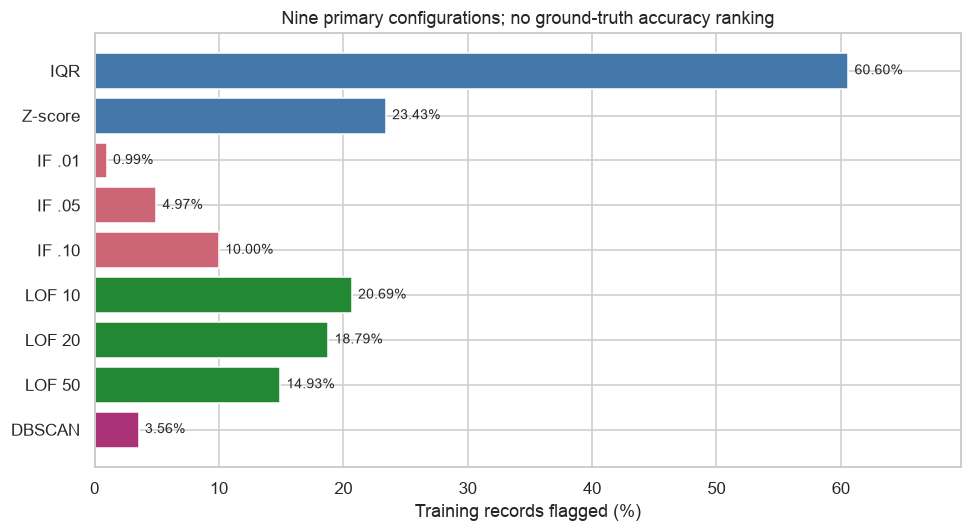

In [29]:
stage03_flags["IQR"],stage03_flags["Z-score"]=iqr_observation_flags.copy(),zscore_observation_flags.copy()
stage03_parameters["IQR"]="linear quartiles; strict 1.5 IQR; ANY observed feature"
stage03_parameters["Z-score"]="observed train mean/SD; ddof=0; strict |z|>3; ANY"
for name in STAGE03_ORDER:
    assert stage03_flags[name].index.equals(train_index) and stage03_flags[name].dtype==bool and not stage03_flags[name].isna().any()
all_outlier_flags=pd.DataFrame({name:stage03_flags[name] for name in STAGE03_ORDER},index=train_index)
assert all_outlier_flags.shape==(len(train_index),9) and not all_outlier_flags.isna().any().any()
stage03_full_comparison=pd.DataFrame([{"Method":name,"Parameters":stage03_parameters[name],
    "Feature scope":"69; observed-only" if name in ["IQR","Z-score"] else "69; shared kNN10/train z",
    "Training N":len(train_index),"Flagged N":int(all_outlier_flags[name].sum()),
    "Flagged %":all_outlier_flags[name].mean()*100,"Would retain N":int((~all_outlier_flags[name]).sum()),
    "Runtime (s)":stage03_runtimes.get(name,np.nan),"Status":"PASS"} for name in STAGE03_ORDER]).set_index("Method")
display(HTML('<div style="overflow:auto">'+stage03_full_comparison.to_html(float_format="{:.4f}".format,na_rep="not timed in Part 1")+'</div>'))
fig,ax=plt.subplots(figsize=(9,5))
ax.barh(STAGE03_ORDER,stage03_full_comparison["Flagged %"],color=["#4477AA"]*2+["#CC6677"]*3+["#228833"]*3+["#AA3377"])
ax.invert_yaxis()
for i,value in enumerate(stage03_full_comparison["Flagged %"]):ax.text(value+.5,i,f"{value:.2f}%",va="center",fontsize=9)
ax.set_xlim(0,max(10,stage03_full_comparison["Flagged %"].max()*1.15))
ax.set(xlabel="Training records flagged (%)",title="Nine primary configurations; no ground-truth accuracy ranking")
plt.tight_layout();plt.show()


## 24. Jaccard overlap analysis

$$
J(A,B)=\frac{|A\cap B|}{|A\cup B|}.
$$

Use actual aligned training-row identities. Two empty sets have undefined 0/0, stored as NaN;
an empty/nonempty pair has similarity zero. Nonempty self-similarity is one. Report intersections
and unions as well as ratios, so agreement with very different flag prevalences is auditable.
Agreement does not imply correctness: IF thresholds can partition an identical score ordering,
and local/global/marginal/density methods need not identify the same kind of unusual record.
No treatment is selected solely by overlap.


,IQR,Z-score,IF .01,IF .05,IF .10,LOF 10,LOF 20,LOF 50,DBSCAN
IQR,1.000,0.387,0.016,0.082,0.165,0.187,0.172,0.158,0.059
Z-score,0.387,1.000,0.042,0.192,0.334,0.134,0.158,0.172,0.142
IF .01,0.016,0.042,1.000,0.200,0.099,0.021,0.035,0.024,0.240
IF .05,0.082,0.192,0.200,1.000,0.497,0.056,0.068,0.088,0.305
IF .10,0.165,0.334,0.099,0.497,1.000,0.081,0.079,0.172,0.197
LOF 10,0.187,0.134,0.021,0.056,0.081,1.000,0.380,0.154,0.053
LOF 20,0.172,0.158,0.035,0.068,0.079,0.380,1.000,0.279,0.115
LOF 50,0.158,0.172,0.024,0.088,0.172,0.154,0.279,1.000,0.120
DBSCAN,0.059,0.142,0.240,0.305,0.197,0.053,0.115,0.120,1.000


,IQR,Z-score,IF .01,IF .05,IF .10,LOF 10,LOF 20,LOF 50,DBSCAN
IQR,4953,1915,81,406,817,1046,953,841,291
Z-score,1915,1915,81,374,684,427,470,461,275
IF .01,81,81,81,81,81,36,55,31,72
IF .05,406,374,81,406,406,111,123,131,163
IF .10,817,684,81,406,817,188,172,299,182
LOF 10,1046,427,36,111,188,1691,889,389,99
LOF 20,953,470,55,123,172,889,1536,602,188
LOF 50,841,461,31,131,299,389,602,1220,162
DBSCAN,291,275,72,163,182,99,188,162,291


,IQR,Z-score,IF .01,IF .05,IF .10,LOF 10,LOF 20,LOF 50,DBSCAN
IQR,4953,4953,4953,4953,4953,5598,5536,5332,4953
Z-score,4953,1915,1915,1947,2048,3179,2981,2674,1931
IF .01,4953,1915,81,406,817,1736,1562,1270,300
IF .05,4953,1947,406,406,817,1986,1819,1495,534
IF .10,4953,2048,817,817,817,2320,2181,1738,926
LOF 10,5598,3179,1736,1986,2320,1691,2338,2522,1883
LOF 20,5536,2981,1562,1819,2181,2338,1536,2154,1639
LOF 50,5332,2674,1270,1495,1738,2522,2154,1220,1349
DBSCAN,4953,1931,300,534,926,1883,1639,1349,291


,Method A,Method B,Intersection N,Union N,Jaccard
21,IF .05,IF .10,406,817,0.49694
0,IQR,Z-score,1915,4953,0.38663
30,LOF 10,LOF 20,889,2338,0.38024


,Method A,Method B,Intersection N,Union N,Jaccard
1,IQR,IF .01,81,4953,0.01635
17,IF .01,LOF 10,36,1736,0.02074
19,IF .01,LOF 50,31,1270,0.02441


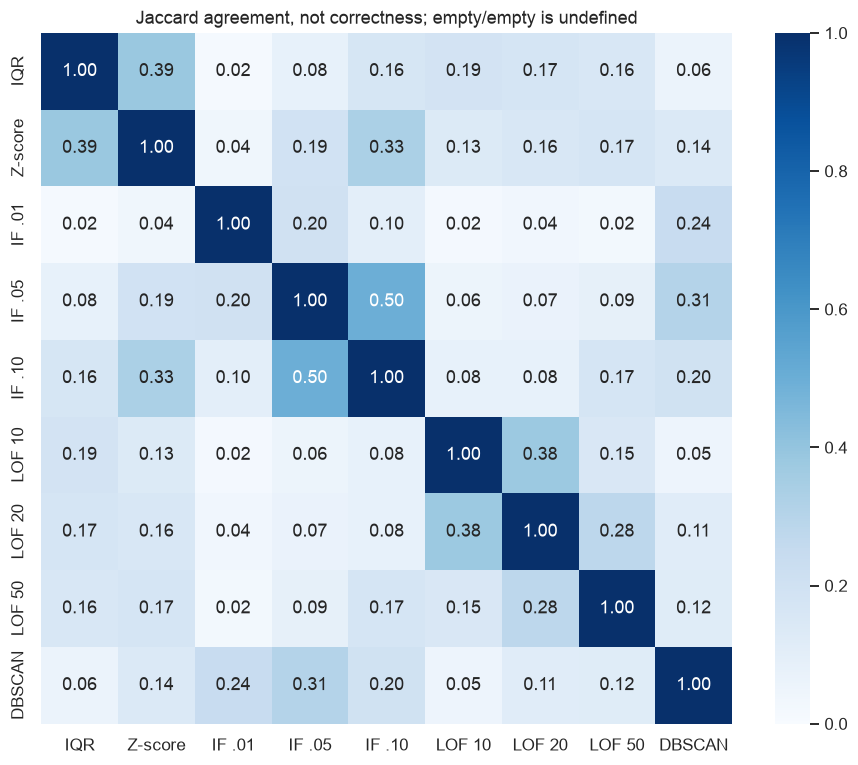

In [30]:
def jaccard_matrices(flag_frame):
    """Aligned Boolean frame -> Jaccard, intersection and union matrices; empty/empty is NaN."""
    if not flag_frame.index.is_unique or flag_frame.isna().any().any() or not flag_frame.dtypes.eq(bool).all():
        raise ValueError("Need unique row identities and nonmissing Boolean flags")
    binary=flag_frame.to_numpy(dtype=np.int64)
    intersection=binary.T@binary
    sizes=binary.sum(axis=0);union=sizes[:,None]+sizes[None,:]-intersection
    similarity=np.divide(intersection,union,out=np.full(union.shape,np.nan,dtype=float),where=union>0)
    names=flag_frame.columns
    return (pd.DataFrame(similarity,index=names,columns=names),pd.DataFrame(intersection,index=names,columns=names),
            pd.DataFrame(union,index=names,columns=names))

stage03_jaccard,stage03_intersections,stage03_unions=jaccard_matrices(all_outlier_flags)
stage03_pair_rows=[]
for i,left in enumerate(STAGE03_ORDER):
    for right in STAGE03_ORDER[i+1:]:
        stage03_pair_rows.append({"Method A":left,"Method B":right,"Intersection N":int(stage03_intersections.loc[left,right]),
            "Union N":int(stage03_unions.loc[left,right]),"Jaccard":stage03_jaccard.loc[left,right]})
stage03_pairs=pd.DataFrame(stage03_pair_rows)
display(stage03_jaccard.style.format("{:.3f}",na_rep="undefined"))
for label,matrix in [("Intersections: all 9×9 counts",stage03_intersections),("Unions: all 9×9 counts",stage03_unions)]:
    display(HTML('<details><summary>'+label+'</summary><div style="overflow:auto">'+matrix.to_html()+'</div></details>'))
stage03_highest_pairs=stage03_pairs.dropna(subset=["Jaccard"]).sort_values("Jaccard",ascending=False,kind="stable").head(3)
stage03_lowest_pairs=stage03_pairs.dropna(subset=["Jaccard"]).sort_values("Jaccard",kind="stable").head(3)
display(stage03_highest_pairs.round(5));display(stage03_lowest_pairs.round(5))
fig,ax=plt.subplots(figsize=(8.5,7))
sns.heatmap(stage03_jaccard,annot=True,fmt=".2f",vmin=0,vmax=1,cmap="Blues",mask=stage03_jaccard.isna(),square=True,ax=ax)
ax.set(title="Jaccard agreement, not correctness; empty/empty is undefined")
plt.tight_layout();plt.show()


## 25. Outlier-removal impact and KS analysis

Create nine **independent hypothetical retained subsets**, each starting from the same original
observed-value training frame. Remove only that policy's flagged rows, preserving order, columns,
values and natural NaNs. No validation/reserved row is removed; no CSV is overwritten or cleaned
patient table exported. The original data remain available regardless of policy.

Report retained/removed N, retention%, remaining/lost ZIP groups and missingness/composition
diagnostics. ZIP is used only here for interpretation, after all detector choices are fixed.
Losing many records/areas can induce selection bias even if tails become narrower. IQR's large
ANY-feature removal rate deserves particular caution rather than automatic adoption.


In [31]:
stage03_retained_training={}
stage03_treatment_rows=[]
stage03_training_zips=df.loc[train_index,ZIP]
for name in STAGE03_ORDER:
    retained=outlier_train_original.loc[~all_outlier_flags[name]].copy(deep=True)
    stage03_retained_training[name]=retained
    remaining_zips=int(stage03_training_zips.loc[retained.index].nunique())
    stage03_treatment_rows.append({"Method":name,"Original N":len(train_index),"Removed N":int(all_outlier_flags[name].sum()),
        "Retained N":len(retained),"Retention %":len(retained)/len(train_index)*100,
        "ZIP groups before":stage03_training_zips.nunique(),"ZIP groups retained":remaining_zips,
        "ZIP groups lost":int(stage03_training_zips.nunique()-remaining_zips),
        "BMI observed before":int(outlier_train_original.bmi.count()),"BMI observed retained":int(retained.bmi.count()),
        "BMI missing % retained":retained.bmi.isna().mean()*100 if len(retained) else np.nan,
        "All cells missing % retained":retained.isna().to_numpy().mean()*100 if len(retained) else np.nan})
stage03_treatment_summary=pd.DataFrame(stage03_treatment_rows).set_index("Method")
display(HTML('<div style="overflow:auto">'+stage03_treatment_summary.to_html(float_format="{:.4f}".format)+'</div>'))
print(f"Reference BMI missing%={outlier_train_original.bmi.isna().mean()*100:.4f}; all-cell missing%={outlier_original_missing.to_numpy().mean()*100:.4f}.")


,Original N,Removed N,Retained N,Retention %,ZIP groups before,ZIP groups retained,ZIP groups lost,BMI observed before,BMI observed retained,BMI missing % retained,All cells missing % retained
Method,,,,,,,,,,,
IQR,8173,4953,3220,39.3980,443,124,319,2531,945,70.6522,1.0239
Z-score,8173,1915,6258,76.5692,443,263,180,2531,1916,69.3832,1.0056
IF .01,8173,81,8092,99.0089,443,425,18,2531,2509,68.9941,1.0069
IF .05,8173,406,7767,95.0324,443,396,47,2531,2426,68.7653,1.0039
IF .10,8173,817,7356,90.0037,443,363,80,2531,2282,68.9777,1.0074
LOF 10,8173,1691,6482,79.3099,443,338,105,2531,1586,75.5322,1.1101
LOF 20,8173,1536,6637,81.2064,443,335,108,2531,1837,72.3218,1.0488
LOF 50,8173,1220,6953,85.0728,443,351,92,2531,2072,70.1999,1.0243
DBSCAN,8173,291,7882,96.4395,443,391,52,2531,2447,68.9546,0.9993


Reference BMI missing%=69.0322; all-cell missing%=1.0138.


### KS D is descriptive; nominal p-values are not calibrated here

For each policy and numerical feature, compare originally observed training values with its
retained observed values, dropping natural NaNs independently. No imputed value enters KS.

$$
D_{n,m}=\sup_x|F_n(x)-G_m(x)|.
$$

Use scipy.stats.ks_2samp, alternative=two-sided, method=asymp: this avoids expensive exact
calculations over 621 large comparisons. Require at least two observed values in each sample;
otherwise record unavailable metrics and an explicit status. Returned numerical zeros in p
are labeled numerical-zero/underflow, not literal zero probability.

**Validity limit:** retained observations are a selected subset of the original sample, not an
independent sample. ZIP repetition and ties also violate classical assumptions. KS D remains
a useful empirical distribution distance; the printed p-values are **nominal exploratory
reference values under violated assumptions**, not calibrated significance evidence. There is
no significance classification, multiple-testing correction, or p-value-based success/removal
decision. Small D does not prove quality, and removing tails cannot establish predictive benefit.
See the [SciPy KS reference](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ks_2samp.html).


,Features evaluated,Unavailable features,Median KS D,Maximum KS D,Largest-shift feature,Largest-shift role,Numerical-zero p N
Method,,,,,,,
IQR,69,0,0.157277,0.243606,education_less_highschool,"Area share [0,100]",0
Z-score,69,0,0.044664,0.075565,rent_burden,Area numerical summary,0
IF .01,69,0,0.003530,0.007267,income_household_75_to_100,"Area share [0,100]",0
IF .05,69,0,0.013548,0.033769,income_household_75_to_100,"Area share [0,100]",0
IF .10,69,0,0.025702,0.053237,income_household_75_to_100,"Area share [0,100]",0
LOF 10,69,0,0.009636,0.067298,bmi,Individual BMI,0
LOF 20,69,0,0.012187,0.048877,bmi,Individual BMI,0
LOF 50,69,0,0.020538,0.039516,income_household_35_to_50,"Area share [0,100]",0
DBSCAN,69,0,0.007903,0.015522,income_household_75_to_100,"Area share [0,100]",0


Method,Feature,Semantic role,Original observed N,Retained observed N,KS D,Nominal KS p (dependent samples),p-value note,Status
IQR,patient_age,Individual age,8173,3220,0.0228734897,0.175521191,nominal only; dependence/ties not calibrated,COMPUTED: descriptive D; nominal p
IQR,bmi,Individual BMI,2531,945,0.0240881848,0.810277778,nominal only; dependence/ties not calibrated,COMPUTED: descriptive D; nominal p
IQR,population,Area numerical summary,8173,3220,0.191760516,7.17879968e-75,nominal only; dependence/ties not calibrated,COMPUTED: descriptive D; nominal p
IQR,density,Area numerical summary,8173,3220,0.220710178,2.62792916e-99,nominal only; dependence/ties not calibrated,COMPUTED: descriptive D; nominal p
IQR,age_median,Area numerical summary,8173,3220,0.158618592,3.10319312e-51,nominal only; dependence/ties not calibrated,COMPUTED: descriptive D; nominal p
IQR,age_under_10,"Area share [0,100]",8173,3220,0.177737065,2.61969051e-64,nominal only; dependence/ties not calibrated,COMPUTED: descriptive D; nominal p
IQR,age_10_to_19,"Area share [0,100]",8173,3220,0.127132172,5.25313322e-33,nominal only; dependence/ties not calibrated,COMPUTED: descriptive D; nominal p
IQR,age_20s,"Area share [0,100]",8173,3220,0.181668317,3.47261436e-67,nominal only; dependence/ties not calibrated,COMPUTED: descriptive D; nominal p
IQR,age_30s,"Area share [0,100]",8173,3220,0.122509201,1.13082465e-30,nominal only; dependence/ties not calibrated,COMPUTED: descriptive D; nominal p
IQR,age_40s,"Area share [0,100]",8173,3220,0.0902147124,8.25948498e-17,nominal only; dependence/ties not calibrated,COMPUTED: descriptive D; nominal p


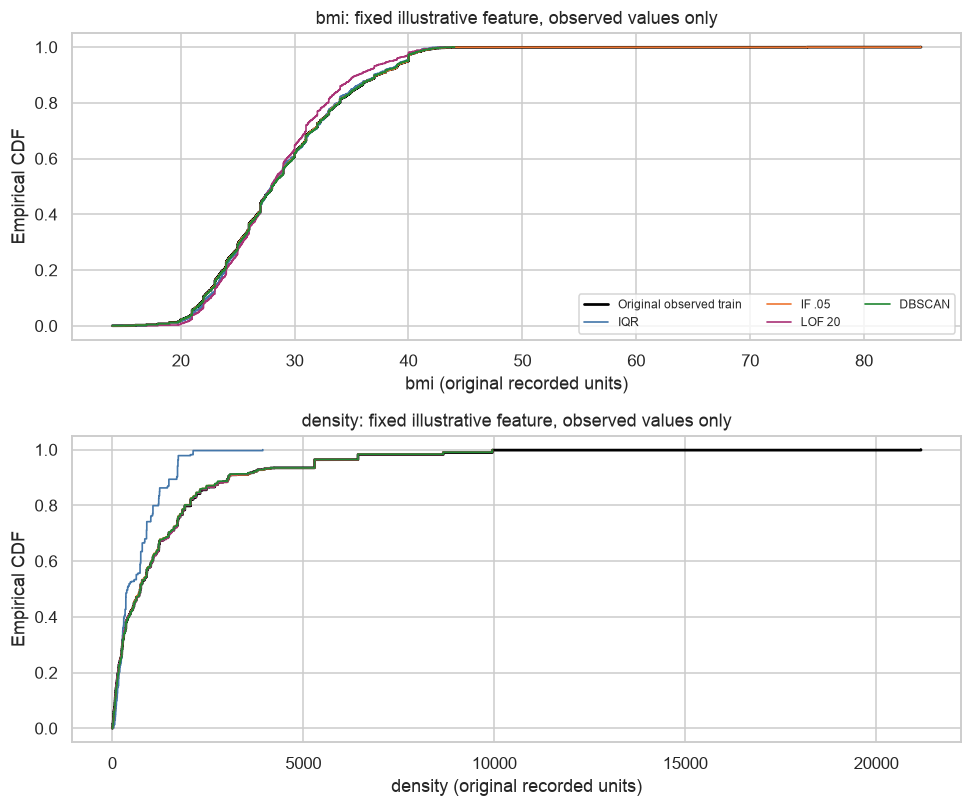

In [32]:
def ks_observed_change(before,retained):
    """Observed-only two-sided KS; nominal p-values do not fix nested-sample dependence."""
    a=before.dropna().to_numpy(dtype=float);b=retained.dropna().to_numpy(dtype=float)
    result={"Original observed N":len(a),"Retained observed N":len(b),"KS D":np.nan,
            "Nominal KS p (dependent samples)":np.nan,"p-value note":"not evaluated","Status":"NOT EVALUATED: observed N<2"}
    if len(a)<2 or len(b)<2:return result
    if not np.isfinite(a).all() or not np.isfinite(b).all():
        result["Status"]="NOT EVALUATED: nonfinite observations";return result
    test=ks_2samp(a,b,alternative="two-sided",method="asymp")
    result.update({"KS D":float(test.statistic),"Nominal KS p (dependent samples)":float(test.pvalue),
        "p-value note":"numerical-zero/underflow; not literal zero probability" if test.pvalue==0 else "nominal only; dependence/ties not calibrated",
        "Status":"COMPUTED: descriptive D; nominal p"})
    return result

stage03_ks_rows=[]
for name in STAGE03_ORDER:
    for feature in outlier_features:
        stage03_ks_rows.append({"Method":name,"Feature":feature,
            "Semantic role":outlier_feature_audit.loc[feature,"Semantic role"],
            **ks_observed_change(outlier_train_original[feature],stage03_retained_training[name][feature])})
stage03_ks_results=pd.DataFrame(stage03_ks_rows)
stage03_ks_summary_rows=[]
for name in STAGE03_ORDER:
    rows=stage03_ks_results[stage03_ks_results.Method.eq(name)];valid=rows.dropna(subset=["KS D"])
    largest=valid.loc[valid["KS D"].idxmax()] if len(valid) else None
    stage03_ks_summary_rows.append({"Method":name,"Features evaluated":len(valid),"Unavailable features":len(rows)-len(valid),
        "Median KS D":valid["KS D"].median(),"Maximum KS D":valid["KS D"].max(),
        "Largest-shift feature":largest.Feature if largest is not None else "unavailable",
        "Largest-shift role":largest["Semantic role"] if largest is not None else "unavailable",
        "Numerical-zero p N":int(valid["Nominal KS p (dependent samples)"].eq(0).sum())})
stage03_ks_summary=pd.DataFrame(stage03_ks_summary_rows).set_index("Method")
display(HTML('<div style="overflow:auto">'+stage03_ks_summary.to_html(float_format="{:.6f}".format)+'</div>'))
display(HTML('<details><summary>All 621 observed-value KS comparisons — D and nominal uncalibrated p-values</summary>'
    '<div style="overflow:auto;max-height:32rem">'+stage03_ks_results.to_html(index=False,float_format="{:.9g}".format)+'</div></details>'))
fig,axes=plt.subplots(2,1,figsize=(9,7.5))
colors={"IQR":"#4477AA","IF .05":"#EE7733","LOF 20":"#AA3377","DBSCAN":"#228833"}
for ax,feature in zip(axes,KS_ECDF_FEATURES):
    original=np.sort(outlier_train_original[feature].dropna().to_numpy())
    ax.step(original,np.arange(1,len(original)+1)/len(original),where="post",color="black",linewidth=1.8,label="Original observed train")
    for name in KS_ECDF_POLICIES:
        values=np.sort(stage03_retained_training[name][feature].dropna().to_numpy())
        if len(values):ax.step(values,np.arange(1,len(values)+1)/len(values),where="post",color=colors[name],linewidth=1.1,label=name)
    ax.set(title=f"{feature}: fixed illustrative feature, observed values only",xlabel=f"{feature} (original recorded units)",ylabel="Empirical CDF")
axes[0].legend(fontsize=8,ncol=3);plt.tight_layout();plt.show()


## 26. Treatment recommendation and limitations

Detection, distribution-impact evaluation and adoption are separate decisions. Use the actual
counts/agreement/KS summaries below, without ranking by nominal p-values or automatically
choosing the smallest flagged set. There are no verified error labels, confirmed physical
impossibilities or downstream experiments establishing removal benefit. The conservative
retention policy therefore preserves observations and stores flags for investigation; the
hypothetical retained subsets remain comparisons, not finalized cleaned data.

IQR/Z-score respond differently to skewness and the 69-feature ANY rule. IF contamination changes
thresholds rather than necessarily the ranking. LOF uses local density and k-sensitive geometry;
DBSCAN depends on a heuristic eps and a single density scale. Repeated ZIP measurements and
overlapping shares can dominate global isolation, neighborhoods and the sorted k-distance curve.
High-dimensional Euclidean terms, skewed marginals and missing-rich BMI imputation constrain all
interpretations. These effects are limitations, not verified causal explanations of a score.

Statistical rarity is not a clinical/data-entry error. BMI/treatment timing, unknown exposure
periods/units and conflicting dictionary entries still constrain prospective eligibility.
Row removal can alter geographic representation and the subset with observed BMI. KS measures
that alteration, not quality improvement; its nominal p-values are not formally calibrated here.
No detector or agreement consensus is universally best. Actual predictive preprocessing remains
future work: refit appropriate transformations/detectors within development folds, respect
training-versus-novelty APIs, validate effects and eligibility, then use the reserve only after
choices are fixed. No classifier is trained and no separate Scaling comparison is completed.


In [33]:
stage03_retention_policy={"Decision":"Preserve all original observations; retain all nine anomaly flags for investigation",
    "Automatic deletion":False,"Reason":"No verified outlier truth or demonstrated removal benefit; substantial selection/geometry risks",
    "Predictive pipeline":"Not finalized; requires fold-local downstream validation and temporal eligibility"}
stage03_adopted_training_rows=train_index.copy()
largest_pair=stage03_highest_pairs.iloc[0] if len(stage03_highest_pairs) else None
smallest_pair=stage03_lowest_pairs.iloc[0] if len(stage03_lowest_pairs) else None
display(HTML(pd.Series(stage03_retention_policy).to_frame("Treatment decision").to_html()))
display(HTML(
    f"<p><strong>Actual evidence:</strong> nine configurations flag between {stage03_full_comparison['Flagged %'].min():.2f}% "
    f"and {stage03_full_comparison['Flagged %'].max():.2f}% of the same training records. "
    f"IF raw-score equality across contamination={stage03_if_identical_ranking}; differing IF overlaps reflect thresholded sets. "
    f"The strongest reported pair is {largest_pair['Method A']} / {largest_pair['Method B']} "
    f"(J={largest_pair.Jaccard:.4f}); the weakest is {smallest_pair['Method A']} / {smallest_pair['Method B']} "
    f"(J={smallest_pair.Jaccard:.4f}). Agreement does not validate either flag set.</p>"
    f"<p>Primary DBSCAN: eps={DBSCAN_EPS:.6f}, min_samples={DBSCAN_MIN_SAMPLES}, clusters={stage03_dbscan_clusters}, "
    f"noise={stage03_full_comparison.loc['DBSCAN','Flagged %']:.2f}%. Its heuristic/radius diagnostic used all training rows, "
    f"{stage03_neighbor_seconds:.3f}s; estimated peak allocation={stage03_dbscan_peak_estimate_mib:.1f} MiB "
    f"(not measured RSS). No eps search based on noise rates was performed.</p>"
    f"<p>IQR's hypothetical removal retains {stage03_treatment_summary.loc['IQR','Retained N']} records and loses "
    f"{stage03_treatment_summary.loc['IQR','ZIP groups lost']} ZIP groups; maximum observed-feature KS D="
    f"{stage03_ks_summary.loc['IQR','Maximum KS D']:.4f}. "
    "Such sample loss/composition changes require justification beyond tail reduction. All original rows remain adopted; "
    "no candidate subset is exported or silently chosen as the predictive dataset.</p>"))

small_pair_size=min(int(all_outlier_flags[smallest_pair["Method A"]].sum()),int(all_outlier_flags[smallest_pair["Method B"]].sum()))
display(HTML(
    f"<p>The lowest-Jaccard pair shares {int(smallest_pair['Intersection N'])} of its smaller set's {small_pair_size} flags. "
    "A low ratio can coexist with complete containment when flag-set sizes differ, so it must not be described as necessarily disjoint. "
    f"LOF rates across k=10/20/50 are {stage03_full_comparison.loc['LOF 10','Flagged %']:.2f}%, "
    f"{stage03_full_comparison.loc['LOF 20','Flagged %']:.2f}% and {stage03_full_comparison.loc['LOF 50','Flagged %']:.2f}%; "
    "this observed neighborhood sensitivity is not an accuracy ranking.</p>"
    f"<p>Under LOF 10 removal, BMI missingness would change from {outlier_train_original.bmi.isna().mean()*100:.2f}% "
    f"to {stage03_treatment_summary.loc['LOF 10','BMI missing % retained']:.2f}%. "
    f"The complete representation contains {stage03_duplicate_rows} additional identical rows (maximum multiplicity "
    f"{stage03_max_duplicate_multiplicity}). These are concrete selection/geometry concerns; attributing them specifically "
    "to imputation or geography would require a separate controlled analysis, not an unsupported causal explanation.</p>"
))


,Treatment decision
Decision,Preserve all original observations; retain all nine anomaly flags for investigation
Automatic deletion,False
Reason,No verified outlier truth or demonstrated removal benefit; substantial selection/geometry risks
Predictive pipeline,Not finalized; requires fold-local downstream validation and temporal eligibility


## 27. Reproducibility, verification and Stage 03 conclusion

Independent fixtures check sklearn label conversion, known density-separated noise, row filtering,
NaN exclusion, known KS D and Jaccard identical/disjoint/partial/empty cases. Real checks compare
every overlap count with Python sets of row identities, validate all nine model/mask/count mappings,
and reproduce one IF/LOF fit without changing primary configurations. These verification fits
are excluded from the primary runtime table. Raw/source/holdout matrices remain unchanged.

When these checks pass, detection, nine candidate removal comparisons and their descriptive
distribution impact are complete. The explicit adoption decision is to keep original observations
with review flags. This is completion of the scoped Outlier Detection & Treatment experiments,
not a grade, clinical certification, finalized predictive pipeline or evidence of classifier gain.
Stage 04 Scaling can proceed as a separately controlled development experiment; existing internal
conditioning is not that rubric stage. Saved aggregate outputs publish without distributing CSVs
or executing notebooks in CI. No private patient-level retained records are printed/exported.


In [34]:
stage03_final_checks={}
toy_index=pd.Index([f"fixture_{i}" for i in range(41)])
toy=np.r_[np.linspace(-.1,.1,40)[:,None],[[9.]]]
with threadpool_limits(limits=1):
    toy_if=IsolationForest(n_estimators=32,contamination=.1,random_state=STAGE03_SEED,n_jobs=1).fit(toy)
    toy_if_labels=toy_if.predict(toy)
    toy_lof=LocalOutlierFactor(n_neighbors=5,contamination="auto",algorithm="brute",metric="euclidean",n_jobs=1)
    toy_lof_labels=toy_lof.fit_predict(toy)
    toy_db_labels=DBSCAN(eps=.15,min_samples=4,algorithm="brute",n_jobs=1).fit_predict(toy)
for labels in [toy_if_labels,toy_lof_labels,toy_db_labels]:
    converted=pd.Series(labels==-1,index=toy_index,dtype=bool)
    assert converted.iloc[-1] and converted.index.equals(toy_index)
    assert set(converted.index[converted])==set(toy_index[np.flatnonzero(labels==-1)])
np.testing.assert_array_equal(toy_db_labels[:-1],np.zeros(40,dtype=int));assert toy_db_labels[-1]==-1
stage03_final_checks["Independent IF/LOF/DBSCAN label conversion and density-separated fixture"] = True
fixture_flags=pd.DataFrame({"A":[True,True,False,False],"Identical":[True,True,False,False],
    "Disjoint":[False,False,True,True],"Partial":[False,True,True,False],"Empty":[False]*4},index=["a","b","c","d"])
j,i,u=jaccard_matrices(fixture_flags)
assert j.loc["A","Identical"]==1 and j.loc["A","Disjoint"]==0
np.testing.assert_allclose(j.loc["A","Partial"],1/3)
assert i.loc["A","Partial"]==1 and u.loc["A","Partial"]==3
assert np.isnan(j.loc["Empty","Empty"]) and j.loc["A","Empty"]==0
bad=fixture_flags.astype(object);bad.iloc[0,0]=None
try:jaccard_matrices(bad)
except ValueError:pass
else:raise AssertionError("Missing/misaligned identity flags were accepted")
stage03_final_checks["Jaccard identical/disjoint/partial/empty and invalid-input fixtures"] = True
known=ks_observed_change(pd.Series([0.,1.,2.,3.,np.nan]),pd.Series([0.,1.,np.nan]))
assert known["Original observed N"]==4 and known["Retained observed N"]==2
np.testing.assert_allclose(known["KS D"],.5)
np.testing.assert_allclose(ks_observed_change(pd.Series([0.,0.]),pd.Series([1.,1.]))["KS D"],1.)
assert np.isnan(ks_observed_change(pd.Series([0.,1.]),pd.Series([np.nan]))["KS D"])
toy_frame=pd.DataFrame({"x":[0.,1.,np.nan,3.]},index=["a","b","c","d"]);toy_before=toy_frame.copy(deep=True)
toy_flag=pd.Series([False,True,False,False],index=toy_frame.index)
toy_retained=toy_frame.loc[~toy_flag].copy(deep=True)
assert toy_retained.index.tolist()==["a","c","d"] and np.isnan(toy_retained.loc["c","x"])
pd.testing.assert_frame_equal(toy_frame,toy_before)
stage03_final_checks["Known KS D, independent NaN dropping, unavailable support and nonmutating row filtering"] = True
assert select_dbscan_eps([0.,1.,2.,10.])[:2]==(2.,2)
assert select_dbscan_eps([1.,1.,1.])[0]==1 and select_dbscan_eps([0.,0.,0.])[0]>0
stage03_final_checks["Deterministic chord-elbow and declared flat/zero-distance fallbacks"] = True
assert list(all_outlier_flags.columns)==STAGE03_ORDER and all_outlier_flags.dtypes.eq(bool).all()
assert all_outlier_flags.index.equals(train_index) and not all_outlier_flags.isna().any().any()
assert train_index.intersection(validation_index).empty and train_index.intersection(reserved_index).empty
for name in STAGE03_ORDER:
    mask=all_outlier_flags[name]
    assert int(mask.sum())==stage03_full_comparison.loc[name,"Flagged N"]
    assert len(stage03_retained_training[name])+int(mask.sum())==len(train_index)
    pd.testing.assert_frame_equal(stage03_retained_training[name],outlier_train_original.loc[~mask])
    if name in stage03_models:
        assert stage03_models[name].n_features_in_==len(outlier_features)
        np.testing.assert_array_equal(mask,stage03_labels[name].eq(-1))
for row in stage03_pair_rows:
    left=set(train_index[all_outlier_flags[row["Method A"]]]);right=set(train_index[all_outlier_flags[row["Method B"]]])
    assert len(left&right)==row["Intersection N"] and len(left|right)==row["Union N"]
np.testing.assert_allclose(stage03_jaccard,stage03_jaccard.T,equal_nan=True)
for name in STAGE03_ORDER:
    if all_outlier_flags[name].any():assert stage03_jaccard.loc[name,name]==1
valid=stage03_ks_results.dropna(subset=["KS D"])
assert valid["KS D"].between(0,1).all() and valid["Nominal KS p (dependent samples)"].between(0,1).all()
# For nested observed samples, Fn = retained_fraction*Gm + removed_fraction*H, hence D <= removed_fraction.
assert (valid["KS D"] <= (valid["Original observed N"]-valid["Retained observed N"])/valid["Original observed N"]+1e-12).all()
assert len(stage03_ks_results)==9*len(outlier_features)
stage03_final_checks["Nine aligned masks/predictions/counts, 36 set-based overlaps and nested-sample KS bounds"] = True
with threadpool_limits(limits=1),config_context(working_memory=KNN_MEMORY_MIB):
    repeat_if=IsolationForest(n_estimators=100,max_samples="auto",contamination=.05,max_features=1.,bootstrap=False,random_state=STAGE03_SEED,n_jobs=1).fit(stage03_X)
    np.testing.assert_array_equal(repeat_if.score_samples(stage03_X),stage03_if_scores["IF .05"])
    with warnings.catch_warnings(record=True):
        repeat_lof=LocalOutlierFactor(n_neighbors=20,contamination="auto",novelty=False,algorithm="brute",metric="euclidean",n_jobs=1)
        repeat_lof_labels=repeat_lof.fit_predict(stage03_X)
    np.testing.assert_array_equal(repeat_lof_labels,stage03_labels["LOF 20"])
    np.testing.assert_array_equal(repeat_lof.negative_outlier_factor_,stage03_lof_scores["LOF 20"])
del repeat_if,repeat_lof
stage03_final_checks["Full-data fixed-seed IF and fixed-order LOF reproduced"] = True
assert hashlib.sha256(stage03_X.tobytes()).hexdigest()==stage03_input_hash
assert hashlib.sha256(pd.util.hash_pandas_object(outlier_train_original,index=True).to_numpy().tobytes()).hexdigest()==outlier_train_hash
assert hashlib.sha256(pd.util.hash_pandas_object(df,index=True).to_numpy().tobytes()).hexdigest()==frame_hash_before
for name,index in {"Validation":validation_index,"Reserved":reserved_index}.items():
    assert hashlib.sha256(pd.util.hash_pandas_object(df.loc[index],index=True).to_numpy().tobytes()).hexdigest()==outlier_holdout_hashes[name]
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()==raw_sha_before
assert stage03_adopted_training_rows.equals(train_index) and not stage03_retention_policy["Automatic deletion"]
assert list(outlier_common_train_z.columns)==outlier_features and set(outlier_features).isdisjoint(forbidden)
stage03_final_checks["Input/raw/holdout integrity, protected-feature exclusion and adopted keep-all policy"] = True
display(pd.Series(stage03_final_checks,name="PASS").to_frame())
print(f"Stage 03 complete: {len(STAGE03_ORDER)} primary configurations; {len(stage03_pairs)} unique Jaccard pairs; {len(valid)}/{len(stage03_ks_results)} KS distances computed.")
print("Treatment: keep all original observations with anomaly flags for review; predictive pipeline remains future work.")


,PASS
Independent IF/LOF/DBSCAN label conversion and density-separated fixture,True
Jaccard identical/disjoint/partial/empty and invalid-input fixtures,True
"Known KS D, independent NaN dropping, unavailable support and nonmutating row filtering",True
Deterministic chord-elbow and declared flat/zero-distance fallbacks,True
"Nine aligned masks/predictions/counts, 36 set-based overlaps and nested-sample KS bounds",True
Full-data fixed-seed IF and fixed-order LOF reproduced,True
"Input/raw/holdout integrity, protected-feature exclusion and adopted keep-all policy",True


Stage 03 complete: 9 primary configurations; 36 unique Jaccard pairs; 621/621 KS distances computed.
Treatment: keep all original observations with anomaly flags for review; predictive pipeline remains future work.


## 28. Scaling experiment — objectives and common data

**Stage 04.** The [official assignment](https://hcmus-cs-ta.github.io/lab-book/data-mining/projects/preprocessing/)
requires Min-Max, Z-score, Robust Scaling and a uniform **or** normal Quantile Transform;
Levene is optional. We evaluate five configurations by deliberately including **both** quantile
outputs. Sections 1–27 remain historical experiments; their statements deferring Scaling are
superseded here. No previous experiment is redesigned.

**Controlled protocol:** retain all original training rows as selected in Section 26. Start every
scaler from the same original-unit `outlier_common_train_raw`, not the already standardized view.
Reuse the existing ZIP-disjoint train/validation/reserve identities; fit and describe training
only. Neither holdout nor target/ID/ZIP/nominal clinical code enters a scaler. No new imputation,
row removal or feature selection is performed. These are fitted-training mechanical/distributional
checks, not out-of-sample performance estimates. Existing distance conditioning does not replace
this independent comparison.

The full 69-feature audit records original observations, imputation provenance, constants,
modal share (near-constant means >=99% identical completed values), skewness and semantic roles.
These descriptive tags do not exclude features. Bounded area shares remain distinct from
individual measurements; area household income is not patient income. BMI is post-metastatic,
with substantial natural missingness: its completed distribution includes estimated values.
Unknown contextual periods/units and dictionary conflicts remain unresolved.

**Predeclared illustrations:** patient_age, bmi, density, income_household_median,
education_college_or_above and PM25 span individual, contextual, share and air measurements.
All 69 features remain in the numerical comparison. For one focused variance diagnostic,
compare **originally observed BMI** between nonoverlapping age<=training-median and
age>training-median groups. Age describes patient life stage, a meaningful descriptive grouping
for individual BMI spread; this does not establish a clinical effect. Define groups now, before
scaling outcomes, and use the same observed records under every transformation. No target-based
groups or p-value search is used.

In [35]:
from sklearn.preprocessing import MinMaxScaler, RobustScaler, QuantileTransformer
from scipy.stats import levene

SCALING_ORDER = ["Min-Max", "Standard", "Robust", "Quantile Uniform", "Quantile Normal"]
SCALING_VIOLIN_FEATURES = ["patient_age", "bmi", "density", "income_household_median",
                           "education_college_or_above", "PM25"]
SCALING_SEED = 42
scaling_train = outlier_common_train_raw.copy(deep=True)
assert scaling_train.index.equals(train_index) and list(scaling_train.columns) == outlier_features
assert scaling_train.index.is_unique and scaling_train.columns.is_unique
assert scaling_train.shape == (len(train_index), len(outlier_features)) and len(outlier_features) == 69
assert set(scaling_train.columns).isdisjoint(forbidden) and np.isfinite(scaling_train.to_numpy()).all()
assert stage03_adopted_training_rows.equals(train_index) and not stage03_retention_policy["Automatic deletion"]
pd.testing.assert_frame_equal(outlier_common_imputed_mask, outlier_original_missing)
pd.testing.assert_frame_equal(scaling_train.where(~outlier_common_imputed_mask), outlier_train_original)
assert train_index.intersection(validation_index).empty and train_index.intersection(reserved_index).empty
scaling_input_hash = hashlib.sha256(pd.util.hash_pandas_object(scaling_train, index=True).to_numpy().tobytes()).hexdigest()
scaling_prior_flag_hash = hashlib.sha256(pd.util.hash_pandas_object(all_outlier_flags, index=True).to_numpy().tobytes()).hexdigest()
scaling_prior_ks = stage03_ks_results.copy(deep=True)

scaling_audit = pd.DataFrame({
    "Semantic role": outlier_feature_audit["Semantic role"],
    "Original observed N": outlier_train_original.count(),
    "Imputed N": outlier_common_imputed_mask.sum(),
    "Completed distinct N": scaling_train.nunique(),
    "Constant completed": scaling_train.nunique().eq(1),
    "Largest identical-value share": scaling_train.apply(lambda column: column.value_counts(normalize=True).iloc[0]),
    "Skew observed": outlier_train_original.skew(), "Skew completed": scaling_train.skew(),
    "Bounded area share": scaling_train.columns.isin(bounded_share_features),
    "Finite completed": np.isfinite(scaling_train.to_numpy()).all(axis=0)}).rename_axis("Feature")
scaling_audit["Near-constant >=99%"] = scaling_audit["Largest identical-value share"].ge(.99)
scaling_audit["High |skew| >1 completed"] = scaling_audit["Skew completed"].abs().gt(1)
assert outlier_train_original.patient_age.notna().all()
SCALING_AGE_CUT = float(outlier_train_original.patient_age.median())
scaling_age_lower = outlier_train_original.patient_age.le(SCALING_AGE_CUT)
SCALING_LEVENE_FEATURE = "bmi"
SCALING_MIN_GROUP_N = 20  # Declared feasibility minimum, not a power guarantee.
SCALING_N_QUANTILES = min(1000, len(scaling_train))
scaling_models, scaling_frames, scaling_summaries = {}, {"Original": scaling_train.copy(deep=True)}, {}
scaling_runtime = {}

def describe_scaling(frame):
    """One row per feature; SD uses ddof=0 and pandas skew is undefined for constants."""
    q = frame.quantile([.01, .25, .5, .75, .99], interpolation="linear")
    return pd.DataFrame({"N": frame.count(), "Mean": frame.mean(), "Median": q.loc[.5],
        "SD (ddof 0)": frame.std(ddof=0), "Min": frame.min(), "Max": frame.max(),
        "Q1": q.loc[.25], "Q3": q.loc[.75], "IQR": q.loc[.75]-q.loc[.25],
        "P01": q.loc[.01], "P99": q.loc[.99],
        "Skewness": frame.skew().where(frame.nunique().gt(1)),
        "Finite": np.isfinite(frame.to_numpy()).all(axis=0)})

scaling_summaries["Original"] = describe_scaling(scaling_train)
display(pd.Series({"Training N": len(train_index), "Validation N (not fitted)": len(validation_index),
    "Reserved N (not fitted)": len(reserved_index), "Numerical features": scaling_train.shape[1],
    "Original missing / imputed cells": int(outlier_common_imputed_mask.to_numpy().sum()),
    "Constant features": int(scaling_audit["Constant completed"].sum()),
    "Near-constant features >=99%": int(scaling_audit["Near-constant >=99%"].sum()),
    "High |skew| >1 completed features": int(scaling_audit["High |skew| >1 completed"].sum()),
    "Age cut for later BMI diagnostic": SCALING_AGE_CUT}).to_frame("Scaling protocol"))
display(HTML('<details><summary>Scaling input audit — all 69 features and imputation provenance</summary>'
    '<div style="overflow:auto;max-height:32rem">'+scaling_audit.to_html(float_format="{:.6g}".format)+'</div></details>'))

,Scaling protocol
Training N,8173.0
Validation N (not fitted),2081.0
Reserved N (not fitted),2652.0
Numerical features,69.0
Original missing / imputed cells,5717.0
Constant features,0.0
Near-constant features >=99%,0.0
High |skew| >1 completed features,29.0
Age cut for later BMI diagnostic,59.0


,Semantic role,Original observed N,Imputed N,Completed distinct N,Constant completed,Largest identical-value share,Skew observed,Skew completed,Bounded area share,Finite completed,Near-constant >=99%,High |skew| >1 completed
Feature,,,,,,,,,,,,
patient_age,Individual age,8173,0,67,False,0.0382968,0.12041,0.12041,False,True,False,False
bmi,Individual BMI,2531,5642,2671,False,0.00880949,0.930413,1.14318,False,True,False,True
population,Area numerical summary,8173,0,443,False,0.0292426,0.414537,0.414537,False,True,False,False
density,Area numerical summary,8173,0,443,False,0.0292426,3.79886,3.79886,False,True,False,True
age_median,Area numerical summary,8173,0,439,False,0.0300991,0.286727,0.286727,False,True,False,False
age_under_10,"Area share [0,100]",8173,0,435,False,0.0292426,0.0293748,0.0293748,True,True,False,False
age_10_to_19,"Area share [0,100]",8173,0,440,False,0.0292426,0.95162,0.95162,True,True,False,False
age_20s,"Area share [0,100]",8173,0,435,False,0.0292426,1.7244,1.7244,True,True,False,True
age_30s,"Area share [0,100]",8173,0,438,False,0.0292426,1.12673,1.12673,True,True,False,True


## 29. Min-Max Scaling

$$
x'_{ij}=\frac{x_{ij}-\min_{train,j}}{\max_{train,j}-\min_{train,j}}.
$$

Fit `MinMaxScaler(feature_range=(0,1), clip=False, copy=True)` on the complete original-unit
training frame. Store the estimator, all transformed values and fitted extrema/scales. For
nonconstant training features, endpoints should be 0/1 within numerical tolerance. A constant
feature has a safe denominator scale of one in sklearn and maps to the lower bound on training;
future differences from that constant need not remain there.

**Interpretation of the summaries below:** positive affine scaling preserves within-feature
ranking and distribution shape/skewness, apart from floating-point error. A narrow transformed
IQR can reveal how training extremes compress the central range; it is not proof of quality.
`clip=False` allows future values outside training extrema to map outside [0,1]. This does not
remove outliers, repair impossible measurements, or make bounded contextual percentages directly
comparable to their original physical definitions. See [MinMaxScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html).

In [36]:
scaling_models["Min-Max"] = MinMaxScaler(feature_range=(0, 1), clip=False, copy=True)
start = perf_counter()
scaling_frames["Min-Max"] = pd.DataFrame(scaling_models["Min-Max"].fit_transform(scaling_train),
    index=train_index, columns=outlier_features)
scaling_runtime["Min-Max"] = perf_counter()-start
scaling_summaries["Min-Max"] = describe_scaling(scaling_frames["Min-Max"])
display(scaling_summaries["Min-Max"].loc[SCALING_VIOLIN_FEATURES,
    ["Min", "Max", "Median", "IQR", "Skewness"]].round(6))
print("Training endpoints, observed across all features:",
      scaling_frames["Min-Max"].min().min(), scaling_frames["Min-Max"].max().max())

,Min,Max,Median,IQR,Skewness
patient_age,0.0,1.0,0.561644,0.232877,0.120410
bmi,0.0,1.0,0.210141,0.049563,1.143179
density,0.0,1.0,0.034523,0.070860,3.798859
income_household_median,0.0,1.0,0.339741,0.196008,0.839379
education_college_or_above,0.0,1.0,0.332856,0.212600,0.642871
PM25,0.0,1.0,0.589623,0.206025,-0.352618


Training endpoints, observed across all features: 0.0 1.0000000000000002


## 30. Z-score Standardization

$$
z_{ij}=\frac{x_{ij}-\mu_{train,j}}{\sigma_{train,j}},\qquad
\sigma^2_{train,j}=\frac1{n}\sum_i(x_{ij}-\mu_{train,j})^2.
$$

Use a new `StandardScaler(with_mean=True, with_std=True, copy=True)`, fitted on this same completed
training frame. Its population SD convention is ddof=0. This standalone comparison is separate
from the earlier observed-data scaler used internally for kNN/MICE. Their fitted statistics can
differ because the current matrix contains imputed values. Constant features use scale=1 and
center to zero instead of acquiring unit SD.

**Interpretation:** near-zero means and unit population SD verify the mechanical objective,
not Gaussianity. StandardScaler preserves skewness and the relative order/spacing within each
feature up to a positive affine change. Long tails can remain and influence mean/SD. Means/SDs
are fitted-training summaries, not guarantees for held-out data or evidence of predictive gain.
See [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html).

In [37]:
scaling_models["Standard"] = StandardScaler(with_mean=True, with_std=True, copy=True)
start = perf_counter()
scaling_frames["Standard"] = pd.DataFrame(scaling_models["Standard"].fit_transform(scaling_train),
    index=train_index, columns=outlier_features)
scaling_runtime["Standard"] = perf_counter()-start
scaling_summaries["Standard"] = describe_scaling(scaling_frames["Standard"])
display(scaling_summaries["Standard"].loc[SCALING_VIOLIN_FEATURES,
    ["Mean", "SD (ddof 0)", "Min", "Max", "Skewness"]].round(6))
print("Maximum absolute transformed mean:", scaling_frames["Standard"].mean().abs().max())
print("Maximum |SD-1| among nonconstant features:",
      (scaling_frames["Standard"].std(ddof=0)[scaling_train.nunique().gt(1)]-1).abs().max())

,Mean,SD (ddof 0),Min,Max,Skewness
patient_age,0.0,1.0,-3.099862,2.405899,0.120410
bmi,0.0,1.0,-4.163001,15.548476,1.143179
density,0.0,1.0,-0.704905,10.472376,3.798859
income_household_median,-0.0,1.0,-2.265523,3.895343,0.839379
education_college_or_above,-0.0,1.0,-2.268982,4.217572,0.642871
PM25,0.0,1.0,-3.159124,2.374735,-0.352618


Maximum absolute transformed mean: 1.818739022647901e-15
Maximum |SD-1| among nonconstant features: 2.220446049250313e-16


## 31. Robust Scaling

$$
x'_{ij}=\frac{x_{ij}-\operatorname{median}_{train,j}}{Q_{.75,train,j}-Q_{.25,train,j}}.
$$

Use `RobustScaler(with_centering=True, with_scaling=True, quantile_range=(25,75),
unit_variance=False, copy=True)`. Median/IQR depend on central ranks and are less sensitive to
a few extreme values than mean/SD. This robustness concerns fitted location/scale, not a
promise to eliminate anomalies. sklearn replaces zero/numerically tiny IQR scales with one;
nondegenerate features should have transformed median~0 and IQR~1.

**Interpretation:** report the actual medians/IQRs and ranges below. Values need not lie in [0,1],
SD need not equal one, and original skewness/long tails remain under this affine transformation.
Stage 03's anomaly flags do not automatically establish RobustScaler as best. Domain bounds,
legitimate rare values and model geometry still matter. See [RobustScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.RobustScaler.html).

In [38]:
scaling_models["Robust"] = RobustScaler(with_centering=True, with_scaling=True,
    quantile_range=(25, 75), unit_variance=False, copy=True)
start = perf_counter()
scaling_frames["Robust"] = pd.DataFrame(scaling_models["Robust"].fit_transform(scaling_train),
    index=train_index, columns=outlier_features)
scaling_runtime["Robust"] = perf_counter()-start
scaling_summaries["Robust"] = describe_scaling(scaling_frames["Robust"])
display(scaling_summaries["Robust"].loc[SCALING_VIOLIN_FEATURES,
    ["Median", "IQR", "SD (ddof 0)", "Min", "Max", "Skewness"]].round(6))
print("Maximum |median|:", scaling_frames["Robust"].median().abs().max())
print("Maximum |IQR-1| among positive-IQR features:",
      (scaling_summaries["Robust"].IQR[scaling_summaries["Original"].IQR.gt(0)]-1).abs().max())

,Median,IQR,SD (ddof 0),Min,Max,Skewness
patient_age,0.0,1.0,0.779932,-2.411765,1.882353,0.120410
bmi,0.0,1.0,1.023576,-4.239841,15.936346,1.143179
density,0.0,1.0,1.262597,-0.487208,13.625191,3.798859
income_household_median,0.0,1.0,0.828104,-1.733302,3.368536,0.839379
education_college_or_above,0.0,1.0,0.725140,-1.565644,3.138020,0.642871
PM25,0.0,1.0,0.877107,-2.861904,1.991879,-0.352618


Maximum |median|: 0.0
Maximum |IQR-1| among positive-IQR features: 0.0


## 32. Quantile Transform — uniform and normal

$$
u_{ij}=\widehat F_{train,j}(x_{ij}),\qquad
z_{ij}=\Phi^{-1}(\widehat F_{train,j}(x_{ij})).
$$

Fit both outputs with **identical n_quantiles=min(1000, training N), subsample=None,
random_state=42, copy=True**. Installed sklearn supports None to disable subsampling, so every
training record contributes to fitted percentiles. The finite grid estimates/interpolates a
marginal CDF, rather than assigning every observation a unique empirical rank. Fitted quantile
knots/references remain in each estimator for inspection. No extra jitter, quantile search or
clipping of the original measurements is introduced.

**Interpretation:** nonlinear monotonic maps change spacing and distance geometry. They can
change Pearson correlations even when ranks are preserved approximately; they do not create
independent patient measurements or remove redundant ZIP context. Equal values remain tied,
and repeated ZIP measurements/imputed values can generate mass points rather than exact
uniform/normal output. Finite resolution and endpoint saturation can merge values. Uniform
training outputs are bounded [0,1]; normal outputs use sklearn's finite tail clipping to avoid
infinite inverse-normal values, so even their SD need not be exactly one. New values outside
the fitted range saturate at the fitted output bounds, losing tail ordering. A constant input
remains a single mass, not a fitted Gaussian. See [QuantileTransformer](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.QuantileTransformer.html).

In [39]:
for name, distribution in [("Quantile Uniform", "uniform"), ("Quantile Normal", "normal")]:
    model = QuantileTransformer(n_quantiles=SCALING_N_QUANTILES,
        output_distribution=distribution, subsample=None, random_state=SCALING_SEED, copy=True)
    start = perf_counter()
    values = model.fit_transform(scaling_train)
    scaling_runtime[name] = perf_counter()-start
    scaling_models[name] = model
    scaling_frames[name] = pd.DataFrame(values, index=train_index, columns=outlier_features)
    scaling_summaries[name] = describe_scaling(scaling_frames[name])
    assert model.n_quantiles_ == SCALING_N_QUANTILES and np.isfinite(values).all()
scaling_quantile_examples = pd.concat({name: scaling_summaries[name].loc[SCALING_VIOLIN_FEATURES,
    ["Mean", "Median", "SD (ddof 0)", "Min", "Max", "IQR", "Skewness"]]
    for name in ["Quantile Uniform", "Quantile Normal"]}, names=["Transformation", "Feature"])
display(HTML('<div style="overflow:auto">'+scaling_quantile_examples.to_html(float_format="{:.6f}".format)+'</div>'))
print("Same fitted CDF knots across uniform/normal:", np.array_equal(
    scaling_models["Quantile Uniform"].quantiles_, scaling_models["Quantile Normal"].quantiles_))

Same fitted CDF knots across uniform/normal: True


## 33. Controlled numerical comparison — all 69 features

The unscaled completed frame is a reference, not a sixth scaling method. The full table contains
six representations × 69 features with N, location, ddof-0 SD, range, quartiles, IQR, P01/P99,
skewness and finiteness. These are empirical training properties. Original-unit variances across
features are in different units; a smaller variance or prettier marginal is not a quality score.

The parameter audit records all affine fitted statistics plus quantile-grid size and distinct
knots. Endpoint counts expose repeated mass at the fitted bounds. Complete knots/references remain
available as `quantiles_`/`references_` on both estimators.
The compact overview shows within-feature SD ranges and median absolute skewness across columns
as descriptive summaries, not an aggregate ranking. Affine maps should preserve skewness;
quantile targets are approximate, especially with ties. Transformations preserve patient-row
identity, not necessarily physically interpretable distances or out-of-range information.

In [40]:
scaling_full_summary = pd.concat(scaling_summaries, names=["Transformation", "Feature"])
scaling_fitted_parameters = pd.DataFrame({
    "Train min": scaling_models["Min-Max"].data_min_, "Train max": scaling_models["Min-Max"].data_max_,
    "MinMax data range": scaling_models["Min-Max"].data_range_, "MinMax multiplier": scaling_models["Min-Max"].scale_,
    "MinMax offset": scaling_models["Min-Max"].min_, "Train mean": scaling_models["Standard"].mean_,
    "Train variance ddof0": scaling_models["Standard"].var_, "Standard scale": scaling_models["Standard"].scale_,
    "Train median": scaling_models["Robust"].center_, "Robust IQR scale": scaling_models["Robust"].scale_,
    "Quantile knots N": SCALING_N_QUANTILES,
    "Distinct quantile knots N": [len(np.unique(column)) for column in scaling_models["Quantile Uniform"].quantiles_.T],
    "Uniform lower-bound N": scaling_frames["Quantile Uniform"].eq(0).sum(),
    "Uniform upper-bound N": scaling_frames["Quantile Uniform"].eq(1).sum()},
    index=pd.Index(outlier_features, name="Feature"))
scaling_overview = pd.DataFrame([{
    "Transformation": name, "Training N": len(train_index), "Features": len(outlier_features),
    "Min feature SD": summary["SD (ddof 0)"].min(), "Max feature SD": summary["SD (ddof 0)"].max(),
    "Median absolute feature skew": summary.Skewness.abs().median(),
    "High |skew|>1 features": int(summary.Skewness.abs().gt(1).sum()),
    "Finite features": int(summary.Finite.sum()), "Fit + transform (s)": scaling_runtime.get(name, np.nan)}
    for name, summary in scaling_summaries.items()]).set_index("Transformation")
display(HTML('<div style="overflow:auto">'+scaling_overview.to_html(float_format="{:.6g}".format, na_rep="reference")+'</div>'))
for title, table in [("Scaling fitted parameters — all 69 features", scaling_fitted_parameters),
                     ("All 414 feature/representation summaries — original plus five scalers", scaling_full_summary)]:
    display(HTML('<details><summary>'+title+'</summary><div style="overflow:auto;max-height:32rem">'
        +table.to_html(float_format="{:.9g}".format)+'</div></details>'))
scaling_property_errors = pd.Series({
    "MinMax max |minimum-0| (nonconstant)": scaling_frames["Min-Max"].min()[scaling_train.nunique().gt(1)].abs().max(),
    "MinMax max |maximum-1| (nonconstant)": (scaling_frames["Min-Max"].max()[scaling_train.nunique().gt(1)]-1).abs().max(),
    "Standard max |mean|": scaling_frames["Standard"].mean().abs().max(),
    "Standard max |SD-1| (nonconstant)": (scaling_frames["Standard"].std(ddof=0)[scaling_train.nunique().gt(1)]-1).abs().max(),
    "Robust max |median|": scaling_frames["Robust"].median().abs().max(),
    "Robust max |IQR-1| (positive IQR)": (scaling_summaries["Robust"].IQR[scaling_summaries["Original"].IQR.gt(0)]-1).abs().max(),
    "Maximum affine skewness change": max((scaling_summaries[name].Skewness-scaling_summaries["Original"].Skewness).abs().max()
                                          for name in ["Min-Max", "Standard", "Robust"])})
display(scaling_property_errors.to_frame("Mechanical check error (not a ranking)"))

,Training N,Features,Min feature SD,Max feature SD,Median absolute feature skew,High |skew|>1 features,Finite features,Fit + transform (s)
Transformation,,,,,,,,
Original,8173,69,0.234718,238316,0.859075,29,69,reference
Min-Max,8173,69,0.0418242,0.233574,0.859075,29,69,0.00328796
Standard,8173,69,1,1,0.859075,29,69,0.00396483
Robust,8173,69,0.596002,4.44572,0.859075,29,69,0.0190802
Quantile Uniform,8173,69,0.288657,0.293802,0.000180645,0,69,0.111686
Quantile Normal,8173,69,1.00024,1.66968,0.0849589,2,69,0.130579


,Train min,Train max,MinMax data range,MinMax multiplier,MinMax offset,Train mean,Train variance ddof0,Standard scale,Train median,Robust IQR scale,Quantile knots N,Distinct quantile knots N,Uniform lower-bound N,Uniform upper-bound N
Feature,,,,,,,,,,,,,,
patient_age,18,91,73,0.0136986301,-0.246575342,59.1005751,175.79681,13.2588389,59,17,1000,73,6,134
bmi,14,85,71,0.014084507,-0.197183099,28.9949746,12.9741326,3.60196232,28.92,3.519,1000,858,1,1
population,635.545455,53351.2222,52715.6768,1.89696891e-05,-0.0120560997,20607.5571,151609869,12312.9959,19717.8696,20499.9673,1000,369,3,33
density,0.916666667,21172,21171.0833,4.72342385e-05,-4.3298052e-05,1336.08969,3587680.93,1894.11745,731.814286,1500.17606,1000,365,2,14
age_median,30.8461539,54.57,23.7238461,0.0421516812,-1.30021724,40.4763893,15.1209775,3.88857011,40.55,5.37767857,1000,376,8,1
age_under_10,5.63793103,16.4818182,10.8438871,0.0922178539,-0.5199179,11.0550334,2.1544459,1.46780309,10.9442857,1.86222222,1000,373,6,24
age_10_to_19,6.31428571,27.5307692,21.2164835,0.0471331641,-0.297612265,12.9777746,3.69734994,1.92284943,13.0098039,2.24485126,1000,372,14,8
age_20s,5.925,36.9,30.975,0.0322841001,-0.191283293,13.3225484,10.7504151,3.27878256,12.615493,3.71748251,1000,363,2,11
age_30s,6.8137931,25.4714286,18.6576355,0.0535973597,-0.36520132,12.9691369,5.36946982,2.31721165,12.4426471,2.75647163,1000,366,6,14


,Mechanical check error (not a ranking)
MinMax max |minimum-0| (nonconstant),0.000000e+00
MinMax max |maximum-1| (nonconstant),2.220446e-16
Standard max |mean|,1.818739e-15
Standard max |SD-1| (nonconstant),2.220446e-16
Robust max |median|,0.000000e+00
Robust max |IQR-1| (positive IQR),0.000000e+00
Maximum affine skewness change,2.415845e-13


## 34. Statistical variance diagnostics — focused Brown–Forsythe/Levene

Use only **observed BMI**, grouped by the predeclared training age median, for the original and
five transformed representations. Every row appears in at most one age group and the same
observed records enter all six diagnostics; imputed BMI does not masquerade as a measurement.
Natural missingness can select a nonrepresentative subset, and scaler fitting still used the
complete training matrix. The two groups are disjoint but independence is not established:
patients share ZIP context, BMI can be tied, and quantile maps are estimated on these same data.

The null is equal population variances between the age groups. With median-centered deviations,

$$
Z_{gi}=|x_{gi}-\operatorname{median}_g(x)|,\qquad
W=\frac{N-G}{G-1}\frac{\sum_g n_g(\bar Z_g-\bar Z)^2}{\sum_g\sum_i(Z_{gi}-\bar Z_g)^2}.
$$

The usual reference is an F distribution with G−1,N−G degrees of freedom. We use
`scipy.stats.levene(center="median")`, a Brown–Forsythe variant suited to skewed data, with an
explicit support/degeneracy check. Returned p-values are **nominal exploratory references** under
the independence/fitted-data limitations above. They do not establish regression-residual
homoscedasticity, clinical age effects, predictive benefit or equal variances after a nonsmall p.

For any shared nonzero affine change x'=ax+b, absolute centered deviations all multiply by |a|;
both sums of squares multiply by a², leaving W/p invariant up to rounding. Thus the original,
Min-Max, Standard and Robust rows are one redundant diagnostic viewed in different units, not
four independent discoveries. Nonlinear quantile maps may change group variance relationships.
No omnibus feature-testing grid, significance classification, multiplicity correction or
p-value-based scaler selection is performed. See [SciPy Levene](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.levene.html).

In [41]:
def scaling_levene_diagnostic(first, second, min_group_n=SCALING_MIN_GROUP_N):
    """Two fixed groups; missing values dropped, invalid/degenerate support made explicit."""
    groups = [pd.Series(values).dropna().to_numpy(dtype=float) for values in [first, second]]
    result = {"Lower-age observed N": len(groups[0]), "Upper-age observed N": len(groups[1]),
        "Lower-age sample variance": np.nan, "Upper-age sample variance": np.nan,
        "Levene W": np.nan, "Nominal p (ZIP dependence)": np.nan, "Status": "NOT EVALUATED"}
    if any(len(values) < min_group_n for values in groups):
        result["Status"] = "NOT EVALUATED: insufficient group support"
        return result
    if any(not np.isfinite(values).all() for values in groups):
        result["Status"] = "NOT EVALUATED: nonfinite group"
        return result
    if any(np.unique(values).size < 2 for values in groups):
        result["Status"] = "NOT EVALUATED: constant group"
        return result
    deviations = [np.abs(values-np.median(values)) for values in groups]
    denominator = sum(np.square(values-values.mean()).sum() for values in deviations)
    if denominator <= 0:
        result["Status"] = "NOT EVALUATED: constant centered deviations"
        return result
    test = levene(*groups, center="median", nan_policy="raise")
    result.update({"Lower-age sample variance": np.var(groups[0], ddof=1),
        "Upper-age sample variance": np.var(groups[1], ddof=1), "Levene W": float(test.statistic),
        "Nominal p (ZIP dependence)": float(test.pvalue),
        "Status": "COMPUTED: nominal only; independence not established"})
    return result

scaling_bmi_observed = ~outlier_common_imputed_mask[SCALING_LEVENE_FEATURE]
scaling_levene = pd.DataFrame({name: scaling_levene_diagnostic(
    frame.loc[scaling_bmi_observed & scaling_age_lower, SCALING_LEVENE_FEATURE],
    frame.loc[scaling_bmi_observed & ~scaling_age_lower, SCALING_LEVENE_FEATURE])
    for name, frame in scaling_frames.items()}).T.rename_axis("Transformation")
print(f"Fixed age groups: age <= {SCALING_AGE_CUT:g} vs age > {SCALING_AGE_CUT:g}; observed BMI only.")
display(HTML('<div style="overflow:auto">'+scaling_levene.to_html(float_format="{:.6g}".format,
    formatters={"Status": lambda value: "COMPUTED: nominal" if value.startswith("COMPUTED") else value})+'</div>'))
if scaling_levene["Levene W"].notna().all():
    display(HTML(f"<p>Observed W: original={scaling_levene.loc['Original','Levene W']:.6g}, "
        f"uniform={scaling_levene.loc['Quantile Uniform','Levene W']:.6g}, "
        f"normal={scaling_levene.loc['Quantile Normal','Levene W']:.6g}. "
        "Affine rows should coincide; nonlinear differences describe fitted transformations, "
        "not a formally validated improvement or a scaler winner.</p>"))

Fixed age groups: age <= 59 vs age > 59; observed BMI only.


,Lower-age observed N,Upper-age observed N,Lower-age sample variance,Upper-age sample variance,Levene W,Nominal p (ZIP dependence),Status
Transformation,,,,,,,
Original,1323,1208,36.6656,30.2071,4.28563,0.038537,COMPUTED: nominal
Min-Max,1323,1208,0.00727348,0.00599228,4.28563,0.038537,COMPUTED: nominal
Standard,1323,1208,2.82606,2.32825,4.28563,0.038537,COMPUTED: nominal
Robust,1323,1208,2.96088,2.43933,4.28563,0.038537,COMPUTED: nominal
Quantile Uniform,1323,1208,0.146654,0.142596,3.82537,0.0505922,COMPUTED: nominal
Quantile Normal,1323,1208,2.23614,2.08421,3.87785,0.0490361,COMPUTED: nominal


## 35. Distribution visualizations — observed versus imputed

Three focused figures cover the six predeclared features, two features per figure. Each feature
has six panels in two rows of three (original reference plus five scalers).
**Each panel has its own numerical y-axis**;
original panels use recorded units, transformed panels use dimensionless coordinates. Within
one feature, observed/imputed groups are separated using the original provenance mask; counts
are printed on the x-axis. All training values enter, with no sampling or tail trimming.

Violin KDEs use cut=0 and quartile interiors; widths are normalized within panels, not counts,
probability of error or between-feature physical variability. KDE smoothing is illustrative for
rounded/repeated values. An empty provenance group is left empty; a constant/singleton group
is drawn as a point rather than assigned an artificial density. The full quantile tables give
exact summaries when tails compress the visual center. BMI imputation can substantially influence
the completed shape; contextual features can repeat across ZIP. Quantile panels can exhibit mass
points despite their requested target. These displays do not prove Gaussianity or model utility.

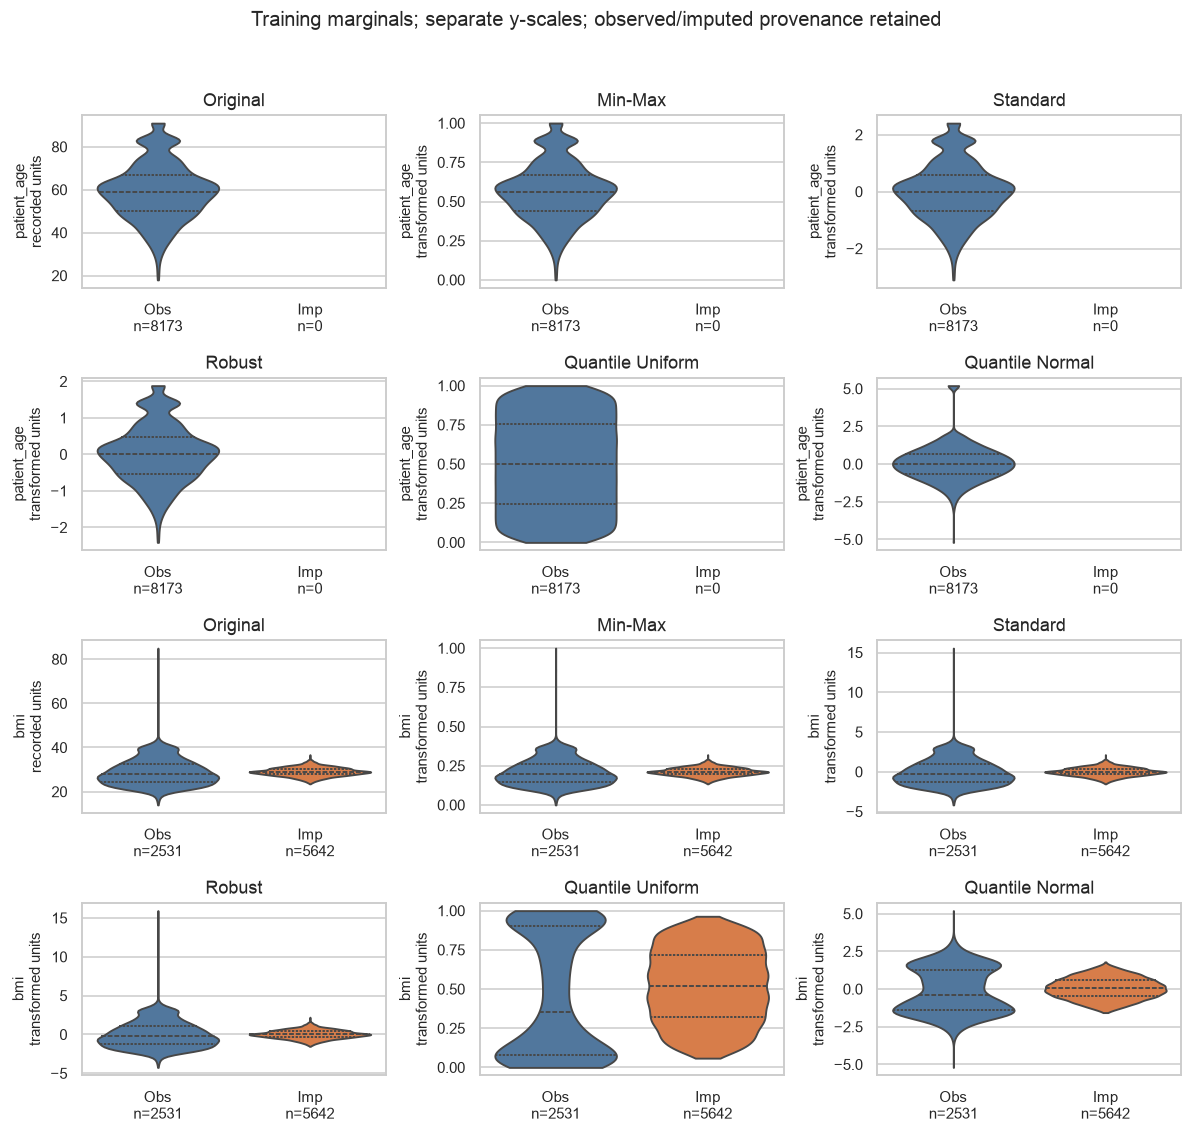

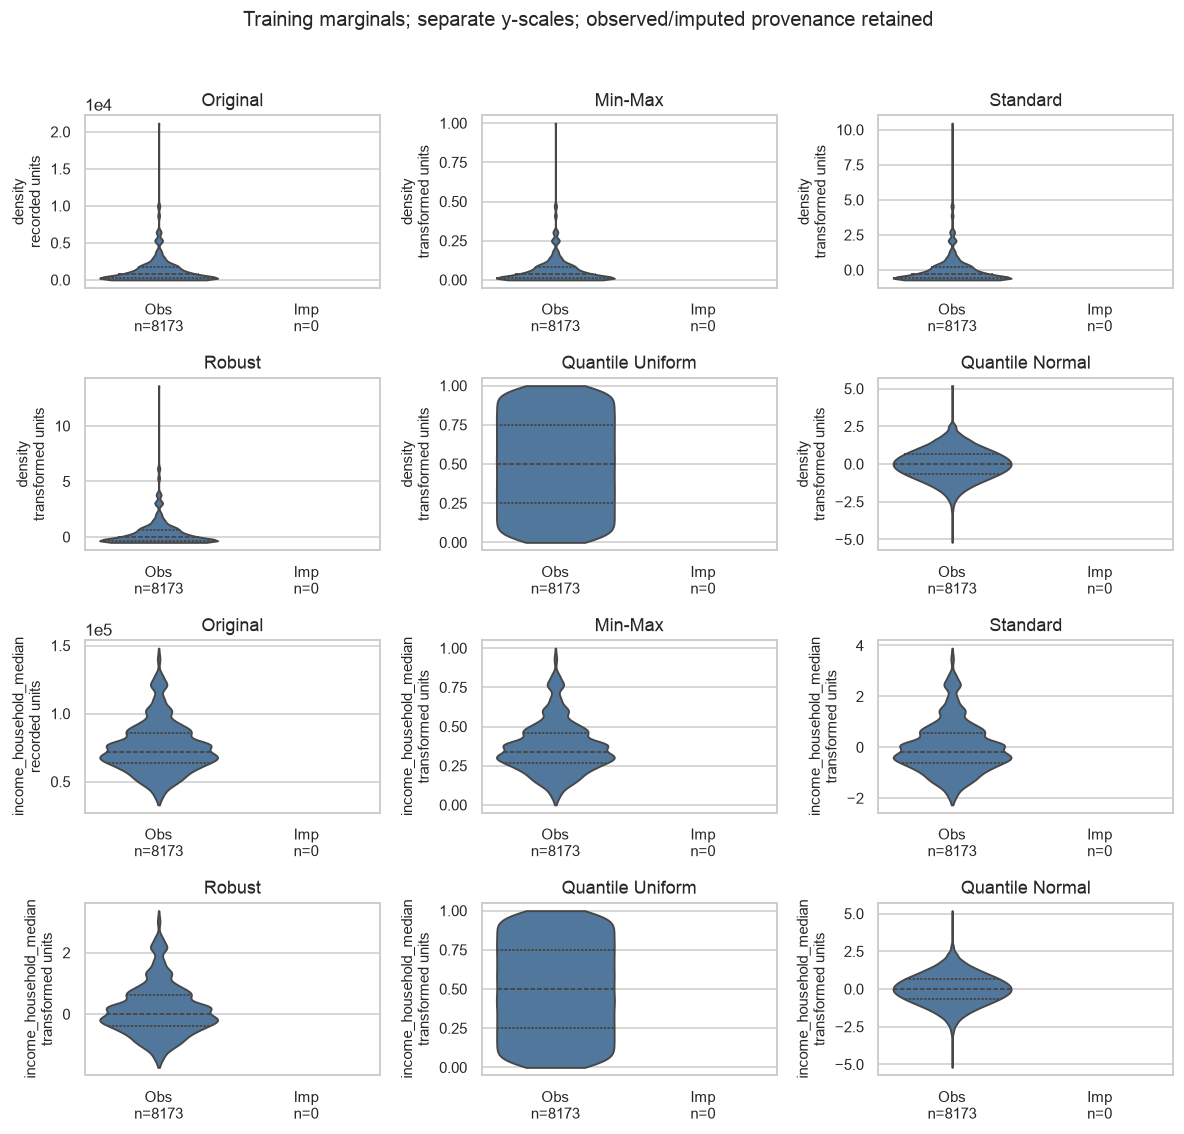

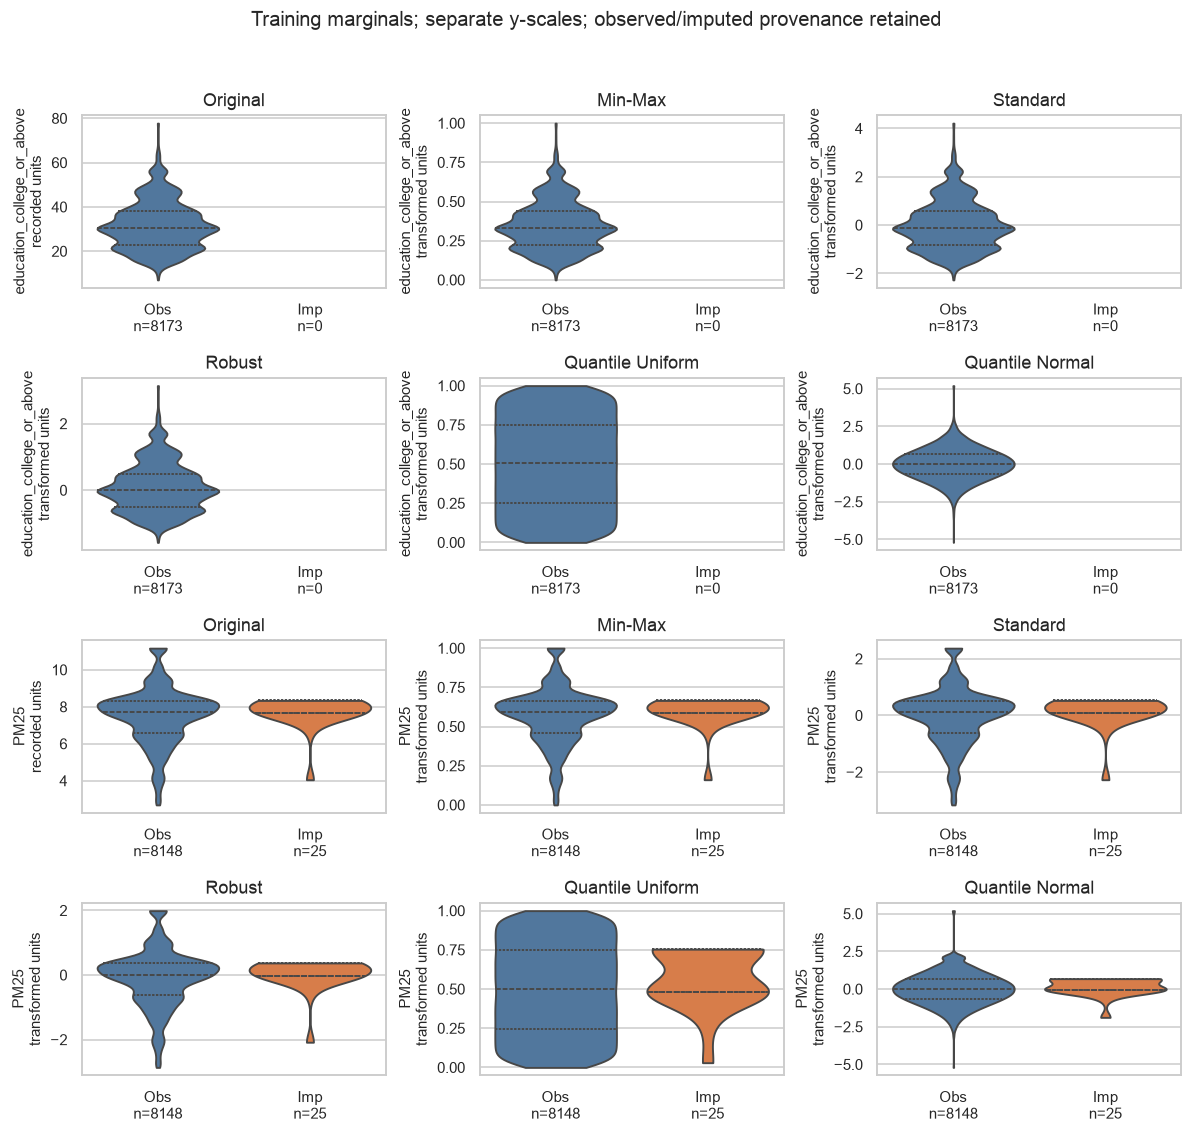

In [42]:
scaling_plot_order = ["Original", *SCALING_ORDER]
for first_feature in range(0, len(SCALING_VIOLIN_FEATURES), 2):
    features = SCALING_VIOLIN_FEATURES[first_feature:first_feature+2]
    fig, axes = plt.subplots(2*len(features), 3, figsize=(11, 10.5), squeeze=False)
    for row, feature in enumerate(features):
        provenance = np.where(outlier_common_imputed_mask[feature], "Imputed", "Observed")
        counts = pd.Series(provenance).value_counts()
        for column, name in enumerate(scaling_plot_order):
            ax = axes[2*row+column//3, column%3]
            plot_data = pd.DataFrame({"Value": scaling_frames[name][feature].to_numpy(), "Provenance": provenance})
            variable_groups = [group for group in ["Observed", "Imputed"]
                               if plot_data.loc[plot_data.Provenance.eq(group), "Value"].nunique() > 1]
            if variable_groups:
                sns.violinplot(data=plot_data[plot_data.Provenance.isin(variable_groups)],
                    x="Provenance", y="Value", hue="Provenance", order=["Observed", "Imputed"],
                    hue_order=["Observed", "Imputed"], palette={"Observed": "#4477AA", "Imputed": "#EE7733"},
                    inner="quart", cut=0, density_norm="width", common_norm=False, legend=False, ax=ax)
            for position, group in enumerate(["Observed", "Imputed"]):
                values = plot_data.loc[plot_data.Provenance.eq(group), "Value"]
                if len(values) and values.nunique() == 1:
                    ax.plot(position, values.iloc[0], marker="o", color="#4477AA" if group == "Observed" else "#EE7733")
            ax.set_xticks([0, 1], [f"Obs\nn={counts.get('Observed', 0)}", f"Imp\nn={counts.get('Imputed', 0)}"], fontsize=10)
            ax.set_title(name, fontsize=12)
            ax.set_xlabel("")
            ax.set_ylabel(f"{feature}\n"+("recorded units" if name == "Original" else "transformed units"), fontsize=10)
            ax.tick_params(axis="y", labelsize=10)
            ax.ticklabel_format(axis="y", style="sci", scilimits=(-3, 4))
    fig.suptitle("Training marginals; separate y-scales; observed/imputed provenance retained", fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, .96))
    plt.show()

## 36. Scaling recommendation, verification and handoff

**Conditional candidates, not a global winner:** StandardScaler is a transparent baseline for
scale-sensitive distances/linear regularization when mean/SD scaling is appropriate. RobustScaler
is worth evaluating when central IQR-based conditioning is preferable; its long tails remain.
Min-Max is suitable when training-range coordinates have a meaningful role, with explicit attention
to future out-of-range values. Quantile Uniform/Normal are candidates when nonlinear marginal
reshaping is acceptable, balanced against tied values, tail saturation and changed distance/Pearson
geometry. The normal option does not establish multivariate Gaussianity; the uniform option does
not make the original bounded percentages more physically meaningful.

Mechanical invariants, marginal target shape, preserving interpretable information and improving
predictions are different objectives. Earlier EDA's non-normal marginals motivate checking shape,
not automatically rejecting StandardScaler or choosing normal quantiles. No new normality study
or predictive evaluation is performed here. Existing anomaly flags remain available, with no row
removal. Imputed BMI, repeated ZIP context and unknown feature periods/units constrain interpretation.

For later model-dependent choices, refit imputation/scaling inside development folds, preserve
geographic separation and establish temporal eligibility before using the reserve after choices
are fixed. No scaling candidate is selected using validation/reserve data in this stage. Stage 05
Categorical Encoding, Feature Selection and a validated predictive pipeline remain pending.

In [43]:
scaling_recommendation = {"Adopted sample policy": "Keep all original training rows; preserve anomaly flags",
    "Scaling winner": "None declared; conditional candidates require fold-local downstream evaluation",
    "Stage 05": "Categorical Encoding remains pending", "Predictive pipeline": "Not yet validated"}
density_skews = {name: scaling_summaries[name].loc["density", "Skewness"] for name in scaling_plot_order}
bmi_observed_skew = scaling_audit.loc["bmi", "Skew observed"]
bmi_completed_skew = scaling_audit.loc["bmi", "Skew completed"]
scaling_max_normal_sd_feature = scaling_summaries["Quantile Normal"]["SD (ddof 0)"].idxmax()
scaling_max_normal_boundary_n = int(scaling_fitted_parameters.loc[scaling_max_normal_sd_feature,
    ["Uniform lower-bound N", "Uniform upper-bound N"]].sum())
scaling_bmi_original_sd = float(outlier_train_original.bmi.std(ddof=0))
scaling_bmi_imputed_sd = float(scaling_train.loc[outlier_common_imputed_mask.bmi, "bmi"].std(ddof=0))
display(HTML(pd.Series(scaling_recommendation).to_frame("Scaling conclusion").to_html()))
display(HTML(
    f"<p><strong>Computed evidence:</strong> all five methods cover {len(train_index):,} rows and {len(outlier_features)} features. "
    f"Density skewness: original={density_skews['Original']:.3f}, Min-Max={density_skews['Min-Max']:.3f}, "
    f"Standard={density_skews['Standard']:.3f}, Robust={density_skews['Robust']:.3f}, "
    f"uniform={density_skews['Quantile Uniform']:.3f}, normal={density_skews['Quantile Normal']:.3f}. "
    "Affine rescaling retains shape; quantile remapping changes its empirical shape without proving utility.</p>"
    f"<p>BMI has {int(scaling_audit.loc['bmi','Original observed N']):,} original observations and "
    f"{int(scaling_audit.loc['bmi','Imputed N']):,} imputed training cells. Observed-only skew={bmi_observed_skew:.3f}; "
    f"completed skew={bmi_completed_skew:.3f}. This documents a representation difference, not recovered missing-data truth. "
    f"For Quantile Normal, empirical feature SD ranges from {scaling_summaries['Quantile Normal']['SD (ddof 0)'].min():.4f} "
    f"to {scaling_summaries['Quantile Normal']['SD (ddof 0)'].max():.4f}; a requested normal target does not enforce exact empirical SD=1.</p>"
    f"<p>The largest Quantile Normal SD occurs for {scaling_max_normal_sd_feature}; "
    f"{scaling_max_normal_boundary_n:,}/{len(train_index):,} records map to its fitted endpoints. "
    "Repeated endpoint masses limit the target approximation and should not be called Gaussian merely because of the requested output. "
    f"BMI observed-only SD={scaling_bmi_original_sd:.3f}, versus SD={scaling_bmi_imputed_sd:.3f} among its imputed cells. "
    "The narrower estimated-value violin is not evidence that the naturally missing patients truly have lower variability; "
    "it also helps explain why separate provenance views matter after a pooled quantile transformation.</p>"))

,Scaling conclusion
Adopted sample policy,Keep all original training rows; preserve anomaly flags
Scaling winner,None declared; conditional candidates require fold-local downstream evaluation
Stage 05,Categorical Encoding remains pending
Predictive pipeline,Not yet validated


### Correctness and reproducibility checks

Independent known-value fixtures check all five transformations, constant/repeated values,
nondecreasing ordering and future values beyond fitted bounds. Quantile inverse equality is not
required. Real-data checks verify fitted training parameters, all ordered 69-column frames,
mechanical identities, affine skew/Levene invariance and deterministic quantile repeats. The
1e−10/1e−9 tolerances allow accumulated floating-point rounding, not substantive discrepancies.
Raw data, original observed values, imputation provenance, existing anomaly/KS results and both
holdouts are checked for preservation. Full earlier-stage scores are compared externally after
a fresh complete notebook run. Saved aggregate outputs support CSV-free publication; transformed
patient records are kept in memory, not printed/exported as a finalized dataset.

In [44]:
scaling_checks = {}
fixture = pd.DataFrame({"measurement": [0., 2., 4.], "constant": [7., 7., 7.]}, index=["a", "b", "c"])
fixture_before = fixture.copy(deep=True)
known_minmax = MinMaxScaler(clip=False).fit(fixture)
known_standard = StandardScaler().fit(fixture)
known_robust = RobustScaler().fit(fixture)
np.testing.assert_allclose(known_minmax.transform(fixture)[:, 0], [0, .5, 1])
np.testing.assert_allclose(known_standard.mean_, [2, 7])
np.testing.assert_allclose(known_standard.var_, [8/3, 0])
np.testing.assert_allclose(known_standard.transform(fixture)[:, 0], [-np.sqrt(1.5), 0, np.sqrt(1.5)])
np.testing.assert_allclose(known_robust.center_, [2, 7])
np.testing.assert_allclose(known_robust.scale_, [2, 1])
np.testing.assert_allclose(known_robust.transform(fixture)[:, 0], [-1, 0, 1])
for model in [known_minmax, known_standard, known_robust]:
    np.testing.assert_allclose(model.transform(fixture)[:, 1], 0)
unseen = pd.DataFrame({"measurement": [-2., 6.], "constant": [7., 7.]})
np.testing.assert_allclose(known_minmax.transform(unseen)[:, 0], [-.5, 1.5])
np.testing.assert_allclose(known_standard.transform(unseen)[:, 0], [-np.sqrt(6), np.sqrt(6)])
np.testing.assert_allclose(known_robust.transform(unseen)[:, 0], [-2, 2])
pd.testing.assert_frame_equal(fixture, fixture_before)
scaling_checks["Known affine formulas, constants and unbounded future inputs"] = True

scaling_fixture_quantiles = {}
for distribution in ["uniform", "normal"]:
    model = QuantileTransformer(n_quantiles=3, output_distribution=distribution, subsample=None, random_state=SCALING_SEED)
    transformed = model.fit_transform(fixture)
    assert model.output_distribution == distribution and np.isfinite(transformed).all()
    assert np.unique(transformed[:, 1]).size == 1  # Constant remains a mass point, not a target distribution.
    if distribution == "uniform": np.testing.assert_allclose(transformed[:, 0], [0, .5, 1])
    else:
        assert transformed[0, 0] < 0 < transformed[-1, 0]
        np.testing.assert_allclose(transformed[1, 0], 0, atol=1e-12)
    np.testing.assert_allclose(model.transform(unseen)[:, 0], transformed[[0, -1], 0])
    repeated = np.array([[0.], [1.], [1.], [2.]])
    repeated_before = repeated.copy()
    duplicate_model = QuantileTransformer(n_quantiles=4, output_distribution=distribution, subsample=None, random_state=SCALING_SEED)
    duplicate_result = duplicate_model.fit_transform(repeated)
    assert np.isfinite(duplicate_result).all() and duplicate_result[1, 0] == duplicate_result[2, 0]
    assert (np.diff(duplicate_result[:, 0]) >= 0).all()
    np.testing.assert_array_equal(repeated, repeated_before)
    scaling_fixture_quantiles[distribution] = transformed.tolist()
pd.testing.assert_frame_equal(fixture, fixture_before)
scaling_checks["Quantile modes, ties/constants, monotonicity, finite tail saturation and input preservation"] = True

known_levene = scaling_levene_diagnostic([0, 1, 2, 3], [0, 2, 4, 6], min_group_n=2)
np.testing.assert_allclose(known_levene["Levene W"], 2.4)
assert np.isnan(scaling_levene_diagnostic([1], [2])["Levene W"])
assert "constant group" in scaling_levene_diagnostic([1]*20, list(range(20)))["Status"]
assert "centered deviations" in scaling_levene_diagnostic([0, 1], [2, 3], min_group_n=2)["Status"]
scaling_checks["Known median-Levene W=2.4 and insufficient/constant/degenerate-group handling"] = True

assert list(scaling_models) == SCALING_ORDER and list(scaling_frames) == ["Original", *SCALING_ORDER]
assert len(scaling_full_summary) == 6*len(outlier_features)
for name, frame in scaling_frames.items():
    assert frame.index.equals(train_index) and frame.columns.equals(scaling_train.columns)
    assert frame.shape == scaling_train.shape and np.isfinite(frame.to_numpy()).all()
    assert scaling_summaries[name].N.eq(len(train_index)).all()
    # Sort each original feature; every transform must be nondecreasing (ties allowed).
    order = np.argsort(scaling_train.to_numpy(), axis=0, kind="stable")
    ordered = np.take_along_axis(frame.to_numpy(), order, axis=0)
    assert (np.diff(ordered, axis=0) >= -1e-10).all()
    if name != "Original":
        assert scaling_models[name].n_features_in_ == len(outlier_features)
        np.testing.assert_array_equal(scaling_models[name].feature_names_in_, outlier_features)
for name in ["Min-Max", "Quantile Uniform"]:
    assert scaling_frames[name].to_numpy().min() >= -1e-10 and scaling_frames[name].to_numpy().max() <= 1+1e-10
np.testing.assert_allclose(scaling_models["Min-Max"].data_min_, scaling_train.min(), rtol=0, atol=1e-10)
np.testing.assert_allclose(scaling_models["Min-Max"].data_max_, scaling_train.max(), rtol=0, atol=1e-10)
np.testing.assert_allclose(scaling_models["Standard"].mean_, scaling_train.mean(), rtol=1e-12, atol=1e-10)
np.testing.assert_allclose(scaling_models["Standard"].var_, scaling_train.var(ddof=0), rtol=1e-12, atol=1e-10)
assert scaling_models["Standard"].n_samples_seen_ == len(train_index)
assert scaling_models["Min-Max"].n_samples_seen_ == len(train_index)
np.testing.assert_allclose(scaling_models["Robust"].center_, scaling_train.median(), rtol=0, atol=1e-10)
positive_iqr = scaling_summaries["Original"].IQR.gt(10*np.finfo(float).eps)
np.testing.assert_allclose(scaling_models["Robust"].scale_[positive_iqr], scaling_summaries["Original"].IQR[positive_iqr], rtol=1e-12)
assert scaling_property_errors.dropna().lt(1e-9).all()
scaling_checks["Five complete aligned finite transformations, monotonicity, fitted train parameters and mechanical invariants"] = True

uniform_model = scaling_models["Quantile Uniform"]
normal_model = scaling_models["Quantile Normal"]
np.testing.assert_array_equal(uniform_model.quantiles_, normal_model.quantiles_)
np.testing.assert_array_equal(uniform_model.references_, np.linspace(0, 1, SCALING_N_QUANTILES))
np.testing.assert_allclose(uniform_model.quantiles_, np.percentile(scaling_train, uniform_model.references_*100, axis=0), rtol=1e-12, atol=1e-10)
for name in ["Quantile Uniform", "Quantile Normal"]:
    model = scaling_models[name]
    assert model.subsample is None and model.random_state == SCALING_SEED
    repeated_model = QuantileTransformer(**model.get_params())
    repeated_values = repeated_model.fit_transform(scaling_train)
    np.testing.assert_array_equal(repeated_values, scaling_frames[name].to_numpy())
del repeated_model, repeated_values
scaling_checks["Full-training fitted quantile grids and exact fixed-settings repeat for both outputs"] = True

for name in ["Min-Max", "Standard", "Robust"]:
    if pd.notna(scaling_levene.loc["Original", "Levene W"]):
        np.testing.assert_allclose(scaling_levene.loc[name, ["Levene W", "Nominal p (ZIP dependence)"]].to_numpy(dtype=float),
            scaling_levene.loc["Original", ["Levene W", "Nominal p (ZIP dependence)"]].to_numpy(dtype=float), rtol=1e-9, atol=1e-10)
assert int(scaling_bmi_observed.sum()) == int(outlier_train_original.bmi.count())
scaling_checks["Same observed-only BMI groups and affine Levene invariance"] = True

pd.testing.assert_frame_equal(scaling_train, outlier_common_train_raw)
assert hashlib.sha256(pd.util.hash_pandas_object(scaling_train, index=True).to_numpy().tobytes()).hexdigest() == scaling_input_hash
pd.testing.assert_frame_equal(outlier_common_imputed_mask, outlier_original_missing)
pd.testing.assert_frame_equal(scaling_train.where(~outlier_common_imputed_mask), outlier_train_original)
pd.testing.assert_frame_equal(stage03_ks_results, scaling_prior_ks)
assert hashlib.sha256(pd.util.hash_pandas_object(all_outlier_flags, index=True).to_numpy().tobytes()).hexdigest() == scaling_prior_flag_hash
assert hashlib.sha256(pd.util.hash_pandas_object(df, index=True).to_numpy().tobytes()).hexdigest() == frame_hash_before
for name, index in {"Validation": validation_index, "Reserved": reserved_index}.items():
    assert hashlib.sha256(pd.util.hash_pandas_object(df.loc[index], index=True).to_numpy().tobytes()).hexdigest() == outlier_holdout_hashes[name]
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == raw_sha_before
assert df.shape == (12906, 83) and set(scaling_train.columns).isdisjoint(forbidden)
assert stage03_adopted_training_rows.equals(train_index)
scaling_checks["Raw/schema, complete train data, original observations/provenance, prior Stage 03 and holdouts unchanged"] = True
display(pd.Series(scaling_checks, name="PASS").to_frame())
print(f"Stage 04 complete: {len(scaling_models)} scaling configurations; {len(scaling_train)} x {len(outlier_features)} common input; {len(scaling_full_summary)} feature/representation summaries.")
print("No global predictive winner. Stage 05 Categorical Encoding can proceed as a separate controlled experiment.")

,PASS
"Known affine formulas, constants and unbounded future inputs",True
"Quantile modes, ties/constants, monotonicity, finite tail saturation and input preservation",True
Known median-Levene W=2.4 and insufficient/constant/degenerate-group handling,True
"Five complete aligned finite transformations, monotonicity, fitted train parameters and mechanical invariants",True
Full-training fitted quantile grids and exact fixed-settings repeat for both outputs,True
Same observed-only BMI groups and affine Levene invariance,True
"Raw/schema, complete train data, original observations/provenance, prior Stage 03 and holdouts unchanged",True


Stage 04 complete: 5 scaling configurations; 8173 x 69 common input; 414 feature/representation summaries.
No global predictive winner. Stage 05 Categorical Encoding can proceed as a separate controlled experiment.
